In [1]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

And we get backend information.

In [3]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_brisbane")
dt = backend.configuration().dt * ns

# original duration was 120 dt, we take multiples of this
desired_duration = 480  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 480)

Then we load our robust gateset.

In [4]:
# pico_a = ps.from_csv(
#     "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
# )
# pico_a = ps.from_csv("../pico-pulses/saved-pulses-2024-09-02/gateset.csv")
# pico_a = ps.from_csv("../pico-pulses/saved-pulses-2024-10-19/pulses.csv", delimiter="\t")
pico_a = ps.from_csv("../pico-pulses/saved-pulses-2024-10-23/pulses.csv", delimiter="\t")

pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2", "i2"], pico_a)}

# # only dephasing
# pico_a = ps.from_csv("../pico-pulses/dephasing-pulses/pulses.csv", delimiter=",")
# pico_gates = {key: row for key, row in zip(["x1", "sx1"], pico_a)}
# pico_gates["x2"] = pico_gates["x1"]
# pico_gates["sx2"] = pico_gates["sx1"]

In [5]:
pico_gates["i1"] = np.array(len(pico_gates["x1"]) * [0])
pico_gates["i2"] = np.array(len(pico_gates["x1"]) * [0])

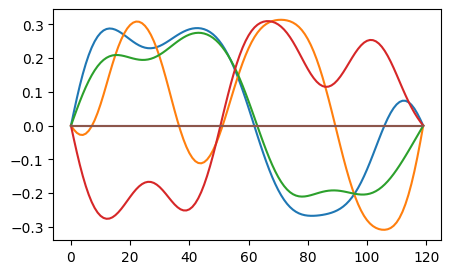

In [6]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_gates.values():
    ax.plot(row)

In [7]:
np.trapz(pico_gates["x1"], dx=dt) / np.pi, np.trapz(pico_gates["x2"], dx=dt) / np.pi

(0.9999999999999999, 1.0000000000000013)

In [8]:
np.trapz(pico_gates["sx1"], dx=dt) / np.pi, np.trapz(pico_gates["sx2"], dx=dt) / np.pi

(0.4999999999999995, 0.5000000000000001)

In [9]:
np.trapz(pico_gates["i2"], dx=dt) / np.pi

0.0

And we define a Guassian gateset to which we are going to compare.

In [10]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
}

The maximum aplitude allowed by qiskit pulse is the `amp` factor times the amplitude of the signal we are sending.

In [11]:
signal = pico_gates["x1"]
x1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx1"]
sx1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x1_max, sx1_max)
print(1 / x1_max, 1 / sx1_max)

0.07227570031831072 0.06882165803070459
13.835908826837814 14.530309623663133


In [12]:
signal = pico_gates["x2"]
x2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx2"]
sx2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x2_max, sx2_max)
print(1 / x2_max, 1 / sx2_max)

0.07845678343858903 0.07742958920986918
12.745870480182715 12.91495938703159


In [13]:
# signal = pico_gates["i2"]
# i2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

# print(i2_max)
# print(1 / i2_max)

So we can bump up the `drive_amps` closer to -3 and 3.

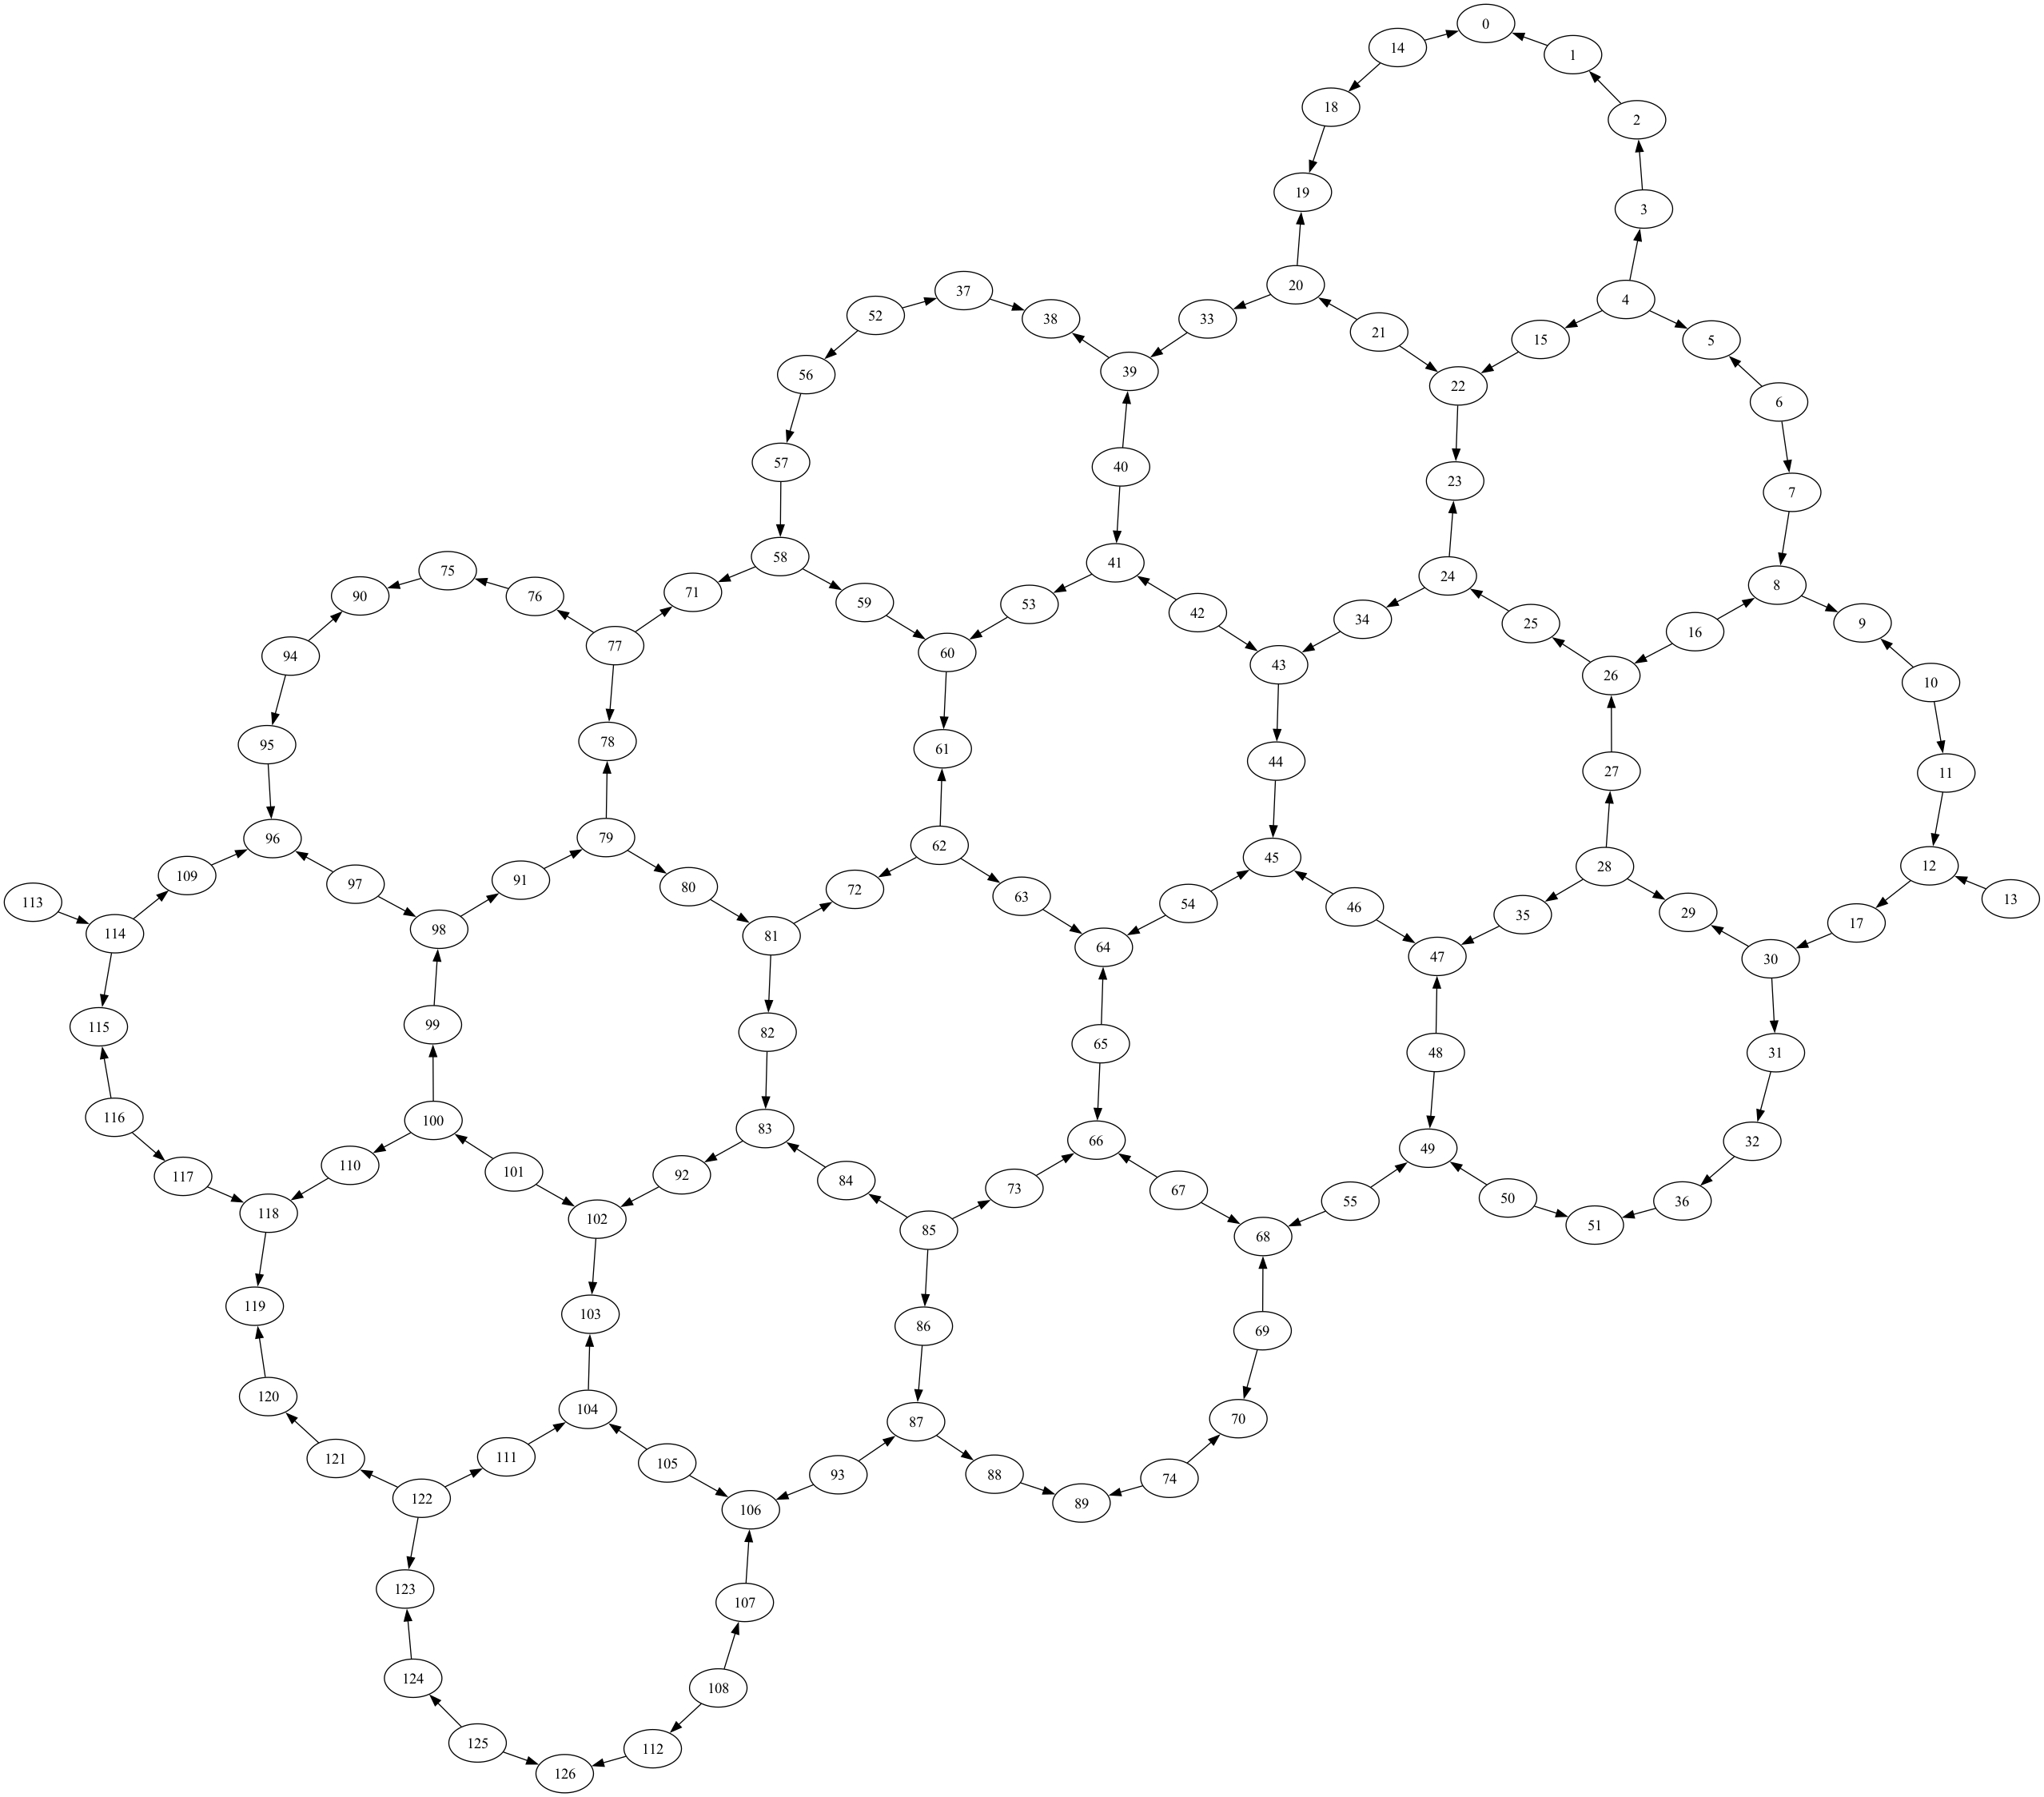

In [ ]:
backend.coupling_map.draw()

## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [16]:
qubit0, qubit1 = 18, 14
qubit2, qubit3 = 0, 1
qubit4, qubit5 = 8, 9
qubit6, qubit7 = 10, 11

x_drive_amps = np.linspace(-2.5, 2.5, 50)
x_low_drive_amps = np.linspace(-1.2, 1.2, 50)
sx_drive_amps = np.linspace(-4, 4, 50)
sx_low_drive_amps = np.linspace(-2, 2, 50)

x_drive_amps_gaussian = np.linspace(-4, 4, 50)
sx_drive_amps_gaussian = np.linspace(-5.5, 5.5, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [17]:
def get_schedules(signal, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"rabi_sched", backend=backend) as sched:
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, "custom", amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [18]:
robust_x1_schedules = get_schedules(pico_gates["x1"], qubit0, x_drive_amps)

We do the same for the Gaussian pulses.

In [19]:
gaussian_x1_schedules = get_schedules(default_gates["x1"].samples, qubit0, x_drive_amps)

We can use the schedules to create circuits that we can run to IBM.

In [20]:
num_qubits = backend.num_qubits
num_qubits

127

In [27]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for i, schedule in enumerate(schedules):
        gate = qk.circuit.Gate(f"x_rabi", 1, [])
        cr = qk.ClassicalRegister(1, name="c")
        qr = qk.QuantumRegister(num_qubits, name="q")
        qc = qk.QuantumCircuit(qr, cr, name=f"schedule")
        qc.append(gate, [qubit])
        qc.measure(qubit, cr[0])
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [28]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x1_circuits[0].draw(idle_wires=False)

┌────────┐┌─┐
q_18: ┤ x_rabi ├┤M├
      └────────┘└╥┘
 c: 1/═══════════╩═
                 0

We can parallelize our calibration by running circuits that act on different qubits at the same time. So, we can calibrate both x gates in parallel, and both sx gates in parallel. We can also do more qubit pairs.

In [29]:
def construct_parallel_circuits(qubits: list[int], signals, drive_amps_list: list[list[float]], num_qubits: int):
    assert len(qubits) == len(signals)

    qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(len(drive_amps_list[0]))]
    crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(len(drive_amps_list[0]))]
    qcs = [qk.QuantumCircuit(qrs[i], crs[i]) for i in range(len(drive_amps_list[0]))]

    for i, (qubit, signal) in enumerate(zip(qubits, signals)):
        schedules = get_schedules(signal, qubit, drive_amps_list[i])
        circuits = get_circuits_from_scheds(schedules, num_qubits, qubit)
        
        for j, (qc, circuit) in enumerate(zip(qcs, circuits)):
            qc.append(circuit, qargs=qrs[j], cargs=(crs[j][i],))

            # have to add calibrations to new circuit
            gate = qk.circuit.Gate("x_rabi", 1, [])
            qc.add_calibration(gate, (qubit,), schedules[j])

    return [qc.decompose() for qc in qcs]

In [145]:
qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5, qubit6, qubit7]
# qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5]
# qubits = [qubit0, qubit1, qubit2, qubit3]

In [31]:
x_signals = [pico_gates["x1"], pico_gates["x2"]] * 4
sx_signals = [pico_gates["sx1"], pico_gates["sx2"]] * 4
# i_signals = [pico_gates["i2"]] * 2

x_parallel_circuits = construct_parallel_circuits(qubits, x_signals, [x_drive_amps] * 8, num_qubits)
sx_parallel_circuits = construct_parallel_circuits(qubits, sx_signals, [sx_drive_amps] * 8, num_qubits)
# i_parallel_circuits = construct_parallel_circuits([qubit for i, qubit in enumerate(qubits) if i % 2 != 0], i_signals, [x_drive_amps] * 2, num_qubits)

In [33]:
x_signals_gaussian = [default_gates["x1"].samples, default_gates["x2"].samples] * 2
sx_signals_gaussian = [default_gates["sx1"].samples, default_gates["sx2"].samples] * 2

x_parallel_circuits_gaussian = construct_parallel_circuits(qubits, x_signals_gaussian, [x_drive_amps_gaussian] * 4, num_qubits)
sx_parallel_circuits_gaussian = construct_parallel_circuits(qubits, sx_signals_gaussian, [sx_drive_amps_gaussian] * 4, num_qubits)

AssertionError: 

In [34]:
x_parallel_circuits[3].draw(idle_wires=False)

┌────────┐      ┌─┐               
 q_0: ┤ x_rabi ├──────┤M├───────────────
      ├────────┤      └╥┘┌─┐            
 q_1: ┤ x_rabi ├───────╫─┤M├────────────
      ├────────┤       ║ └╥┘┌─┐         
 q_8: ┤ x_rabi ├───────╫──╫─┤M├─────────
      ├────────┤       ║  ║ └╥┘┌─┐      
 q_9: ┤ x_rabi ├───────╫──╫──╫─┤M├──────
      ├────────┤       ║  ║  ║ └╥┘┌─┐   
q_10: ┤ x_rabi ├───────╫──╫──╫──╫─┤M├───
      ├────────┤       ║  ║  ║  ║ └╥┘┌─┐
q_11: ┤ x_rabi ├───────╫──╫──╫──╫──╫─┤M├
      ├────────┤   ┌─┐ ║  ║  ║  ║  ║ └╥┘
q_14: ┤ x_rabi ├───┤M├─╫──╫──╫──╫──╫──╫─
      ├────────┤┌─┐└╥┘ ║  ║  ║  ║  ║  ║ 
q_18: ┤ x_rabi ├┤M├─╫──╫──╫──╫──╫──╫──╫─
      └────────┘└╥┘ ║  ║  ║  ║  ║  ║  ║ 
 c: 8/═══════════╩══╩══╩══╩══╩══╩══╩══╩═
                 0  1  2  3  4  5  6  7

So, as you can see above, we parallelize the rough calibration by running circuits of the form above (we omit idle wires in the drawing to save space).

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [ ]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: cxzxy38rta1g0086ka70


In [ ]:
sampler = Sampler(backend=backend, session=session)
sampler.options.experimental = {"execution": {"fast_parametric_update": False}} # make sure pulse instructions are sent correctly

In [119]:
num_shots_per_point = 1024

In [141]:
x_parallel_jobs = sampler.run(x_parallel_circuits, shots=num_shots_per_point)
sx_parallel_jobs = sampler.run(sx_parallel_circuits, shots=num_shots_per_point)
# i_parallel_jobs = sampler.run(i_parallel_circuits, shots=num_shots_per_point)

# x_parallel_jobs_gaussian = sampler.run(x_parallel_circuits_gaussian, shots=num_shots_per_point)
# sx_parallel_jobs_gaussian = sampler.run(sx_parallel_circuits_gaussian, shots=num_shots_per_point)

In [ ]:
# print(x_parallel_jobs_gaussian.job_id(), sx_parallel_jobs_gaussian.job_id())
# print(x_parallel_jobs_gaussian.status(), sx_parallel_jobs_gaussian.status())

In [227]:
print(x_parallel_jobs.job_id(), sx_parallel_jobs.job_id())#, i_parallel_jobs.job_id())
print(x_parallel_jobs.status(), sx_parallel_jobs.status())#, i_parallel_jobs.status())

cxzxy509b62g008h3sng cxzxy5rcw2k0008jbwt0
DONE DONE


In [58]:
# x_parallel_jobs.job_id(), sx_parallel_jobs.job_id()

In [37]:
x_parallel_jobs_gaussian.job_id(), sx_parallel_jobs_gaussian.job_id()

('cws69ed60bqg008panjg', 'cws69ex997wg008xh6t0')

In [60]:
# x_parallel_jobs.status(), sx_parallel_jobs.status()

In [ ]:
x_parallel_jobs_gaussian.status(), sx_parallel_jobs_gaussian.status()

In [110]:
x_parallel_jobs = service.job("cxzxy509b62g008h3sng")
sx_parallel_jobs = service.job("cxzxy5rcw2k0008jbwt0")

In [111]:
x_parallel_jobs_gaussian = service.job("cws69ed60bqg008panjg")
sx_parallel_jobs_gaussian = service.job("cws69ex997wg008xh6t0")

We define the functions that will help us analyze the calibration data.

In [112]:
def get_qubit_one_counts(counts, qubit, num_qubits):
    total = 0
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] == "1": # because of little-endian
            total += val
    return total

In [113]:
def get_rabi_values(job, shots, qubits, tag = False):
    rabi_values = [[] for _ in range(len(qubits))] # each list element is the data for a single qubit
    result = job.result()
    for i in range(len(result)):
        if not tag:
            counts = result[i]["__value__"]["data"].c.get_counts()
        else:
            counts = result[i].data.c.get_counts(tag)
        for j in range(len(qubits)):
            rabi_values[j].append(get_qubit_one_counts(counts, j, len(qubits)) / shots)
    return rabi_values

In [120]:
x_rabi_values = get_rabi_values(x_parallel_jobs, num_shots_per_point, qubits)
sx_rabi_values = get_rabi_values(sx_parallel_jobs, num_shots_per_point, qubits)
# i_rabi_values = get_rabi_values(i_parallel_jobs, num_shots_per_point, [qubit for i, qubit in enumerate(qubits) if i % 2 != 0])

In [121]:
x_rabi_values_gaussian = get_rabi_values(x_parallel_jobs_gaussian, num_shots_per_point, qubits)
sx_rabi_values_gaussian = get_rabi_values(sx_parallel_jobs_gaussian, num_shots_per_point, qubits)

In [122]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [123]:
def get_drive_period(
    rabi_values: list[float], 
    drive_amps: list[float], 
    target_angle: float,
    gate_name: str = "",
    plot: bool = False, 
    qubit: int = 0,
    amplitude_max: float = 1,
    normal_params: bool = True,
    plot_save = True,
    plot_name = "default_name"
):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(rabi_values)
    
    starting_params = [0.2] if normal_params else [0.4]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, f: (
            0.5 * (1 - np.cos(2 * np.pi * x * f))
        ),
        starting_params,
    )

    freq = fit_params[0]  # get period of rabi oscillation
    
    if plot:
        plot_amps = amplitude_max * np.array(drive_amps)
        # plot_amps = np.array(drive_amps)
        plt.scatter(plot_amps, rabi_values, marker="x", color="black")
        plt.plot(plot_amps, y_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1")
        plt.title(f"{gate_name} calibration on qubit {qubit}")
        # plt.show()
        
        if plot_save:
            plt.savefig(f"{plot_name}.pdf", format="pdf", dpi=300, bbox_inches="tight")
        else:
            plt.show()

    return target_angle / (2 * np.pi * freq)

And we get the estimated amplitudes.

In [124]:
np.max(pico_gates["x1"])

0.2891028012732429

1.6401650361386073

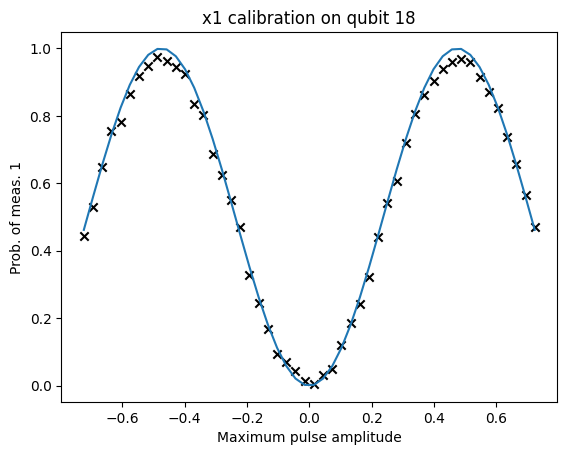

In [125]:
get_drive_period(x_rabi_values[0], x_drive_amps, target_angle=np.pi, amplitude_max=np.max(pico_gates["x1"]), plot=True, qubit=qubits[0], plot_save=True, gate_name="x1", plot_name="rough_calibration")

In [126]:
with open("good_calibration.txt", "w") as file:
    file.write(", ".join(map(str, x_rabi_values[0])))
    file.write("\n")
    file.write(", ".join(map(str, x_drive_amps)))

In [1222]:
bad_calibration = service.job("cqwc30m6jg50008nhkj0")

In [1223]:
bad_result = bad_calibration.result()

In [1240]:
bad_drive_amps = np.linspace(-1.2, 1.2, 50)
bad_rabi_data = []
for i in range(len(bad_drive_amps)):
    prob1 = bad_result.get_counts(i)["1"] / 1024
    bad_rabi_data.append(prob1)

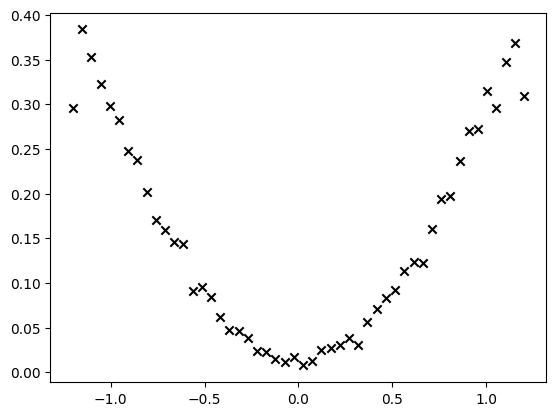

In [1241]:
plt.scatter(bad_drive_amps, bad_rabi_data, marker="x", color="black")

In [1229]:
with open("bad_calibration.txt", "w") as file:
    file.write(", ".join(map(str, bad_rabi_data)))
    file.write("\n")
    file.write(", ".join(map(str, bad_drive_amps)))

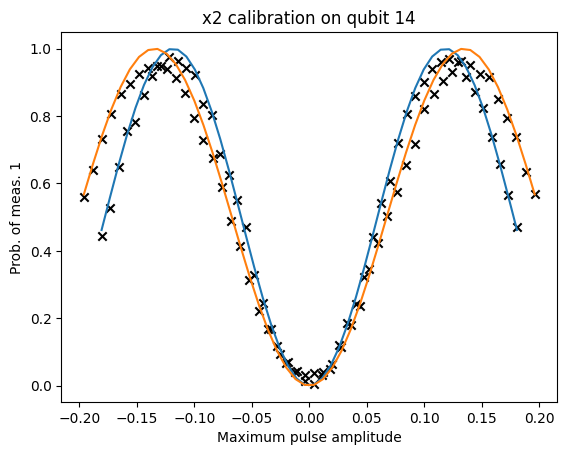

In [129]:
x_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values)):
    x_rough_amps.append(get_drive_period(
        rabi,
        x_drive_amps,
        target_angle=np.pi,
        gate_name=f"x{i % 2 + 1}",
        plot=True, 
        qubit=qubit, 
        amplitude_max= x1_max if i % 2 == 0 else x2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))

In [130]:
x_rough_amps

[1.6401650361386073, 1.7158490321758468]

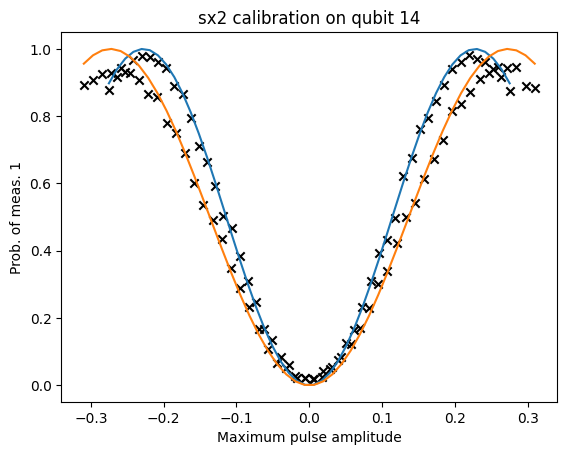

In [131]:
sx_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values)):
    sx_rough_amps.append(get_drive_period(
        rabi, 
        sx_drive_amps, 
        target_angle=np.pi / 2,
        gate_name=f"sx{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))


In [132]:
sx_rough_amps

[1.6566806631561832, 1.7631696756565942]

In [ ]:
i_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, i_rabi_values)):
    i_rough_amps.append(get_drive_period(
        rabi, 
        sx_drive_amps, 
        target_angle=2 * np.pi,
        gate_name=f"i{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        normal_params=False,  
    ))


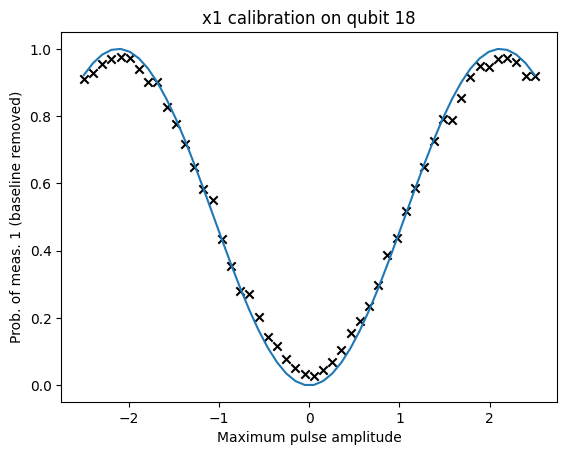

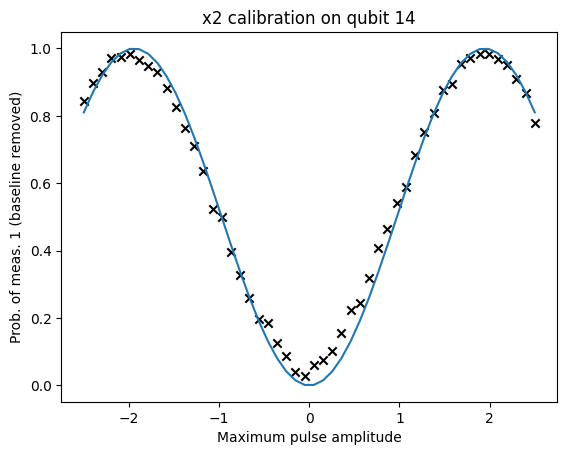

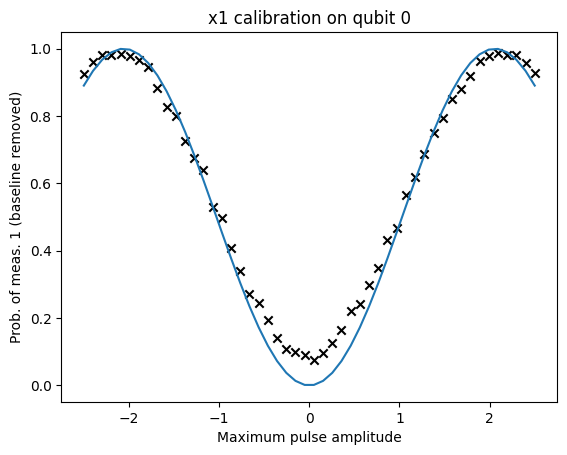

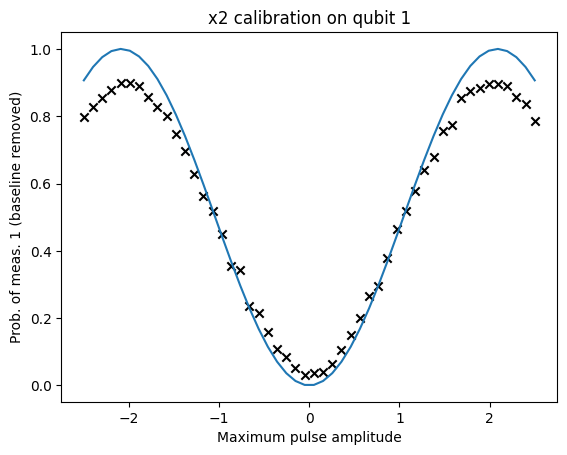

[2.1180523041205794, 5.828336418377357, 2.0580427614322097, 6.26178990680414]

In [44]:
x_rough_amps_gaussian = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values_gaussian)):
    x_rough_amps_gaussian.append(get_drive_period(
        rabi, 
        x_drive_amps, 
        target_angle=np.pi if i % 2 == 0 else 3 * np.pi,
        gate_name=f"x{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        # amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))
x_rough_amps_gaussian

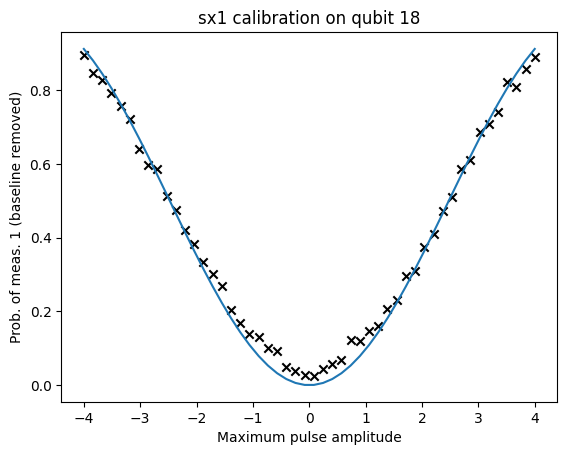

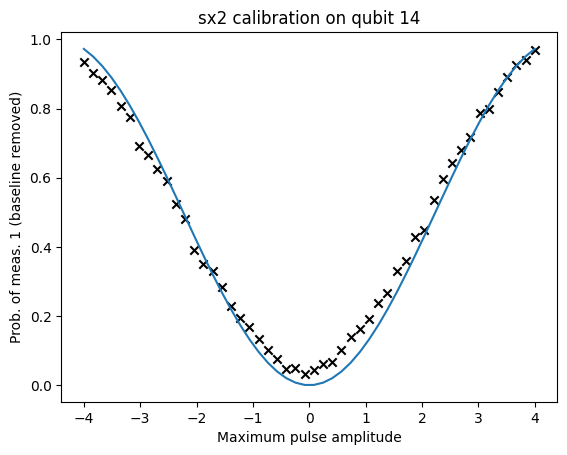

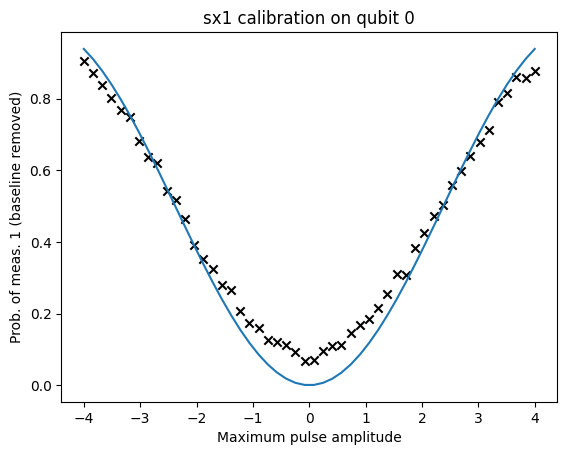

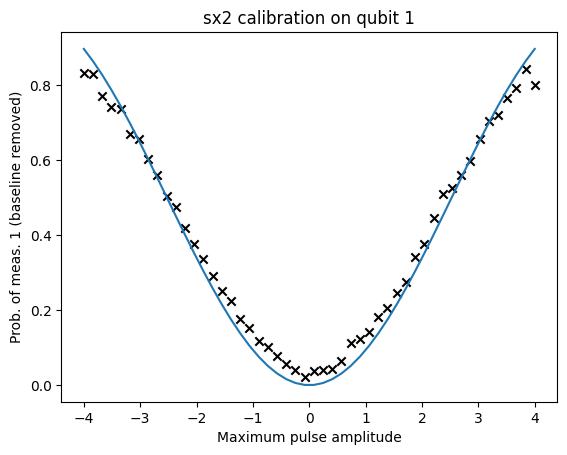

[2.4752034492066235, 2.236242072224629, 2.3781261580369497, 2.524438307604473]

In [45]:
sx_rough_amps_gaussian = []
for i, (qubit, rabi) in enumerate(zip(qubits, sx_rabi_values_gaussian)):
    sx_rough_amps_gaussian.append(get_drive_period(
        rabi, 
        sx_drive_amps, 
        target_angle=np.pi / 2,
        gate_name=f"sx{i % 2 + 1}", 
        plot=True, 
        qubit=qubit,
        # amplitude_max= sx1_max if i % 2 == 0 else sx2_max,
        # normal_params=True if i % 2 == 0 else False,  
    ))
sx_rough_amps_gaussian

In [238]:
for i, (qubit, amp) in enumerate(zip(qubits, x_rough_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amp: {amp}")

Qubit 18 x1 gate amp: 1.7082591704177799
Qubit 14 x2 gate amp: 1.58192909747541
Qubit 0 x1 gate amp: 1.7351998685501377
Qubit 1 x2 gate amp: 1.632957670463991
Qubit 8 x1 gate amp: 1.5228885223448496
Qubit 9 x2 gate amp: 1.6169623951268097
Qubit 10 x1 gate amp: 1.6401650361386073
Qubit 11 x2 gate amp: 1.7158490321758468


In [239]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_rough_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amp: {amp}")

Qubit 18 sx1 gate amp: 1.7289471651674022
Qubit 14 sx2 gate amp: 1.600457333341054
Qubit 0 sx1 gate amp: 1.7117042652199854
Qubit 1 sx2 gate amp: 1.6218961235017049
Qubit 8 sx1 gate amp: 1.517798292519146
Qubit 9 sx2 gate amp: 1.604131096010949
Qubit 10 sx1 gate amp: 1.6566806631561832
Qubit 11 sx2 gate amp: 1.7631696756565942


In [ ]:
for i, (qubit, amp) in enumerate(zip([qubit for i, qubit in enumerate(qubits) if i % 2 != 0], i_rough_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amp: {amp}")

In [241]:
for i, (x_period, sx_period) in enumerate(zip(x_rough_amps, sx_rough_amps)):
    print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_period / x_period)

Ratio of sx1 to x1 on qubit 18: 1.012110571456533
Ratio of sx2 to x2 on qubit 14: 1.0117124312936736
Ratio of sx1 to x1 on qubit 0: 0.9864594253630365
Ratio of sx2 to x2 on qubit 1: 0.9932260663198066
Ratio of sx1 to x1 on qubit 8: 0.9966575164557245
Ratio of sx2 to x2 on qubit 9: 0.9920645655368785
Ratio of sx1 to x1 on qubit 10: 1.0100694909680907
Ratio of sx2 to x2 on qubit 11: 1.0275785588320323


## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [37]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [38]:
def get_fine_experiment(sched, qubit: int, gate: str, backend, x_gate: bool = True):
    inst_map = qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    if x_gate:
        exp = qk_e.library.FineXAmplitude((qubit,), backend)
    else:
        exp = qk_e.library.FineSXAmplitude((qubit,), backend)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

We know construct the fine amplitude experiments.

In [ ]:
fine_x_experiments = []
fine_sx_experiments = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals)):
    sched = build_schedule(signal, qubit, x_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals)):
    sched = build_schedule(signal, qubit, sx_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
    fine_sx_experiments.append(exp)

In [ ]:
fine_x_experiments_gaussian = []
fine_sx_experiments_gaussian = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals_gaussian)):
    sched = build_schedule(signal, qubit, x_rough_amps_gaussian[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments_gaussian.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals_gaussian)):
    sched = build_schedule(signal, qubit, sx_rough_amps_gaussian[i])
    exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
    fine_sx_experiments_gaussian.append(exp)

And parallelize them like we did with the rough calibration circuits.

In [552]:
x_num_circuits = len(fine_x_experiments[0].circuits())
x_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits = [qk.QuantumCircuit(x_qrs[i], x_crs[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments[0].circuits())
sx_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits = [qk.QuantumCircuit(sx_qrs[i], sx_crs[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits = fine_x_experiments[i].circuits()
    sx_circuits = fine_sx_experiments[i].circuits()

    x_schedule = build_schedule(x_signals[i], qubit, x_rough_amps[i])
    sx_schedule = build_schedule(sx_signals[i], qubit, sx_rough_amps[i])

    for j in range(x_num_circuits):
        fine_x_circuits[j].append(x_circuits[j], qargs=(x_qrs[j][qubit],), cargs=(x_crs[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits[j].add_calibration(gate, (qubit,), x_schedule)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits[j].append(sx_circuits[j], qargs=(sx_qrs[j][qubit],), cargs=(sx_crs[j][i],))
        gate = qk.circuit.library.SXGate()
        fine_sx_circuits[j].add_calibration(gate, (qubit,), sx_schedule)

fine_x_circuits = [circuit.decompose() for circuit in fine_x_circuits]
fine_sx_circuits = [circuit.decompose() for circuit in fine_sx_circuits]

In [553]:
fine_x_circuits[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐      ┌─┐               
 q_0: ┤ √X ├┤ X ├┤ X ├──────┤M├───────────────
      ├────┤├───┤├───┤      └╥┘┌─┐            
 q_1: ┤ √X ├┤ X ├┤ X ├───────╫─┤M├────────────
      ├────┤├───┤├───┤       ║ └╥┘┌─┐         
 q_8: ┤ √X ├┤ X ├┤ X ├───────╫──╫─┤M├─────────
      ├────┤├───┤├───┤       ║  ║ └╥┘┌─┐      
 q_9: ┤ √X ├┤ X ├┤ X ├───────╫──╫──╫─┤M├──────
      ├────┤├───┤├───┤       ║  ║  ║ └╥┘┌─┐   
q_10: ┤ √X ├┤ X ├┤ X ├───────╫──╫──╫──╫─┤M├───
      ├────┤├───┤├───┤       ║  ║  ║  ║ └╥┘┌─┐
q_11: ┤ √X ├┤ X ├┤ X ├───────╫──╫──╫──╫──╫─┤M├
      ├────┤├───┤├───┤   ┌─┐ ║  ║  ║  ║  ║ └╥┘
q_14: ┤ √X ├┤ X ├┤ X ├───┤M├─╫──╫──╫──╫──╫──╫─
      ├────┤├───┤├───┤┌─┐└╥┘ ║  ║  ║  ║  ║  ║ 
q_18: ┤ √X ├┤ X ├┤ X ├┤M├─╫──╫──╫──╫──╫──╫──╫─
      └────┘└───┘└───┘└╥┘ ║  ║  ║  ║  ║  ║  ║ 
 c: 8/═════════════════╩══╩══╩══╩══╩══╩══╩══╩═
                       0  1  2  3  4  5  6  7

In [247]:
fine_x_circuits[3].calibrations["x"][((qubit0,), ())] # we can check calibrations were added 

ScheduleBlock(Play(Waveform(array([-3.13760964e-04+0.j, -9.41649571e-04+0.j, -1.56898816e-03+0.j,
       -2.19797680e-03+0.j, -2.81934216e-03+0.j, -3.43336977e-03+0.j,
       -4.04819079e-03+0.j, -4.66560285e-03+0.j, -5.26891521e-03+0.j,
       -5.85836628e-03+0.j, -6.44969312e-03+0.j, -7.04443606e-03+0.j,
       -7.61952317e-03+0.j, -8.17515744e-03+0.j, -8.73359884e-03+0.j,
       -9.29614891e-03+0.j, -9.83434992e-03+0.j, -1.03483722e-02+0.j,
       -1.08659921e-02+0.j, -1.13882932e-02+0.j, -1.18823392e-02+0.j,
       -1.23482707e-02+0.j, -1.28184611e-02+0.j, -1.32937977e-02+0.j,
       -1.37376820e-02+0.j, -1.41502285e-02+0.j, -1.45675784e-02+0.j,
       -1.49904435e-02+0.j, -1.53792934e-02+0.j, -1.57342186e-02+0.j,
       -1.60943876e-02+0.j, -1.64603555e-02+0.j, -1.67903097e-02+0.j,
       -1.70843196e-02+0.j, -1.73839202e-02+0.j, -1.76895281e-02+0.j,
       -1.79576252e-02+0.j, -1.81882622e-02+0.j, -1.84247544e-02+0.j,
       -1.86673948e-02+0.j, -1.88714729e-02+0.j, -1.90370226e-

In [165]:
x_num_circuits = len(fine_x_experiments_gaussian[0].circuits())
x_qrs_gaussian = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs_gaussian = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits_gaussian = [qk.QuantumCircuit(x_qrs_gaussian[i], x_crs_gaussian[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments_gaussian[0].circuits())
sx_qrs_gaussian = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs_gaussian = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits_gaussian = [qk.QuantumCircuit(sx_qrs_gaussian[i], sx_crs_gaussian[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits_gaussian = fine_x_experiments_gaussian[i].circuits()
    sx_circuits_gaussian = fine_sx_experiments_gaussian[i].circuits()

    x_schedule_gaussian = build_schedule(x_signals_gaussian[i], qubit, x_rough_amps_gaussian[i])
    sx_schedule_gaussian = build_schedule(sx_signals_gaussian[i], qubit, sx_rough_amps_gaussian[i])

    for j in range(x_num_circuits):
        fine_x_circuits_gaussian[j].append(x_circuits_gaussian[j], qargs=(x_qrs_gaussian[j][qubit],), cargs=(x_crs_gaussian[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits_gaussian[j].add_calibration(gate, (qubit,), x_schedule_gaussian)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits_gaussian[j].append(sx_circuits_gaussian[j], qargs=(sx_qrs_gaussian[j][qubit],), cargs=(sx_crs_gaussian[j][i],))
        gate = qk.circuit.library.SXGate()
        fine_sx_circuits_gaussian[j].add_calibration(gate, (qubit,), sx_schedule_gaussian)

fine_x_circuits_gaussian = [circuit.decompose() for circuit in fine_x_circuits_gaussian]
fine_sx_circuits_gaussian = [circuit.decompose() for circuit in fine_sx_circuits_gaussian]

In [53]:
fine_x_circuits_gaussian[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐      ┌─┐   
 q_0: ┤ √X ├┤ X ├┤ X ├──────┤M├───
      ├────┤├───┤├───┤      └╥┘┌─┐
 q_1: ┤ √X ├┤ X ├┤ X ├───────╫─┤M├
      ├────┤├───┤├───┤   ┌─┐ ║ └╥┘
q_14: ┤ √X ├┤ X ├┤ X ├───┤M├─╫──╫─
      ├────┤├───┤├───┤┌─┐└╥┘ ║  ║ 
q_18: ┤ √X ├┤ X ├┤ X ├┤M├─╫──╫──╫─
      └────┘└───┘└───┘└╥┘ ║  ║  ║ 
 c: 4/═════════════════╩══╩══╩══╩═
                       0  1  2  3

And we submit this parallel jobs.

In [248]:
num_shots = 2048

In [249]:
x_fine_jobs = sampler.run(fine_x_circuits, shots=num_shots)
sx_fine_jobs = sampler.run(fine_sx_circuits, shots=num_shots)

# x_fine_jobs_gaussian = sampler.run(fine_x_circuits_gaussian, shots=num_shots)
# sx_fine_jobs_gaussian = sampler.run(fine_sx_circuits_gaussian, shots=num_shots)

In [75]:
# print(x_fine_jobs_gaussian.job_id(), sx_fine_jobs_gaussian.job_id())
# print(x_fine_jobs_gaussian.status(), sx_fine_jobs_gaussian.status())

In [279]:
print(x_fine_jobs.job_id(), sx_fine_jobs.job_id())
print(x_fine_jobs.status(), sx_fine_jobs.status())

cy048ntcw2k0008jckcg cy048pa01rbg008hq1rg
DONE DONE


In [64]:
# x_fine_jobs.job_id(), sx_fine_jobs.job_id()#, x_fine_jobs_gaussian.job_id(), sx_fine_jobs_gaussian.job_id()

In [65]:
# x_fine_jobs.status(), sx_fine_jobs.status()#, x_fine_jobs_gaussian.status(), sx_fine_jobs_gaussian.status()

In [280]:
x_fine_jobs = service.job("cy048ntcw2k0008jckcg")
sx_fine_jobs = service.job("cy048pa01rbg008hq1rg")
# x_fine_jobs_gaussian = service.job("cws6arbehebg008j2ddg")
# sx_fine_jobs_gaussian = service.job("cws6arv997wg008xh6w0")

To get the experiment results, we have to extract the individual counts for each qubit and experiment, and then put it back together in a way that the experiment framework is able to process it. This is quite complicated and done in the next few cells.

In [176]:
def get_qubit_counts(counts, index, num_qubits):
    qubit_counts = {}
    for key, val in counts.items():
        if key[num_qubits - index - 1] in qubit_counts:
            qubit_counts[key[num_qubits - index - 1]] += val
        else:
            qubit_counts[key[num_qubits - index - 1]] = val
    return qubit_counts    

In [282]:
fine_x_metadata = []
for i in range(x_num_circuits):
    fine_x_metadata.append(fine_x_experiments[0].circuits()[i].metadata)

fine_sx_metadata = []
for i in range(sx_num_circuits):
    fine_sx_metadata.append(fine_sx_experiments[0].circuits()[i].metadata)

# fine_x_metadata_gaussian = []
# for i in range(x_num_circuits):
#     fine_x_metadata_gaussian.append(fine_x_experiments_gaussian[0].circuits()[i].metadata)

# fine_sx_metadata_gaussian = []
# for i in range(sx_num_circuits):
#     fine_sx_metadata_gaussian.append(fine_sx_experiments_gaussian[0].circuits()[i].metadata)

In [283]:
def reconstruct_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result["__value__"]["data"].c.get_counts(), qubits.index(qubit), num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [611]:
fine_x_exp_datas = reconstruct_data(
    experiments=fine_x_experiments,
    job=x_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata,
)

fine_sx_exp_datas = reconstruct_data(
    experiments=fine_sx_experiments,
    job=sx_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_sx_metadata,
)

# fine_x_exp_datas_gaussian = reconstruct_data(
#     experiments=fine_x_experiments_gaussian,
#     job=x_fine_jobs_gaussian,
#     qubits=qubits,
#     shots=num_shots,
#     metadata=fine_x_metadata_gaussian,
# )

# fine_sx_exp_datas_gaussian = reconstruct_data(
#     experiments=fine_sx_experiments_gaussian,
#     job=sx_fine_jobs_gaussian,
#     qubits=qubits,
#     shots=num_shots,
#     metadata=fine_sx_metadata_gaussian,
# )

In [612]:
def get_fine_amplitude_estimation(data, target_angle: float):
    dtheta = data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [613]:
x_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas]
x_fine_amps = [x_rough_amps[i] * ratio for i, ratio in enumerate(x_fine_ratios)]

sx_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas]
sx_fine_amps = [sx_rough_amps[i] * ratio for i, ratio in enumerate(sx_fine_ratios)]

# x_fine_ratios_gaussian = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas_gaussian]
# x_fine_amps_gaussian = [x_rough_amps_gaussian[i] * ratio for i, ratio in enumerate(x_fine_ratios_gaussian)]

# sx_fine_ratios_gaussian = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas_gaussian]
# sx_fine_amps_gaussian = [sx_rough_amps_gaussian[i] * ratio for i, ratio in enumerate(sx_fine_ratios_gaussian)]

In [614]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

fig = fine_x_exp_datas[qubit_index].figure(0).figure
fig.savefig("fine_calibration.pdf", format="pdf", dpi=300, bbox_inches="tight")

Qubit 18 pulse x1


Qubit 14 pulse x2


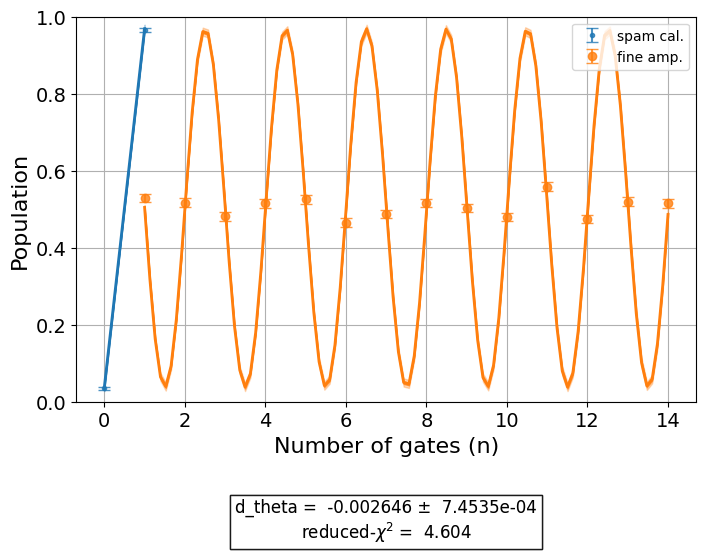

In [288]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 0 pulse x1


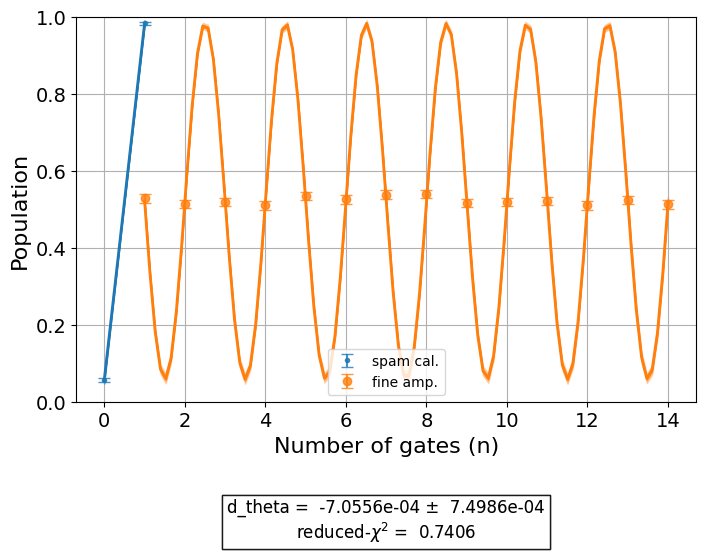

In [289]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 1 pulse x2


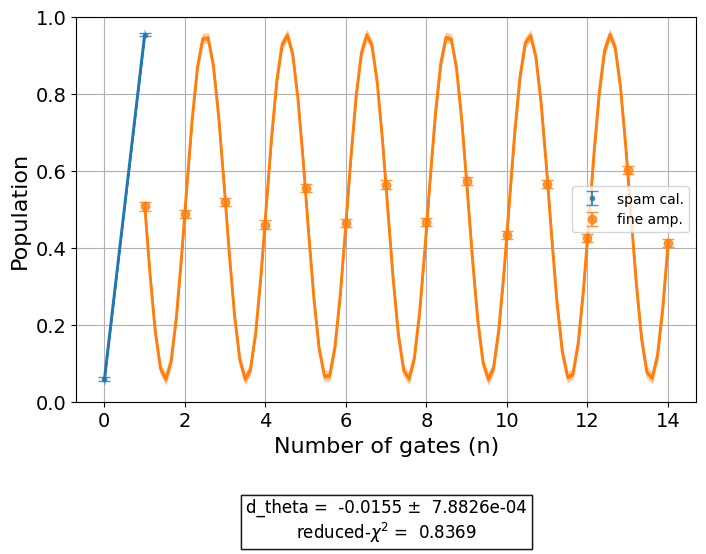

In [290]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

In [291]:
# qubit_index = 4
# print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
# fine_x_exp_datas[qubit_index].figure(0)

In [292]:
# qubit_index = 5
# print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
# fine_x_exp_datas[qubit_index].figure(0)

Qubit 18 pulse sx1


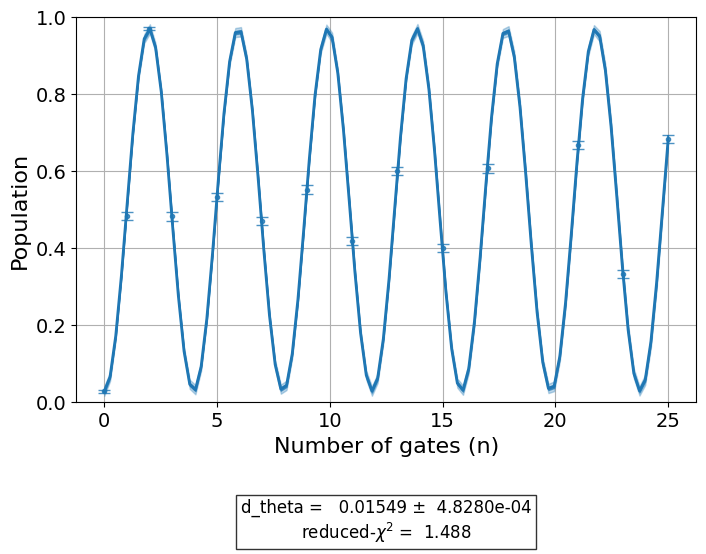

In [293]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 14 pulse sx2


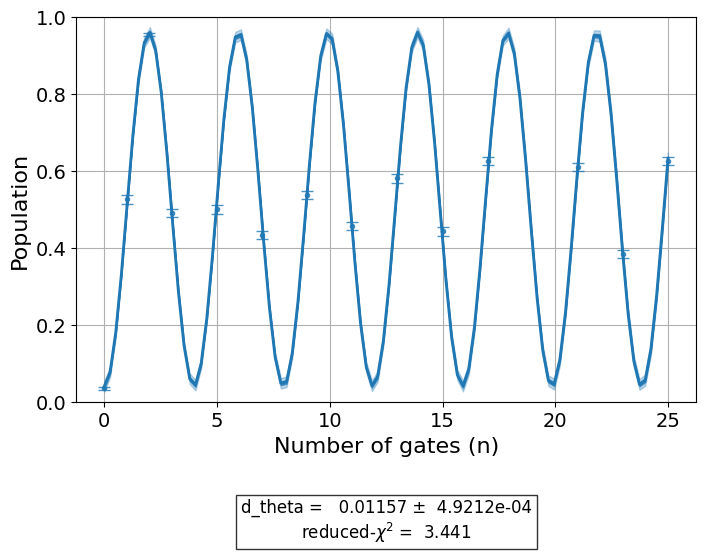

In [294]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 0 pulse sx1


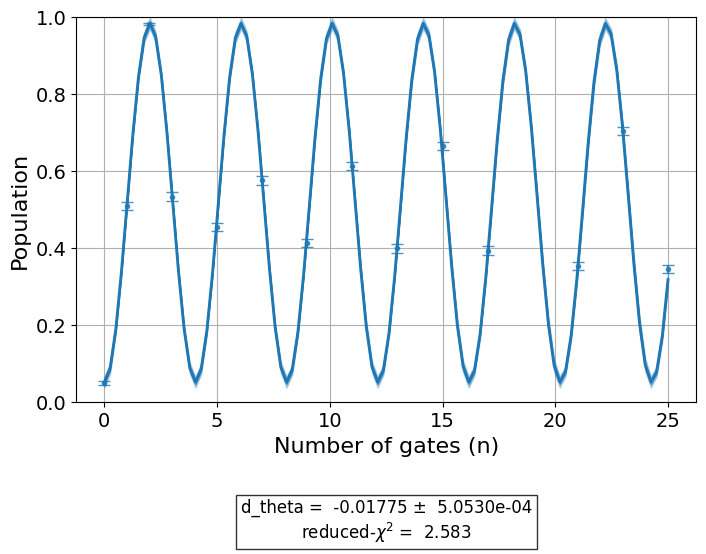

In [295]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 1 pulse sx2


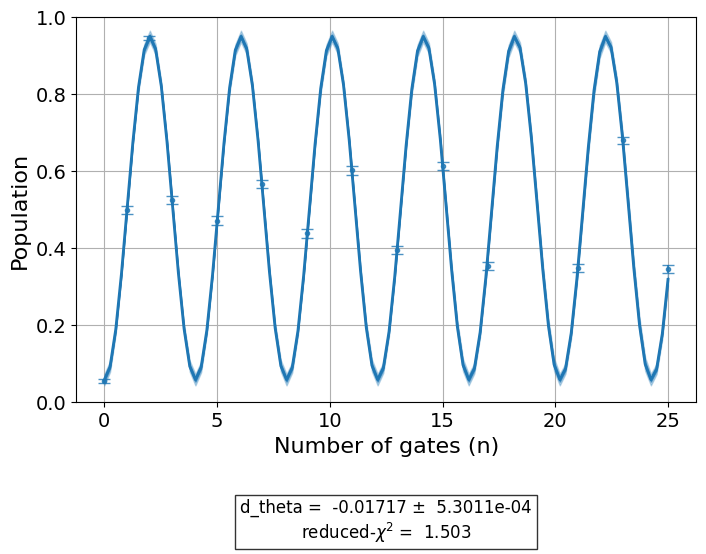

In [296]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

In [297]:
# qubit_index = 4
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

In [298]:
# qubit_index = 5
# print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
# fine_sx_exp_datas[qubit_index].figure(0)

We can check the amplitude ratios again after the fine calibration.

In [299]:
for i, (qubit, amp) in enumerate(zip(qubits, x_fine_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amplitude: {amp}")

Qubit 18 x1 gate amplitude: 1.7151406934485962
Qubit 14 x2 gate amplitude: 1.584598416556519
Qubit 0 x1 gate amplitude: 1.7359796275509776
Qubit 1 x2 gate amplitude: 1.6492270869283558
Qubit 8 x1 gate amplitude: 1.5223142848341091
Qubit 9 x2 gate amplitude: 1.6102176425845178
Qubit 10 x1 gate amplitude: 1.659550056117236
Qubit 11 x2 gate amplitude: 1.7293909303233808


In [300]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_fine_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amplitude: {amp}")

Qubit 18 sx1 gate amplitude: 1.6955076737185941
Qubit 14 sx2 gate amplitude: 1.5772155567797441
Qubit 0 sx1 gate amplitude: 1.7512799106190726
Qubit 1 sx2 gate amplitude: 1.6581383855261231
Qubit 8 sx1 gate amplitude: 1.5293176265508477
Qubit 9 sx2 gate amplitude: 1.6112704550810886
Qubit 10 sx1 gate amplitude: 1.6444321574986245
Qubit 11 sx2 gate amplitude: 1.6911770829992787


In [301]:
for i, (x_amp, sx_amp) in enumerate(zip(x_fine_amps, sx_fine_amps)):
    print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_amp / x_amp)

Ratio of sx1 to x1 on qubit 18: 0.9885531141526784
Ratio of sx2 to x2 on qubit 14: 0.9953408638430811
Ratio of sx1 to x1 on qubit 0: 1.0088136305433952
Ratio of sx2 to x2 on qubit 1: 1.0054033181169515
Ratio of sx1 to x1 on qubit 8: 1.0046004572028973
Ratio of sx2 to x2 on qubit 9: 1.0006538324191263
Ratio of sx1 to x1 on qubit 10: 0.9908903629855058
Ratio of sx2 to x2 on qubit 11: 0.9779032914686581


## DD sequence

We can now play a DD sequence in all the four qubits we calibrated.

In [142]:
# x_fine_amps = x_rough_amps
# sx_fine_amps = sx_rough_amps
i_fine_amps = x_rough_amps

# x_fine_amps_gaussian = x_rough_amps_gaussian
# sx_fine_amps_gaussian = sx_rough_amps_gaussian

In [146]:
x_fine_amps = [1] * 8
sx_fine_amps = [1] * 8
i_fine_amps = [1] * 8

x_fine_amps_gaussian = [1] * 8
sx_fine_amps_gaussian = [1] * 8
i_fine_amps_gaussian = [1] * 8

In [147]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])
fine_q2_x1 = build_schedule(pico_gates["x1"], qubits[2], x_fine_amps[2])
fine_q3_x2 = build_schedule(pico_gates["x2"], qubits[3], x_fine_amps[3])
fine_q4_x1 = build_schedule(pico_gates["x1"], qubits[4], x_fine_amps[4])
fine_q5_x2 = build_schedule(pico_gates["x2"], qubits[5], x_fine_amps[5])
fine_q6_x1 = build_schedule(pico_gates["x1"], qubits[6], x_fine_amps[6])
fine_q7_x2 = build_schedule(pico_gates["x2"], qubits[7], x_fine_amps[7])

In [148]:
fine_q0_sx1 = build_schedule(pico_gates["sx1"], qubits[0], sx_fine_amps[0])
fine_q1_sx2 = build_schedule(pico_gates["sx2"], qubits[1], sx_fine_amps[1])
fine_q2_sx1 = build_schedule(pico_gates["sx1"], qubits[2], sx_fine_amps[2])
fine_q3_sx2 = build_schedule(pico_gates["sx2"], qubits[3], sx_fine_amps[3])
fine_q4_sx1 = build_schedule(pico_gates["sx1"], qubits[4], sx_fine_amps[4])
fine_q5_sx2 = build_schedule(pico_gates["sx2"], qubits[5], sx_fine_amps[5])
fine_q6_sx1 = build_schedule(pico_gates["sx1"], qubits[6], sx_fine_amps[6])
fine_q7_sx2 = build_schedule(pico_gates["sx2"], qubits[7], sx_fine_amps[7])

In [149]:
fine_q1_i2 = build_schedule(pico_gates["sx2"], qubits[1], i_fine_amps[0])
fine_q3_i2 = build_schedule(pico_gates["sx2"], qubits[3], i_fine_amps[1])
fine_q5_i2 = build_schedule(pico_gates["sx2"], qubits[5], i_fine_amps[2])
fine_q7_i2 = build_schedule(pico_gates["sx2"], qubits[7], i_fine_amps[3])

In [150]:
fine_q0_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[0], x_fine_amps_gaussian[0])
fine_q1_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[1], x_fine_amps_gaussian[1])
fine_q2_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[2], x_fine_amps_gaussian[2])
fine_q3_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[3], x_fine_amps_gaussian[3])
# fine_q4_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[4], x_fine_amps_gaussian[4])
# fine_q5_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[5], x_fine_amps_gaussian[5])
# fine_q6_x1_gaussian = build_schedule(default_gates["x1"].samples, qubits[6], x_fine_amps_gaussian[6])
# fine_q7_x2_gaussian = build_schedule(default_gates["x2"].samples, qubits[7], x_fine_amps_gaussian[7])

In [151]:
fine_q0_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[0], sx_fine_amps_gaussian[0])
fine_q1_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[1], sx_fine_amps_gaussian[1])
fine_q2_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[2], sx_fine_amps_gaussian[2])
fine_q3_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[3], sx_fine_amps_gaussian[3])
# fine_q4_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[4], sx_fine_amps_gaussian[4])
# fine_q5_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[5], sx_fine_amps_gaussian[5])
# fine_q6_sx1_gaussian = build_schedule(default_gates["sx1"].samples, qubits[6], sx_fine_amps_gaussian[6])
# fine_q7_sx2_gaussian = build_schedule(default_gates["sx2"].samples, qubits[7], sx_fine_amps_gaussian[7])

In [152]:
def xyxy_sequence(repetitions: int, num_qubits: int, all_qubits: list[int], qubit_pairs: list[list[int]], x_schedules = None, sx_schedules = None):
    qc = qk.QuantumCircuit(num_qubits, len(all_qubits))
    qc.reset(all_qubits)

    for q0, q1 in qubit_pairs:
        qc.sx(q0)
        qc.sx(q1)
        for _ in range(repetitions):
            qc.x(q0)
            qc.rz(np.pi, q0)
            qc.x(q0)
            qc.x(q0)
            qc.rz(np.pi, q0)
            qc.x(q0)

            qc.x(q1)
            qc.rz(np.pi, q1)
            qc.x(q1)
            qc.x(q1)
            qc.rz(np.pi, q1)
            qc.x(q1)
        qc.sxdg(q0)
        qc.sxdg(q1)

    qc.barrier()
    
    for (idx, qubit) in enumerate(all_qubits):
        qc.measure(qubit, idx)

    if x_schedules is not None:
        x_gate = qk.circuit.library.XGate()
        for (q0, schedule) in zip(all_qubits, x_schedules):
            qc.add_calibration(x_gate, (q0,), schedule)

    if sx_schedules is not None:
        sx_gate = qk.circuit.library.SXGate()
        for (q0, schedule) in zip(all_qubits, sx_schedules):
            qc.add_calibration(sx_gate, (q0,), schedule)

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [153]:
xyxy_sequence(
    1, 
    num_qubits, 
    qubits, 
    [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], 
    [fine_q0_x1, fine_q1_x2, fine_q2_x1, fine_q3_x2, fine_q4_x1, fine_q5_x2, fine_q6_x1, fine_q7_x2], 
    [fine_q0_sx1, fine_q1_sx2, fine_q2_sx1, fine_q3_sx2, fine_q4_sx1, fine_q5_sx2, fine_q6_sx1, fine_q7_sx2]
).draw(idle_wires=False)

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌─────────┐┌─────────┐»
 q_0: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
 q_1: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
 q_8: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
 q_9: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
q_10: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
q_11: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
q_14: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├─────────┤├─────────┤»
q_18: ─|0>─┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ Rz(π/2) ├┤ Rz(π/2) ├»
           └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└─────────┘└─────────┘»
 c: 8/═══════════════════════════════════════════════════════════════════════»
                                                                             »
«      ┌────┐┌─────────┐┌─────────┐ ░       ┌─┐               
« q_0: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░───────┤M├───────────────
«      ├────┤├─────────┤├─────────┤ ░       └╥┘┌─┐            
« q_1: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────────╫─┤M├────────────
«      ├────┤├─────────┤├─────────┤ ░        ║ └╥┘┌─┐         
« q_8: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────────╫──╫─┤M├─────────
«      ├────┤├─────────┤├─────────┤ ░        ║  ║ └╥┘┌─┐      
« q_9: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────────╫──╫──╫─┤M├──────
«      ├────┤├─────────┤├─────────┤ ░        ║  ║  ║ └╥┘┌─┐   
«q_10: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────────╫──╫──╫──╫─┤M├───
«      ├────┤├─────────┤├─────────┤ ░        ║  ║  ║  ║ └╥┘┌─┐
«q_11: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────────╫──╫──╫──╫──╫─┤M├
«      ├────┤├─────────┤├─────────┤ ░    ┌─┐ ║  ║  ║  ║  ║ └╥┘
«q_14: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────┤M├─╫──╫──╫──╫──╫──╫─
«      ├────┤├─────────┤├─────────┤ ░ ┌─┐└╥┘ ║  ║  ║  ║  ║  ║ 
«q_18: ┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░─┤M├─╫──╫──╫──╫──╫──╫──╫─
«      └────┘└─────────┘└─────────┘ ░ └╥┘ ║  ║  ║  ║  ║  ║  ║ 
« c: 8/════════════════════════════════╩══╩══╩══╩══╩══╩══╩══╩═
«                                      0  1  2  3  4  5  6  7

In [154]:
lengths = list(range(0, 201, 4)) # with custom gates, lengths = list(range(0, 201, 4))

dd_circuits_robust = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], [fine_q0_x1, fine_q1_x2, fine_q2_x1, fine_q3_x2, fine_q4_x1, fine_q5_x2, fine_q6_x1, fine_q7_x2], [fine_q0_sx1, fine_q1_sx2, fine_q2_sx1, fine_q3_sx2, fine_q4_sx1, fine_q5_sx2, fine_q6_sx1, fine_q7_sx2]) for i in lengths]
# dd_circuits_default = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], None, None) for i in lengths]
# dd_circuits_gaussian = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1], [qubit2, qubit3], [qubit4, qubit5], [qubit6, qubit7]], [fine_q0_x1_gaussian, fine_q1_x2_gaussian, fine_q2_x1_gaussian, fine_q3_x2_gaussian, fine_q4_x1_gaussian, fine_q5_x2_gaussian], [fine_q0_sx1_gaussian, fine_q1_sx2_gaussian, fine_q2_sx1_gaussian, fine_q3_sx2_gaussian, fine_q4_sx1_gaussian, fine_q5_sx2_gaussian]) for i in lengths]

In [155]:
lengths = list(range(0, 801, 4))
qubits = [qubit0, qubit1]
dd_circuits_default = [xyxy_sequence(i, num_qubits, qubits, [[qubit0, qubit1]], None, None) for i in lengths]

In [281]:
dd_circuits_default[0].draw(idle_wires=False)

global phase: π
           ┌────┐┌─────────┐┌─────────┐┌────┐┌─────────┐┌─────────┐ ░    ┌─┐
q_14: ─|0>─┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░────┤M├
           ├────┤├─────────┤├─────────┤├────┤├─────────┤├─────────┤ ░ ┌─┐└╥┘
q_18: ─|0>─┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(π/2) ├─░─┤M├─╫─
           └────┘└─────────┘└─────────┘└────┘└─────────┘└─────────┘ ░ └╥┘ ║ 
 c: 2/═════════════════════════════════════════════════════════════════╩══╩═
                                                                       0  1

In [313]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
# dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)
# dd_jobs_gaussian = sampler.run(dd_circuits_gaussian, shots=2048)

In [316]:
dd_jobs_robust.job_id(), dd_jobs_robust.status()

('cy04pa9cw2k0008jcms0', 'DONE')

In [41]:
dd_jobs_default_2q = service.job("cwz6se560bqg008q6980")

In [42]:
default_2q_results = dd_jobs_default_2q.result()
default_2q_counts = []
for result in default_2q_results:
    default_2q_counts.append(result["__value__"]["data"].c.get_counts())

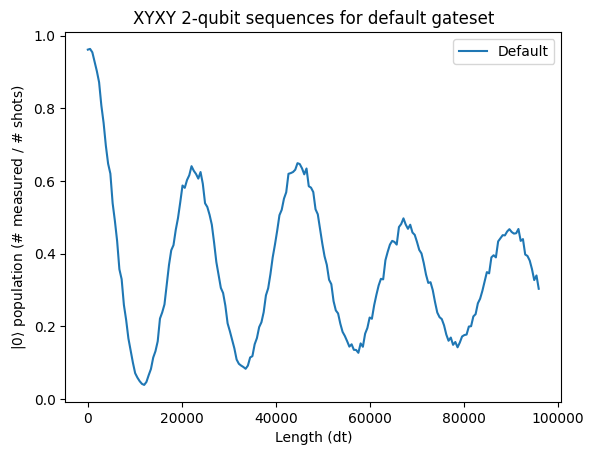

In [48]:
default_points = [count.get("00", 0) / 2048 for count in default_2q_counts]

plt.plot([l * 120 for l in lengths], default_points, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")
plt.title("XYXY 2-qubit sequences for default gateset")
plt.legend()
plt.show()

In [49]:
lenghts = [l * 120 for l in lengths]
file_path = "output.txt"

# Save the lists to the file
with open(file_path, "w") as file:
    file.write(", ".join(map(str, default_points)) + "\n")
    file.write(", ".join(map(str, lenghts)) + "\n")

In [110]:
dd_jobs_robust.job_id()#, dd_jobs_default.job_id(), dd_jobs_gaussian.job_id()

'cwy1g81997wg008y5ad0'

In [160]:
dd_jobs_robust.status()#, dd_jobs_default.status(), dd_jobs_gaussian.status()

'DONE'

In [229]:
lengths = list(range(0, 201, 4))

In [50]:
dd_jobs_robust = service.job("cwcvxtqjzdhg0081gpj0")
dd_jobs_dephasing_robust = service.job("cy04pa9cw2k0008jcms0")
dd_jobs_default = service.job("cw5y2tvqg250008fbxkg")
dd_jobs_gaussian = service.job("cw5y2xvpcbmg008304z0")

In [53]:
robust_results = dd_jobs_robust.result()
robust_counts = []
for result in robust_results:
    robust_counts.append(result["__value__"]["data"].c.get_counts())

dephasing_robust_results = dd_jobs_dephasing_robust.result()
dephasing_robust_counts = []
for result in dephasing_robust_results:
    dephasing_robust_counts.append(result["__value__"]["data"].c.get_counts())

default_results = dd_jobs_default.result()
default_counts = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())

gaussian_results = dd_jobs_gaussian.result()
gaussian_counts = []
for result in gaussian_results:
    gaussian_counts.append(result.data.c.get_counts())

In [ ]:
default_points = [count.get("00000000", 0) / 2048 for count in default_counts]

plt.plot([l * 120 * 4 for l in lengths], default_points, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")
plt.title("XYXY 2-qubit sequences in for default gateset")
plt.legend()
plt.show()

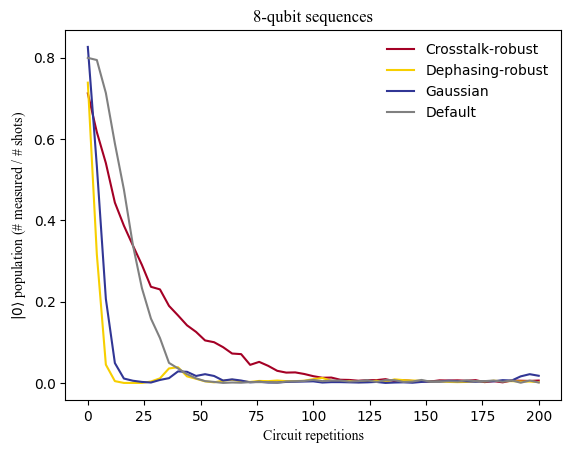

In [83]:
dephasing_robust_points = [count.get("00000000", 0) / 2048 for count in dephasing_robust_counts]
robust_points = [count.get("00000000", 0) / 2048 for count in robust_counts]
gaussian_points = [count.get("00000000", 0) / 2048 for count in gaussian_counts]
default_points = [count.get("00000000", 0) / 2048 for count in default_counts]

plt.plot([l for l in lengths], robust_points, label="Crosstalk-robust", color="#a40025")
plt.plot([l for l in lengths], dephasing_robust_points, label="Dephasing-robust", color="#f7cf00")
plt.plot([l for l in lengths], gaussian_points, label="Gaussian", color="#313695")
plt.plot([l for l in lengths], default_points, label="Default", color="#808080")

font = {"fontname": "Times New Roman"}

# plt.xlabel("Length (dt)", **font)
plt.xlabel("Circuit repetitions", **font)
plt.ylabel("$|0\\rangle$ population (# measured / # shots)", **font)
# plt.title("XYXY 8-qubit sequences (4-qubit breakout)", **font)
plt.title("8-qubit sequences", **font)
plt.legend(frameon=False)
plt.savefig("dd_8qubit.pdf", format="pdf", dpi=300, bbox_inches="tight")

In [57]:
import itertools

def n_qubit_breakout(results, slice, tag=False):
    counts = []
    for result in results:
        if tag:
            counts.append(result["__value__"]["data"].c.slice_bits(slice).get_counts())
        else:
            counts.append(result.data.c.slice_bits(slice).get_counts())
    return [count.get("0" * len(slice)) / 2048 for count in counts]

In [62]:
def get_slice_normal_error(slice_results):
    errors = []
    for count in slice_results:
        errors.append(get_normal_approx_error(2048, count * 2048, 2048 - (count * 2048)))
    return errors

In [70]:
numbers = [i for i in range(8)]
four_qubit_slices = [numbers[i:i+4] for i in range(len(numbers) - 3)]

four_qubit_default_counts = []
four_qubit_default_normal_errors = []
for slice in list(four_qubit_slices):
    four_qubit_default_counts.append(n_qubit_breakout(default_results, slice))
    four_qubit_default_normal_errors.append(get_slice_normal_error(four_qubit_default_counts[-1]))

four_qubit_robust_counts = []
four_qubit_robust_normal_errors = []
for slice in list(four_qubit_slices):
    four_qubit_robust_counts.append(n_qubit_breakout(robust_results, slice, tag = True))
    four_qubit_robust_normal_errors.append(get_slice_normal_error(four_qubit_robust_counts[-1]))

four_qubit_dephasing_counts = []
four_qubit_dephasing_normal_errors = []
for slice in list(four_qubit_slices):
    four_qubit_dephasing_counts.append(n_qubit_breakout(dephasing_robust_results, slice, tag = True))
    four_qubit_dephasing_normal_errors.append(get_slice_normal_error(four_qubit_dephasing_counts[-1]))

four_qubit_gaussian_counts = []
four_qubit_gaussian_normal_errors = []
for slice in list(four_qubit_slices):
    four_qubit_gaussian_counts.append(n_qubit_breakout(gaussian_results, slice))
    four_qubit_gaussian_normal_errors.append(get_slice_normal_error(four_qubit_gaussian_counts[-1]))

In [71]:
def get_avg_normal_error(all_counts, errors, num_circuit_repetitions, sample_points):
    avg = []
    err = []
    for i in range(num_circuit_repetitions):
        avg.append(np.mean([c[i] for c in all_counts]))
        err.append(np.sqrt(np.sum([e[i] ** 2 for e in errors]) / sample_points))
    return avg, err

In [72]:
sample_points = len(four_qubit_default_counts)
num_circuit_repetitions = len(four_qubit_default_counts[0])

avg_four_qubit_default, normal_error_four_qubit_default = get_avg_normal_error(four_qubit_default_counts, four_qubit_default_normal_errors, len(lengths), 8) 
avg_four_qubit_robust, normal_error_four_qubit_robust = get_avg_normal_error(four_qubit_robust_counts, four_qubit_robust_normal_errors, len(lengths), 8)
avg_four_qubit_dephasing, normal_error_four_qubit_dephasing = get_avg_normal_error(four_qubit_dephasing_counts, four_qubit_dephasing_normal_errors, len(lengths), 8)
avg_four_qubit_gaussian, normal_error_four_qubit_gaussian = get_avg_normal_error(four_qubit_gaussian_counts, four_qubit_gaussian_normal_errors, len(lengths), 8)

In [73]:
def get_avg_stddev(all_counts, num_circuit_repetitions, sample_points):
    avg = [0] * num_circuit_repetitions
    for counts in all_counts:
        for i, element in enumerate(counts):
            avg[i] += element / sample_points 

    stddev = [0] * num_circuit_repetitions
    for counts in all_counts:
        for i, element in enumerate(counts):
            stddev[i] += ((element - avg[i]) ** 2) / sample_points
    stddev = [np.sqrt(s) for s in stddev]

    return avg, stddev

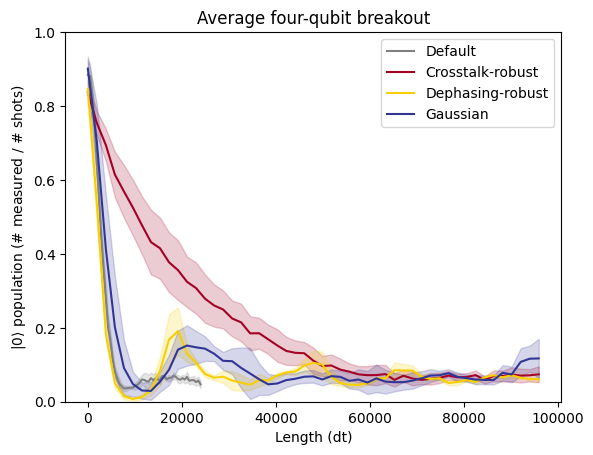

In [76]:
sample_points = len(four_qubit_default_counts)
num_circuit_repetitions = len(four_qubit_default_counts[0])

average_four_qubit_default, stddev_four_qubit_default = get_avg_stddev(four_qubit_default_counts, num_circuit_repetitions, sample_points)
average_four_qubit_robust, stddev_four_qubit_robust = get_avg_stddev(four_qubit_robust_counts, num_circuit_repetitions, sample_points)
average_four_qubit_dephasing, stddev_four_qubit_dephasing = get_avg_stddev(four_qubit_dephasing_counts, num_circuit_repetitions, sample_points)
average_four_qubit_gaussian, stddev_four_qubit_gaussian = get_avg_stddev(four_qubit_gaussian_counts, num_circuit_repetitions, sample_points)

plt.plot([i * 120 * 4 for i in range(num_circuit_repetitions)], average_four_qubit_default, label="Default", color="#808080")
plt.fill_between(
    [i * 120 * 4 for i in range(num_circuit_repetitions)],
    np.array(average_four_qubit_default) - np.array(stddev_four_qubit_default),
    np.array(average_four_qubit_default) + np.array(stddev_four_qubit_default),
    color="#808080", alpha=0.2
)

plt.plot([i * 480 * 4 for i in range(num_circuit_repetitions)], average_four_qubit_robust, label="Crosstalk-robust", color="#a40025")
plt.fill_between(
    [i * 480 * 4 for i in range(num_circuit_repetitions)],
    np.array(average_four_qubit_robust) - np.array(stddev_four_qubit_robust),
    np.array(average_four_qubit_robust) + np.array(stddev_four_qubit_robust),
    color="#a40025", alpha=0.2
)

plt.plot([i * 480 * 4 for i in range(num_circuit_repetitions)], average_four_qubit_dephasing, label="Dephasing-robust", color="#f7cf00")
plt.fill_between(
    [i * 480 * 4 for i in range(num_circuit_repetitions)],
    np.array(average_four_qubit_dephasing) - np.array(stddev_four_qubit_dephasing),
    np.array(average_four_qubit_dephasing) + np.array(stddev_four_qubit_dephasing),
    color="#f7cf00", alpha=0.2
)

plt.plot([i * 480 * 4 for i in range(num_circuit_repetitions)], average_four_qubit_gaussian, label="Gaussian", color="#313695")
plt.fill_between(
    [i * 480 * 4 for i in range(num_circuit_repetitions)],
    np.array(average_four_qubit_gaussian) - np.array(stddev_four_qubit_gaussian),
    np.array(average_four_qubit_gaussian) + np.array(stddev_four_qubit_gaussian),
    color="#313695", alpha=0.2
)

plt.title("Average four-qubit breakout")
# plt.xlabel("Circuit repetitions")
plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")

ax = plt.gca()
ax.set_ylim([0, 1])

plt.legend()

In [84]:
numbers = [i for i in range(8)]
two_qubit_slices = [numbers[i:i+2] for i in range(len(numbers) - 1)]

two_qubit_default_counts = []
two_qubit_default_normal_errors = []
for slice in list(two_qubit_slices):
    two_qubit_default_counts.append(n_qubit_breakout(default_results, slice))
    two_qubit_default_normal_errors.append(get_slice_normal_error(two_qubit_default_counts[-1]))

two_qubit_robust_counts = []
two_qubit_robust_normal_errors = []
for slice in list(two_qubit_slices):
    two_qubit_robust_counts.append(n_qubit_breakout(robust_results, slice, tag = True))
    two_qubit_robust_normal_errors.append(get_slice_normal_error(two_qubit_robust_counts[-1]))

two_qubit_dephasing_counts = []
two_qubit_dephasing_normal_errors = []
for slice in list(two_qubit_slices):
    two_qubit_dephasing_counts.append(n_qubit_breakout(dephasing_robust_results, slice, tag = True))
    two_qubit_dephasing_normal_errors.append(get_slice_normal_error(two_qubit_dephasing_counts[-1]))

two_qubit_gaussian_counts = []
two_qubit_gaussian_normal_errors = []
for slice in list(two_qubit_slices):
    two_qubit_gaussian_counts.append(n_qubit_breakout(gaussian_results, slice))
    two_qubit_gaussian_normal_errors.append(get_slice_normal_error(two_qubit_gaussian_counts[-1]))

In [85]:
sample_points = len(two_qubit_default_counts)
num_repetitions = len(two_qubit_default_counts[0])

avg_two_qubit_default, normal_error_two_qubit_default = get_avg_normal_error(two_qubit_default_counts, two_qubit_default_normal_errors, num_circuit_repetitions, sample_points) 
avg_two_qubit_robust, normal_error_two_qubit_robust = get_avg_normal_error(two_qubit_robust_counts, two_qubit_robust_normal_errors, num_circuit_repetitions, sample_points)
avg_two_qubit_dephasing, normal_error_two_qubit_dephasing = get_avg_normal_error(two_qubit_dephasing_counts, two_qubit_dephasing_normal_errors, num_circuit_repetitions, sample_points)
avg_two_qubit_gaussian, normal_error_two_qubit_gaussian = get_avg_normal_error(two_qubit_gaussian_counts, two_qubit_gaussian_normal_errors, num_circuit_repetitions, sample_points)

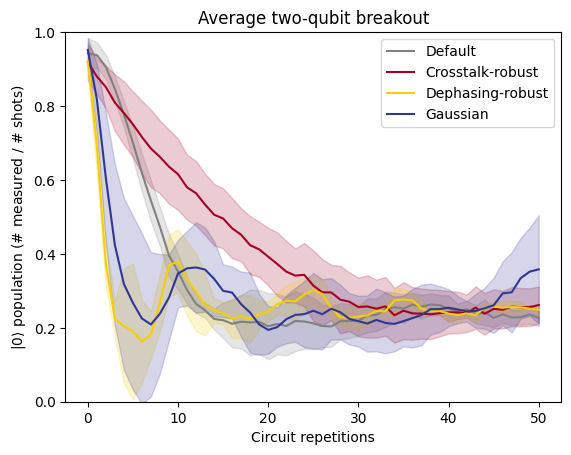

In [86]:
sample_points = len(two_qubit_default_counts)
num_repetitions = len(two_qubit_default_counts[0])

average_two_qubit_default, stddev_two_qubit_default = get_avg_stddev(two_qubit_default_counts, num_circuit_repetitions, sample_points)
average_two_qubit_robust, stddev_two_qubit_robust = get_avg_stddev(two_qubit_robust_counts, num_circuit_repetitions, sample_points)
average_two_qubit_dephasing, stddev_two_qubit_dephasing = get_avg_stddev(two_qubit_dephasing_counts, num_circuit_repetitions, sample_points)
average_two_qubit_gaussian, stddev_two_qubit_gaussian = get_avg_stddev(two_qubit_gaussian_counts, num_circuit_repetitions, sample_points)

plt.plot([i for i in range(num_repetitions)], average_two_qubit_default, label="Default", color="#808080")
plt.fill_between(
    [i for i in range(num_circuit_repetitions)],
    np.array(average_two_qubit_default) - np.array(stddev_two_qubit_default),
    np.array(average_two_qubit_default) + np.array(stddev_two_qubit_default),
    color="#808080", alpha=0.2
)

plt.plot([i for i in range(num_repetitions)], average_two_qubit_robust, label="Crosstalk-robust", color="#a40025")
plt.fill_between(
    [i for i in range(num_circuit_repetitions)],
    np.array(average_two_qubit_robust) - np.array(stddev_two_qubit_robust),
    np.array(average_two_qubit_robust) + np.array(stddev_two_qubit_robust),
    color="#a40025", alpha=0.2
)

plt.plot([i for i in range(num_repetitions)], average_two_qubit_dephasing, label="Dephasing-robust", color="#f7cf00")
plt.fill_between(
    [i for i in range(num_circuit_repetitions)],
    np.array(average_two_qubit_dephasing) - np.array(stddev_two_qubit_dephasing),
    np.array(average_two_qubit_dephasing) + np.array(stddev_two_qubit_dephasing),
    color="#f7cf00", alpha=0.2
)

plt.plot([i for i in range(num_repetitions)], average_two_qubit_gaussian, label="Gaussian", color="#313695")
plt.fill_between(
    [i for i in range(num_circuit_repetitions)],
    np.array(average_two_qubit_gaussian) - np.array(stddev_two_qubit_gaussian),
    np.array(average_two_qubit_gaussian) + np.array(stddev_two_qubit_gaussian),
    color="#313695", alpha=0.2
)

plt.title("Average two-qubit breakout")
plt.xlabel("Circuit repetitions")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")

ax = plt.gca()
ax.set_ylim([0, 1])

plt.legend()

In [87]:
robust_full_normal_approx = [get_normal_approx_error(2048, p * 2048, 2048 - (p * 2048)) for p in robust_points]
dephasing_full_normal_approx = [get_normal_approx_error(2048, p * 2048, 2048 - (p * 2048)) for p in dephasing_robust_points]
gaussian_full_normal_approx = [get_normal_approx_error(2048, p * 2048, 2048 - (p * 2048)) for p in gaussian_points]
default_full_normal_approx = [get_normal_approx_error(2048, p * 2048, 2048 - (p * 2048)) for p in default_points]

In [88]:
cutoff_index = np.where(np.array([4 * i for i in range(num_repetitions)]) == 152)[0][0]

In [94]:
dt_to_microseconds = 0.5 * 0.001

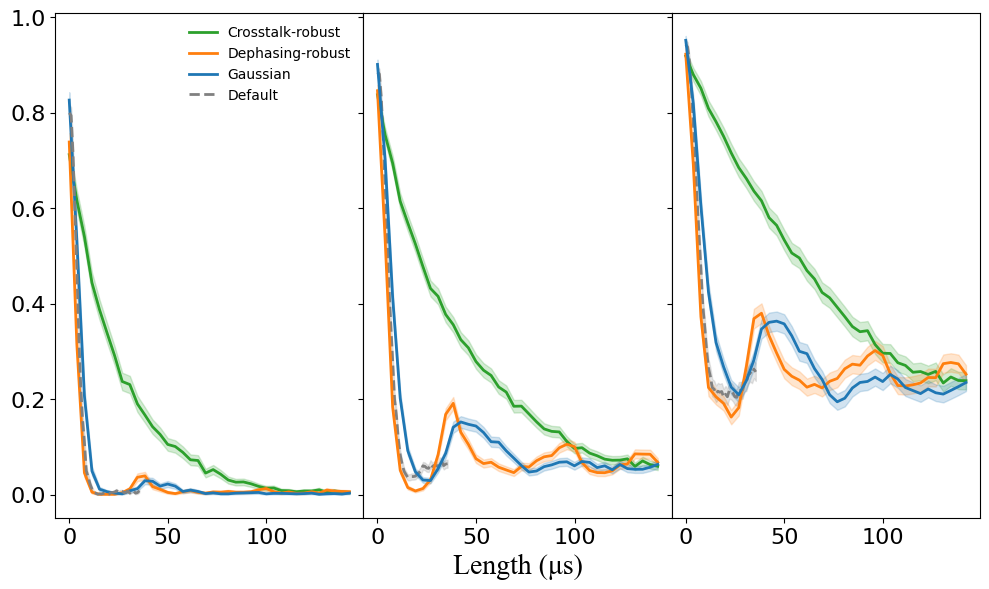

In [99]:
# fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(6, 8))
fig, axs = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(10, 6))
font = {"fontname": "Times New Roman", "size": 20}

normal_approx = True

axs[0].plot([l * 4 * 480 * dt_to_microseconds for l in lengths][0:cutoff_index], robust_points[0:cutoff_index], label="Crosstalk-robust", color="#2ca02c", linewidth=2)
if normal_approx:
    axs[0].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds  for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(robust_points[0:cutoff_index]) - np.array(robust_full_normal_approx[0:cutoff_index]),
        np.array(robust_points[0:cutoff_index]) + np.array(robust_full_normal_approx[0:cutoff_index]),
        color="#2ca02c", alpha=0.2
    )
axs[0].plot([l * 4 * 480 * dt_to_microseconds for l in lengths][0:cutoff_index], dephasing_robust_points[0:cutoff_index], label="Dephasing-robust", color="#ff7f0e", linewidth=2)
if normal_approx:
    axs[0].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds  for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(dephasing_robust_points[0:cutoff_index]) - np.array(dephasing_full_normal_approx[0:cutoff_index]),
        np.array(dephasing_robust_points[0:cutoff_index]) + np.array(dephasing_full_normal_approx[0:cutoff_index]),
        color="#ff7f0e", alpha=0.2
    )
axs[0].plot([l * 4 * 480 * dt_to_microseconds for l in lengths][0:cutoff_index], gaussian_points[0:cutoff_index], label="Gaussian", color="#1f77b4", linewidth=2)
if normal_approx:
    axs[0].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds  for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(gaussian_points[0:cutoff_index]) - np.array(gaussian_full_normal_approx[0:cutoff_index]),
        np.array(gaussian_points[0:cutoff_index]) + np.array(gaussian_full_normal_approx[0:cutoff_index]),
        color="#1f77b4", alpha=0.2
    )
axs[0].plot([l * 4 * 120 * dt_to_microseconds for l in lengths][0:cutoff_index], default_points[0:cutoff_index], label="Default", color="#808080", linewidth=2, linestyle="dashed")
if normal_approx:
    axs[0].fill_between(
        [4 * i * 4 * 120 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(default_points[0:cutoff_index]) - np.array(default_full_normal_approx[0:cutoff_index]),
        np.array(default_points[0:cutoff_index]) + np.array(default_full_normal_approx[0:cutoff_index]),
        color="#808080", alpha=0.2
    )

# Plot for two-qubit breakout
axs[2].plot([4 * i * 4 * 120 * dt_to_microseconds for i in range(num_repetitions)][0:cutoff_index], average_two_qubit_default[0:cutoff_index], label="Default", color="#808080", linewidth=2, linestyle="dashed")
if not normal_approx:
    axs[2].fill_between(
        [4 * i * 4 * 120 * dt_to_microseconds  for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_default[0:cutoff_index]) - np.array(stddev_two_qubit_default[0:cutoff_index]),
        np.array(average_two_qubit_default[0:cutoff_index]) + np.array(stddev_two_qubit_default[0:cutoff_index]),
        color="#808080", alpha=0.2
    )
else:
    axs[2].fill_between(
        [4 * i * 4 * 120 * dt_to_microseconds  for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_default[0:cutoff_index]) - np.array(normal_error_two_qubit_default[0:cutoff_index]),
        np.array(average_two_qubit_default[0:cutoff_index]) + np.array(normal_error_two_qubit_default[0:cutoff_index]),
        color="#808080", alpha=0.2
    )

axs[2].plot([4 * i * 4 * 480 * dt_to_microseconds  for i in range(num_repetitions)][0:cutoff_index], average_two_qubit_robust[0:cutoff_index], label="Crosstalk-robust", color="#2ca02c", linewidth=2)
if not normal_approx:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_robust[0:cutoff_index]) - np.array(stddev_two_qubit_robust[0:cutoff_index]),
        np.array(average_two_qubit_robust[0:cutoff_index]) + np.array(stddev_two_qubit_robust[0:cutoff_index]),
        color="#2ca02c", alpha=0.2
)
else:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_robust[0:cutoff_index]) - np.array(normal_error_two_qubit_robust[0:cutoff_index]),
        np.array(average_two_qubit_robust[0:cutoff_index]) + np.array(normal_error_two_qubit_robust[0:cutoff_index]),
        color="#2ca02c", alpha=0.2
    )

axs[2].plot([4 * i * 4 * 480 * dt_to_microseconds  for i in range(num_repetitions)][0:cutoff_index], average_two_qubit_dephasing[0:cutoff_index], label="Dephasing-robust", color="#ff7f0e", linewidth=2)
if not normal_approx:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_dephasing[0:cutoff_index]) - np.array(stddev_two_qubit_dephasing[0:cutoff_index]),
        np.array(average_two_qubit_dephasing[0:cutoff_index]) + np.array(stddev_two_qubit_dephasing[0:cutoff_index]),
        color="#ff7f0e", alpha=0.2
    )
else:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_dephasing[0:cutoff_index]) - np.array(normal_error_two_qubit_dephasing[0:cutoff_index]),
        np.array(average_two_qubit_dephasing[0:cutoff_index]) + np.array(normal_error_two_qubit_dephasing[0:cutoff_index]),
        color="#ff7f0e", alpha=0.2
    )

axs[2].plot([4 * i * 4 * 480 * dt_to_microseconds for i in range(num_repetitions)[0:cutoff_index]], average_two_qubit_gaussian[0:cutoff_index], label="Gaussian", color="#1f77b4", linewidth=2)
if not normal_approx:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_gaussian[0:cutoff_index]) - np.array(stddev_two_qubit_gaussian[0:cutoff_index]),
        np.array(average_two_qubit_gaussian[0:cutoff_index]) + np.array(stddev_two_qubit_gaussian[0:cutoff_index]),
        color="#1f77b4", alpha=0.2
    )
else:
    axs[2].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_two_qubit_gaussian[0:cutoff_index]) - np.array(normal_error_two_qubit_gaussian[0:cutoff_index]),
        np.array(average_two_qubit_gaussian[0:cutoff_index]) + np.array(normal_error_two_qubit_gaussian[0:cutoff_index]),
        color="#1f77b4", alpha=0.2
    )

# Plot for four-qubit breakout
axs[1].plot([4 * i * 4 * 120 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index], average_four_qubit_default[0:cutoff_index], label="Default", color="#808080", linewidth=2, linestyle="dashed")
if not normal_approx:
    axs[1].fill_between(
        [4 * i * 4 * 120 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_default[0:cutoff_index]) - np.array(stddev_four_qubit_default[0:cutoff_index]),
        np.array(average_four_qubit_default[0:cutoff_index]) + np.array(stddev_four_qubit_default[0:cutoff_index]),
        color="#808080", alpha=0.2
    )
else:
    axs[1].fill_between(
        [4 * i * 4 * 120 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_default[0:cutoff_index]) - np.array(normal_error_four_qubit_default[0:cutoff_index]),
        np.array(average_four_qubit_default[0:cutoff_index]) + np.array(normal_error_four_qubit_default[0:cutoff_index]),
        color="#808080", alpha=0.2
    )

axs[1].plot([4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index], average_four_qubit_robust[0:cutoff_index], label="Crosstalk-robust", color="#2ca02c", linewidth=2)
if not normal_approx:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_robust[0:cutoff_index]) - np.array(stddev_four_qubit_robust[0:cutoff_index]),
        np.array(average_four_qubit_robust[0:cutoff_index]) + np.array(stddev_four_qubit_robust[0:cutoff_index]),
        color="#2ca02c", alpha=0.2
    )
else:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_robust[0:cutoff_index]) - np.array(normal_error_four_qubit_robust[0:cutoff_index]),
        np.array(average_four_qubit_robust[0:cutoff_index]) + np.array(normal_error_four_qubit_robust[0:cutoff_index]),
        color="#2ca02c", alpha=0.2
    )

axs[1].plot([4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index], average_four_qubit_dephasing[0:cutoff_index], label="Dephasing-robust", color="#ff7f0e", linewidth=2)
if not normal_approx:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_dephasing[0:cutoff_index]) - np.array(stddev_four_qubit_dephasing[0:cutoff_index]),
        np.array(average_four_qubit_dephasing[0:cutoff_index]) + np.array(stddev_four_qubit_dephasing[0:cutoff_index]),
        color="#ff7f0e", alpha=0.2
    )
else:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_dephasing[0:cutoff_index]) - np.array(normal_error_four_qubit_dephasing[0:cutoff_index]),
        np.array(average_four_qubit_dephasing[0:cutoff_index]) + np.array(normal_error_four_qubit_dephasing[0:cutoff_index]),
        color="#ff7f0e", alpha=0.2
    )

axs[1].plot([4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index], average_four_qubit_gaussian[0:cutoff_index], label="Gaussian", color="#1f77b4", linewidth=2)
if not normal_approx:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_gaussian[0:cutoff_index]) - np.array(stddev_four_qubit_gaussian[0:cutoff_index]),
        np.array(average_four_qubit_gaussian[0:cutoff_index]) + np.array(stddev_four_qubit_gaussian[0:cutoff_index]),
        color="#1f77b4", alpha=0.2
    )
else:
    axs[1].fill_between(
        [4 * i * 4 * 480 * dt_to_microseconds for i in range(num_circuit_repetitions)][0:cutoff_index],
        np.array(average_four_qubit_gaussian[0:cutoff_index]) - np.array(normal_error_four_qubit_gaussian[0:cutoff_index]),
        np.array(average_four_qubit_gaussian[0:cutoff_index]) + np.array(normal_error_four_qubit_gaussian[0:cutoff_index]),
        color="#1f77b4", alpha=0.2
    )

# axs[0].set_ylabel("P(0)", **font)
# axs[1].set_ylabel("P(0)", **font)
# axs[2].set_ylabel("P(0)", **font)

# axs[0].set_xlabel("Sequence repetitions", **font)
# axs[1].set_xlabel("Sequence repetitions", **font)
axs[1].set_xlabel("Length (μs)", **font)
# axs[2].set_xlabel("Sequence repetitions", **font)

# axs[0].set_xlim([-5, 160])
# axs[0].set_xticks([0, 60, 120])
axs[0].tick_params(axis='x', which='minor')

axs[0].xaxis.set_tick_params(labelsize=16)
axs[0].yaxis.set_tick_params(labelsize=16)

axs[1].xaxis.set_tick_params(labelsize=16)
axs[1].yaxis.set_tick_params(labelsize=16)

axs[2].xaxis.set_tick_params(labelsize=16)
axs[2].yaxis.set_tick_params(labelsize=16)

axs[0].legend(frameon=False)
plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0)

plt.savefig("dd_stacked_normal_approx.pdf", format="pdf", dpi=300, bbox_inches="tight")

In [317]:
def fit_damped_cosine(t_data, y_data, fix_J=False, initial_guess=None, plot=False):
    if fix_J:
        # When J is fixed to 0:
        # f(t) = A*(1 + exp(-gamma*t)) + B
        def model(t, A, B, gamma):
            return A * (1 + np.exp(-gamma * t)) + B
        if initial_guess is None:
            initial_guess = [0.5, 0.0, 0.2]
    else:
        # Full model:
        # f(t) = A*(1 + exp(-gamma*t)*cos(J*t)) + B
        def model(t, A, B, gamma, J):
            return A * (1 + np.exp(-gamma * t) * np.cos(J * t)) + B
        if initial_guess is None:
            initial_guess = [0.5, 0.0, 0.2, 0.3]
    
    try:
        popt, pcov = curve_fit(model, t_data, y_data, p0=initial_guess)
    except Exception as e:
        print("Error during curve fitting:", e)
        if fix_J:
            return None, None, None, None, None, None, None, None
        else:
            return None, None, None, None, None, None, None, None

    if fix_J:
        A_opt, B_opt, gamma_opt = popt
        perr = np.sqrt(np.diag(pcov))
        A_err, B_err, gamma_err = perr[0], perr[1], perr[2]
        J_opt = 0.0
        J_err = None
    else:
        A_opt, B_opt, gamma_opt, J_opt = popt
        perr = np.sqrt(np.diag(pcov))
        A_err, B_err, gamma_err, J_err = perr[0], perr[1], perr[2], perr[3]
    
    # Plot the data and fitted curve if requested.
    if plot:
        t_fit = np.linspace(np.min(t_data), np.max(t_data), 1000)
        y_fit = model(t_fit, *popt)
        plt.figure(figsize=(8, 5))
        plt.scatter(t_data, y_data, color='red', label='Data')
        plt.plot(t_fit, y_fit, label='Fit', linewidth=2)
        plt.xlabel('Time')
        plt.ylabel('f(t)')
        plt.title('Data and Fitted Damped Cosine')
        plt.legend()
        plt.show()
    
    return A_opt, A_err, B_opt, B_err, gamma_opt, gamma_err, J_opt, J_err

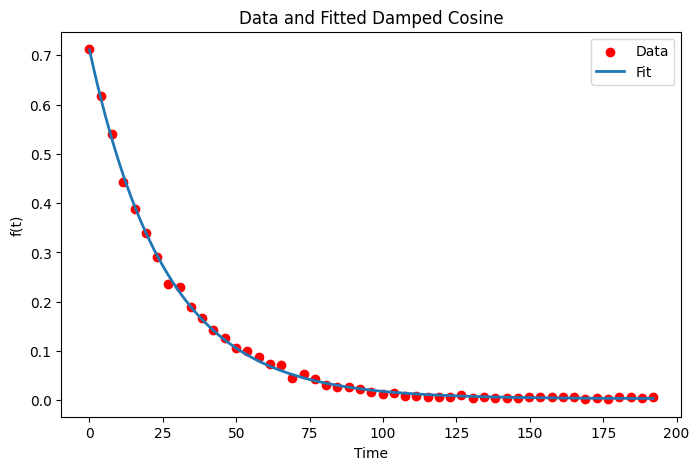

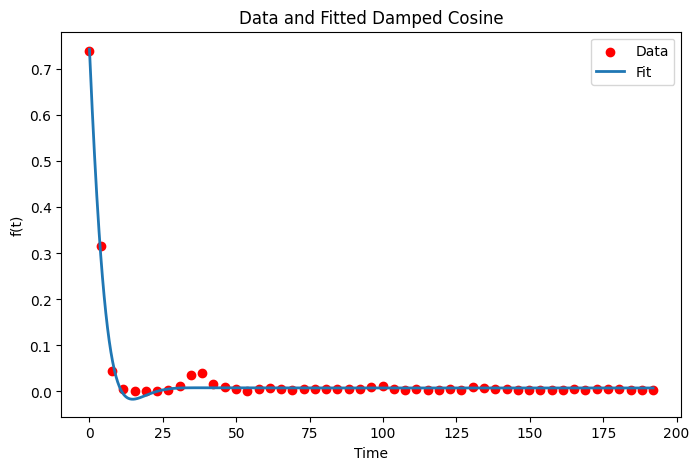

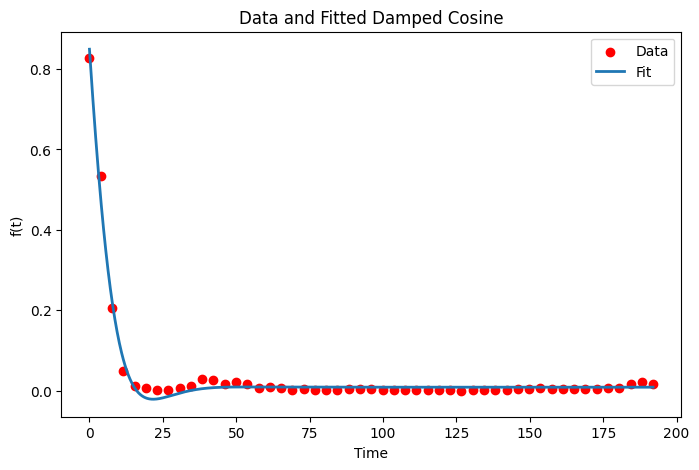

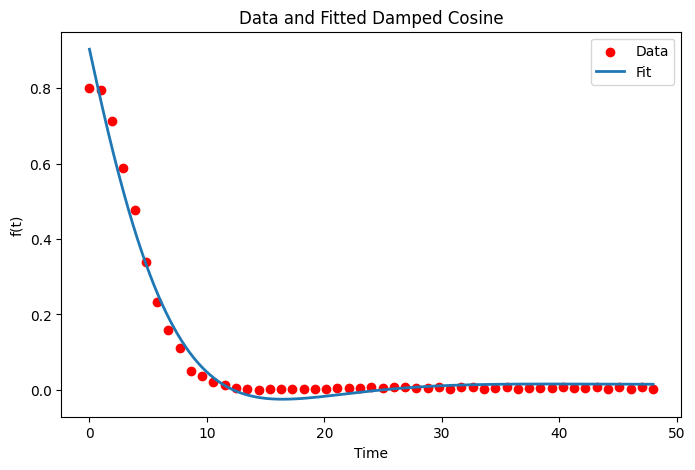

In [328]:
fit_results = {}

t_robust = np.array([l * 4 * 480 * dt_to_microseconds for l in lengths])
t_dephasing = np.array([l * 4 * 480 * dt_to_microseconds for l in lengths])
t_gaussian = np.array([l * 4 * 480 * dt_to_microseconds for l in lengths])
t_default = np.array([l * 4 * 120 * dt_to_microseconds for l in lengths])

# Fit robust_points (all parameters free)
A_fit, A_err, B_r, B_err_r, gamma_r, gamma_err_r, J_r, J_err_r = \
    fit_damped_cosine(t_robust, robust_points, fix_J=True, plot=True)
fit_results["robust_points"] = {
    "A": A_fit, "A_err": A_err,
    "B": B_r, "B_err": B_err_r,
    "gamma": gamma_r, "gamma_err": gamma_err_r,
    "J": J_r, "J_err": J_err_r
}

# Fit dephasing_robust_points (all parameters free)
A_d, A_err_d, B_d, B_err_d, gamma_d, gamma_err_d, J_d, J_err_d = \
    fit_damped_cosine(t_dephasing, dephasing_robust_points, fix_J=False, plot=True)
fit_results["dephasing_robust_points"] = {
    "A": A_d, "A_err": A_err_d,
    "B": B_d, "B_err": B_err_d,
    "gamma": gamma_d, "gamma_err": gamma_err_d,
    "J": J_d, "J_err": J_err_d
}

# Fit gaussian_points (all parameters free)
A_g, A_err_g, B_g, B_err_g, gamma_g, gamma_err_g, J_g, J_err_g = \
    fit_damped_cosine(t_gaussian, gaussian_points, fix_J=False, plot=True)
fit_results["gaussian_points"] = {
    "A": A_g, "A_err": A_err_g,
    "B": B_g, "B_err": B_err_g,
    "gamma": gamma_g, "gamma_err": gamma_err_g,
    "J": J_g, "J_err": J_err_g
}

# Fit default_points with J fixed to 0 (thus model becomes f(t) = A*(1 + exp(-gamma*t)) + B)
A_def, A_err_def, B_def, B_err_def, gamma_def, gamma_err_def, J_def, J_err_def = \
    fit_damped_cosine(t_default, default_points, fix_J=False, plot=True)
fit_results["default_points"] = {
    "A": A_def, "A_err": A_err_def,
    "B": B_def, "B_err": B_err_def,
    "gamma": gamma_def, "gamma_err": gamma_err_def,
    "J": J_def, "J_err": J_err_def
}

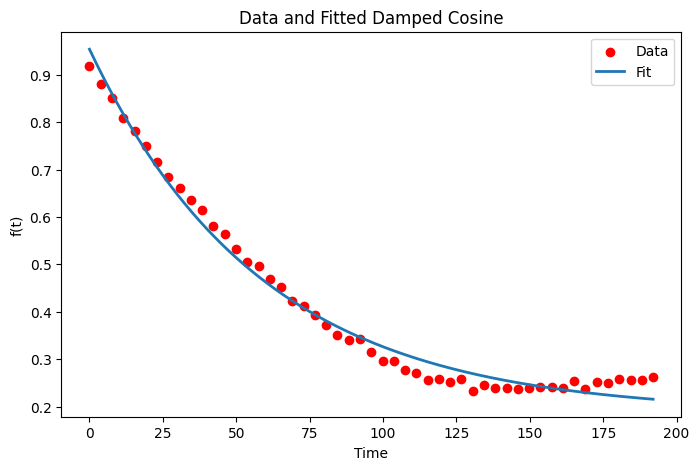

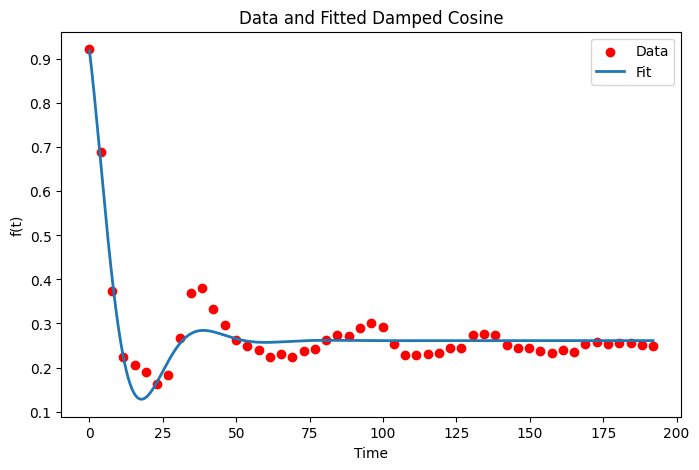

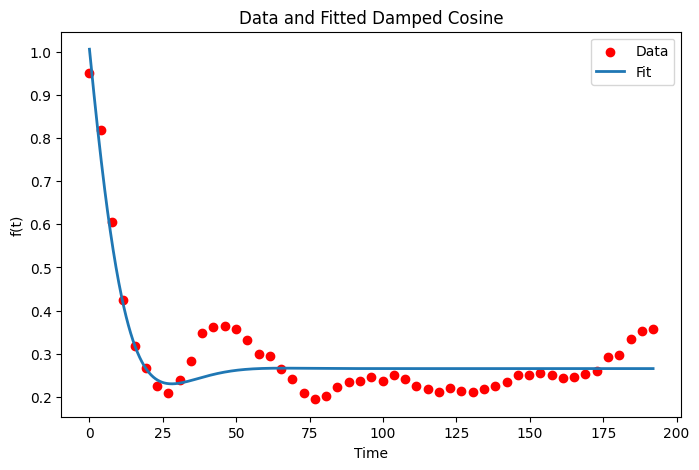

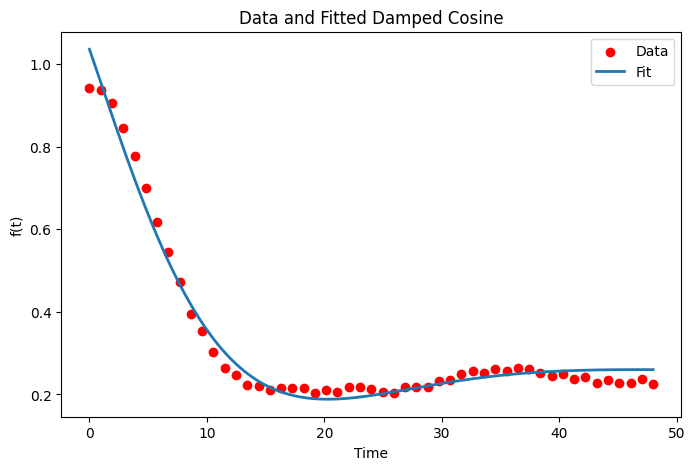

In [334]:
# Fit robust_points (all parameters free)
A_fit, A_err, B_r, B_err_r, gamma_r, gamma_err_r, J_r, J_err_r = \
    fit_damped_cosine(t_robust, average_two_qubit_robust, fix_J=True, plot=True)
fit_results["avg_two_robust_points"] = {
    "A": A_fit, "A_err": A_err,
    "B": B_r, "B_err": B_err_r,
    "gamma": gamma_r, "gamma_err": gamma_err_r,
    "J": J_r, "J_err": J_err_r
}

# Fit dephasing_robust_points (all parameters free)
A_d, A_err_d, B_d, B_err_d, gamma_d, gamma_err_d, J_d, J_err_d = \
    fit_damped_cosine(t_dephasing, average_two_qubit_dephasing, initial_guess=[0.5, 0.0, 0.2, 0.5], fix_J=False, plot=True)
fit_results["avg_two_dephasing_robust_points"] = {
    "A": A_d, "A_err": A_err_d,
    "B": B_d, "B_err": B_err_d,
    "gamma": gamma_d, "gamma_err": gamma_err_d,
    "J": J_d, "J_err": J_err_d
}

# Fit gaussian_points (all parameters free)
A_g, A_err_g, B_g, B_err_g, gamma_g, gamma_err_g, J_g, J_err_g = \
    fit_damped_cosine(t_gaussian, average_two_qubit_gaussian, initial_guess=[0.5, 0.0, 0.2, 0.5], fix_J=False, plot=True)
fit_results["avg_two_gaussian_points"] = {
    "A": A_g, "A_err": A_err_g,
    "B": B_g, "B_err": B_err_g,
    "gamma": gamma_g, "gamma_err": gamma_err_g,
    "J": J_g, "J_err": J_err_g
}

# Fit default_points with J fixed to 0 (thus model becomes f(t) = A*(1 + exp(-gamma*t)) + B)
A_def, A_err_def, B_def, B_err_def, gamma_def, gamma_err_def, J_def, J_err_def = \
    fit_damped_cosine(t_default, average_two_qubit_default, initial_guess=[0.5, 0.0, 0.2, 0.6], fix_J=False, plot=True)
fit_results["avg_two_default_points"] = {
    "A": A_def, "A_err": A_err_def,
    "B": B_def, "B_err": B_err_def,
    "gamma": gamma_def, "gamma_err": gamma_err_def,
    "J": J_def, "J_err": J_err_def
}

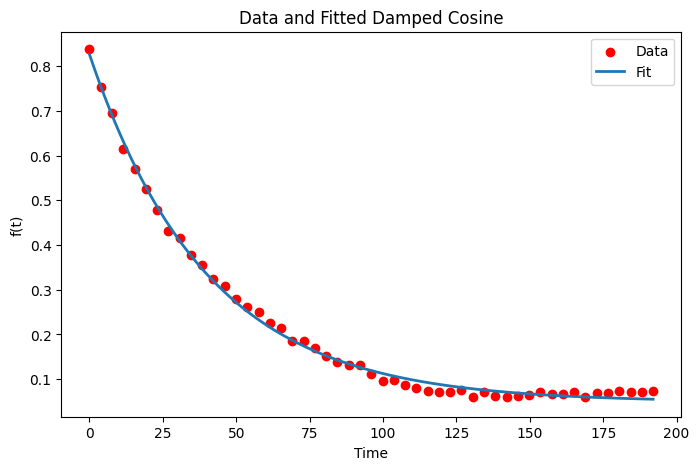

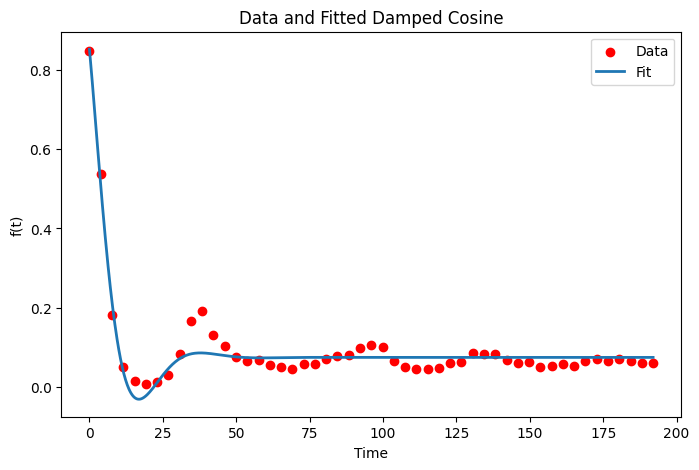

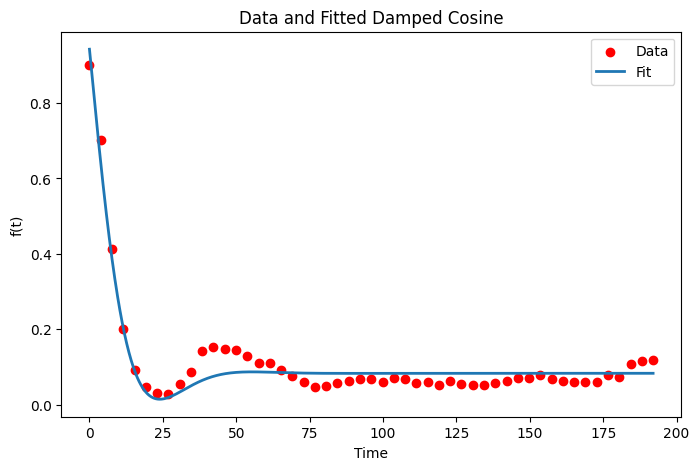

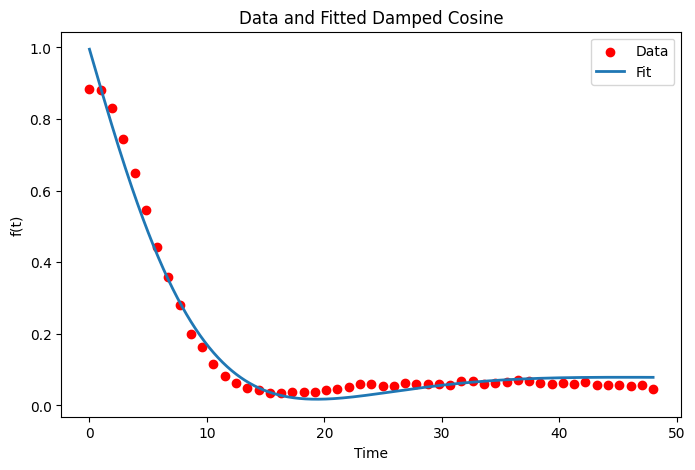

In [335]:
# Fit robust_points (all parameters free)
A_fit, A_err, B_r, B_err_r, gamma_r, gamma_err_r, J_r, J_err_r = \
    fit_damped_cosine(t_robust, average_four_qubit_robust, fix_J=True, plot=True)
fit_results["avg_four_robust_points"] = {
    "A": A_fit, "A_err": A_err,
    "B": B_r, "B_err": B_err_r,
    "gamma": gamma_r, "gamma_err": gamma_err_r,
    "J": J_r, "J_err": J_err_r
}

# Fit dephasing_robust_points (all parameters free)
A_d, A_err_d, B_d, B_err_d, gamma_d, gamma_err_d, J_d, J_err_d = \
    fit_damped_cosine(t_dephasing, average_four_qubit_dephasing, initial_guess=[0.5, 0.0, 0.2, 0.5], fix_J=False, plot=True)
fit_results["avg_four_dephasing_robust_points"] = {
    "A": A_d, "A_err": A_err_d,
    "B": B_d, "B_err": B_err_d,
    "gamma": gamma_d, "gamma_err": gamma_err_d,
    "J": J_d, "J_err": J_err_d
}

# Fit gaussian_points (all parameters free)
A_g, A_err_g, B_g, B_err_g, gamma_g, gamma_err_g, J_g, J_err_g = \
    fit_damped_cosine(t_gaussian, average_four_qubit_gaussian, initial_guess=[0.5, 0.0, 0.2, 0.5], fix_J=False, plot=True)
fit_results["avg_four_gaussian_points"] = {
    "A": A_g, "A_err": A_err_g,
    "B": B_g, "B_err": B_err_g,
    "gamma": gamma_g, "gamma_err": gamma_err_g,
    "J": J_g, "J_err": J_err_g
}

# Fit default_points with J fixed to 0 (thus model becomes f(t) = A*(1 + exp(-gamma*t)) + B)
A_def, A_err_def, B_def, B_err_def, gamma_def, gamma_err_def, J_def, J_err_def = \
    fit_damped_cosine(t_default, average_four_qubit_default, fix_J=False, plot=True)
fit_results["avg_four_default_points"] = {
    "A": A_def, "A_err": A_err_def,
    "B": B_def, "B_err": B_err_def,
    "gamma": gamma_def, "gamma_err": gamma_err_def,
    "J": J_def, "J_err": J_err_def
}

In [336]:
for key, res in fit_results.items():
    print(f"Results for {key}:")
    print(f"   A     = {res['A']:.4f} ± {res['A_err']:.4f}")
    print(f"   B     = {res['B']:.4f} ± {res['B_err']:.4f}")
    print(f"   gamma = {res['gamma']:.4f} ± {res['gamma_err']:.4f}")
    if res["J_err"] is not None:
        print(f"   J     = {res['J']:.4f} ± {res['J_err']:.4f}")
    else:
        print(f"   J     = {res['J']:.4f} (fixed)")
    print("")

Results for robust_points:
   A     = 0.7082 ± 0.0037
   B     = -0.7052 ± 0.0040
   gamma = 0.0386 ± 0.0004
   J     = 0.0000 (fixed)

Results for dephasing_robust_points:
   A     = 0.7360 ± 0.0092
   B     = -0.7284 ± 0.0095
   gamma = 0.1976 ± 0.0084
   J     = 0.1512 ± 0.0066

Results for gaussian_points:
   A     = 0.8400 ± 0.0137
   B     = -0.8311 ± 0.0143
   gamma = 0.1314 ± 0.0062
   J     = -0.1030 ± 0.0047

Results for default_points:
   A     = 0.8885 ± 0.0220
   B     = -0.8740 ± 0.0243
   gamma = 0.1629 ± 0.0092
   J     = 0.1382 ± 0.0066

Results for avg_four_robust_points:
   A     = 0.7777 ± 0.0063
   B     = -0.7289 ± 0.0075
   gamma = 0.0250 ± 0.0005
   J     = 0.0000 (fixed)

Results for avg_four_dephasing_robust_points:
   A     = 0.7763 ± 0.0267
   B     = -0.7011 ± 0.0278
   gamma = 0.1065 ± 0.0086
   J     = 0.1498 ± 0.0065

Results for avg_four_gaussian_points:
   A     = 0.8599 ± 0.0300
   B     = -0.7768 ± 0.0315
   gamma = 0.0926 ± 0.0079
   J     = -0.1000

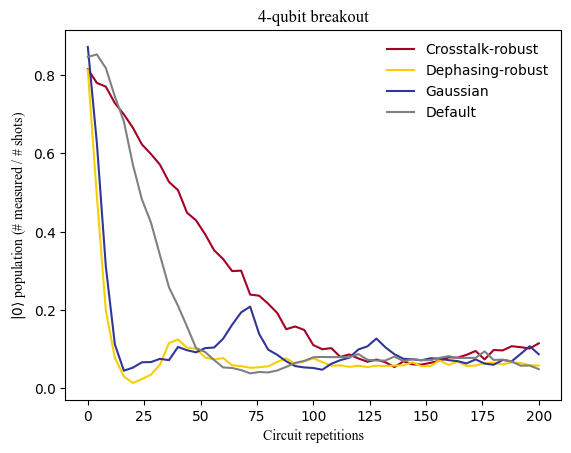

In [332]:
four_dephasing_counts = []
for result in dephasing_robust_results:
    four_dephasing_counts.append(result["__value__"]["data"].c.slice_bits([0, 1, 2, 3]).get_counts())
dephasing_robust_points = [count.get("0000", 0) / 2048 for count in four_dephasing_counts]

four_robust_counts = []
for result in robust_results:
    four_robust_counts.append(result["__value__"]["data"].c.slice_bits([0, 1, 2, 3]).get_counts())
robust_points = [count.get("0000", 0) / 2048 for count in four_robust_counts]

four_gaussian_counts = []
for result in gaussian_results:
    four_gaussian_counts.append(result.data.c.slice_bits([0, 1, 2 , 3]).get_counts())
gaussian_points = [count.get("0000", 0) / 2048 for count in four_gaussian_counts]

four_default_counts = []
for result in default_results:
    four_default_counts.append(result.data.c.slice_bits([0, 1, 2 , 3]).get_counts())
default_points = [count.get("0000", 0) / 2048 for count in four_default_counts]

# plt.plot([l * duration for l in lengths], robust_points, label="Crosstalk-robust", color="#a40025")
# plt.plot([l * duration for l in lengths], dephasing_robust_points, label="Dephasing-robust", color="#f7cf00")
# plt.plot([l * duration for l in lengths], gaussian_points, label="Gaussian", color="#313695")
# plt.plot([l * 120 for l in lengths], default_points, label="Default", color="#808080")

plt.plot([l for l in lengths], robust_points, label="Crosstalk-robust", color="#a40025")
plt.plot([l for l in lengths], dephasing_robust_points, label="Dephasing-robust", color="#f7cf00")
plt.plot([l for l in lengths], gaussian_points, label="Gaussian", color="#313695")
plt.plot([l for l in lengths], default_points, label="Default", color="#808080")


font = {"fontname": "Times New Roman"}

# plt.xlabel("Length (dt)", **font)
plt.xlabel("Circuit repetitions", **font)
plt.ylabel("$|0\\rangle$ population (# measured / # shots)", **font)
# plt.title("XYXY 8-qubit sequences (4-qubit breakout)", **font)
plt.title("4-qubit breakout", **font)
plt.legend(frameon=False)
plt.savefig("dd_4qubit.pdf", format="pdf", dpi=300, bbox_inches="tight")

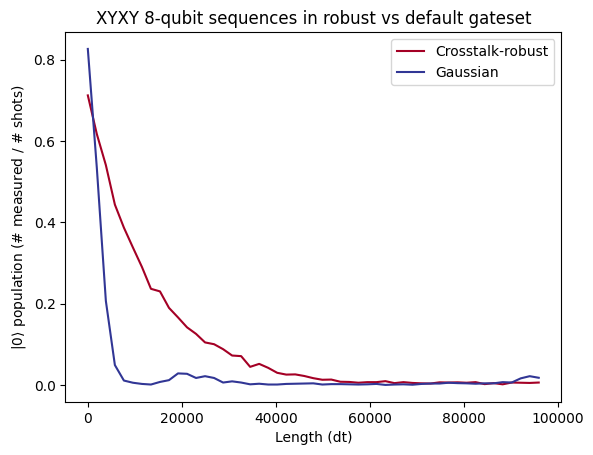

In [ ]:
robust_points = [count.get("00000000", 0) / 2048 for count in robust_counts]
default_points = [count.get("00000000", 0) / 2048 for count in default_counts]
gaussian_points = [count.get("00000000", 0) / 2048 for count in gaussian_counts]

plt.plot([l * duration for l in lengths], robust_points, label="Crosstalk-robust", c="#a40025")
plt.plot([l * duration for l in lengths], gaussian_points, label="Gaussian", c="#313695")
# plt.plot([l * 120 for l in lengths], default_points, label="Default")

plt.xlabel("Length (dt)")
plt.ylabel("$|0\\rangle$ population (# measured / # shots)")
plt.title("XYXY 8-qubit sequences in robust vs default gateset")
plt.legend()
plt.show()

In [333]:
sliced_robust_counts = []
for result in robust_results:
    sliced_robust_counts.append(result["__value__"]["data"].c.slice_bits([0, 1]).get_counts())

sliced_gaussian_counts = []
for result in gaussian_results:
    sliced_gaussian_counts.append(result.data.c.slice_bits([0, 1]).get_counts())

sliced_dephasing_counts = []
for result in dephasing_robust_results:
    sliced_dephasing_counts.append(result["__value__"]["data"].c.slice_bits([0, 1]).get_counts())

sliced_default_counts = []
for result in default_results:
    sliced_default_counts.append(result.data.c.slice_bits([0, 1]).get_counts())

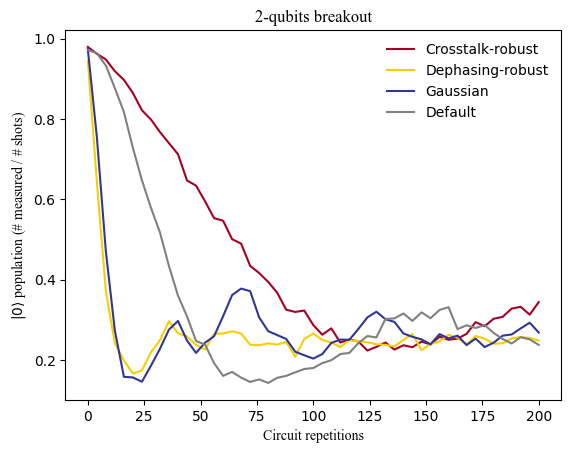

In [334]:
sliced_robust_points = [count.get("00", 0) / 2048 for count in sliced_robust_counts]
sliced_default_points = [count.get("00", 0) / 2048 for count in sliced_default_counts]
sliced_dephasing_points = [count.get("00", 0) / 2048 for count in sliced_dephasing_counts]
sliced_gaussian_points = [count.get("00", 0) / 2048 for count in sliced_gaussian_counts]

# plt.plot([l * duration for l in lengths], sliced_robust_points, label="Crosstalk-robust", c="#a40025")
# plt.plot([l * duration for l in lengths], sliced_dephasing_points, label="Dephasing-robust", c="#f7cf00")
# plt.plot([l * duration for l in lengths], sliced_gaussian_points, label="Gaussian", c="#313695")
# plt.plot([l * 120 for l in lengths], sliced_default_points, label="Default", c="#808080")

plt.plot([l for l in lengths], sliced_robust_points, label="Crosstalk-robust", c="#a40025")
plt.plot([l for l in lengths], sliced_dephasing_points, label="Dephasing-robust", c="#f7cf00")
plt.plot([l for l in lengths], sliced_gaussian_points, label="Gaussian", c="#313695")
plt.plot([l for l in lengths], sliced_default_points, label="Default", c="#808080")

font = {"fontname": "Times New Roman"}

# plt.xlabel("Length (dt)", **font)
plt.xlabel("Circuit repetitions", **font)
plt.ylabel("$|0\\rangle$ population (# measured / # shots)", **font)
# plt.title("XYXY 8-qubit sequences (2-qubit breakout)", **font)
plt.title("2-qubits breakout", **font)
plt.legend(frameon=False)
plt.savefig("dd_2qubit.pdf", format="pdf", dpi=300, bbox_inches="tight")

## Testing robust ID

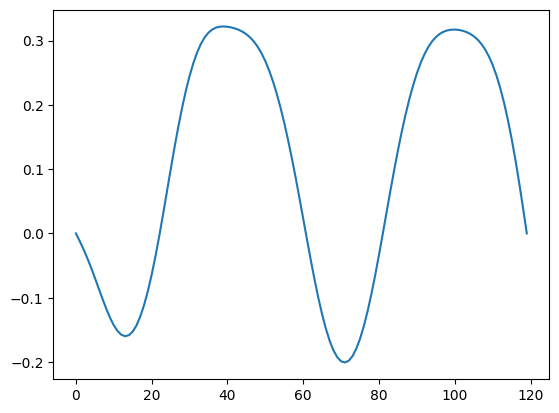

In [79]:
plt.plot(pico_gates["i2"]);

For the amplitude of the identity gate, we choose the amplitude of either the corresponding x or sx gate in the same qubit

In [45]:
id_amp_q0 = x_fine_amps[0]
id_amp_q1 = x_fine_amps[1]
id_amp_q2 = x_fine_amps[2]
id_amp_q3 = x_fine_amps[3]
id_amp_q4 = x_fine_amps[4]
id_amp_q5 = x_fine_amps[5]
id_amp_q6 = x_fine_amps[6]
id_amp_q7 = x_fine_amps[7]

In [ ]:
q0_i2 = build_schedule(pico_gates["i2"], qubit0, id_amp_q0)
q1_i2 = build_schedule(pico_gates["i2"], qubit1, id_amp_q1)
q2_i2 = build_schedule(pico_gates["i2"], qubit2, id_amp_q2)
q3_i2 = build_schedule(pico_gates["i2"], qubit3, id_amp_q3)
q4_i2 = build_schedule(pico_gates["i2"], qubit4, id_amp_q4)
q5_i2 = build_schedule(pico_gates["i2"], qubit5, id_amp_q5)
q6_i2 = build_schedule(pico_gates["i2"], qubit6, id_amp_q6)
q7_i2 = build_schedule(pico_gates["i2"], qubit7, id_amp_q7)

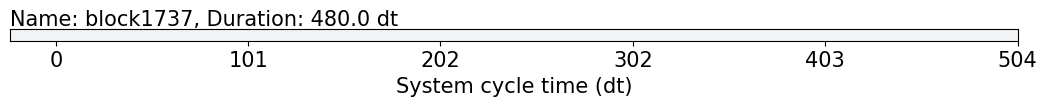

In [160]:
def build_empty_sched(qubit: int, duration: int):
    with qk.pulse.build(backend=backend) as sched:
        qk.pulse.delay(duration, qk.pulse.DriveChannel(qubit))
    return sched
build_empty_sched(qubit0, duration).draw()

In [161]:
q0_i1 = build_empty_sched(qubit0, duration)
q1_i1 = build_empty_sched(qubit1, duration)
q2_i1 = build_empty_sched(qubit2, duration)
q3_i1 = build_empty_sched(qubit3, duration)
q4_i1 = build_empty_sched(qubit4, duration)
q5_i1 = build_empty_sched(qubit5, duration)
q6_i1 = build_empty_sched(qubit6, duration)
q7_i1 = build_empty_sched(qubit7, duration)

In [114]:
def build_id_sequence(repetitions: int, num_qubits: int, all_qubits: list[int], qubit_pairs: list[list[int]], schedules: list = None):
    qc = qk.QuantumCircuit(num_qubits, len(all_qubits))
    
    qc.reset(all_qubits)

    for q0, q1 in qubit_pairs:
        qc.sx(q0)
        qc.sx(q1)
        for _ in range(repetitions):
            qc.id(q0)
            qc.id(q1)

        qc.sxdg(q0)
        qc.sxdg(q1)

    qc.barrier()

    for (idx, qubit) in enumerate(all_qubits):
        qc.measure(qubit, idx)

    if schedules is not None:
        gate = qk.circuit.library.IGate()
        for (q0, schedule) in zip(all_qubits, schedules):
            qc.add_calibration(gate, (q0,), schedule)

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [ ]:
build_id_sequence(10, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i1, q1_i2]).draw(idle_wires=False)

In [194]:
lengths = list(range(0, 201, 4))
id_circuits_robust = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i1, q1_i2]) for i in lengths]
id_circuits_robust_flip = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], [q0_i2, q1_i1]) for i in lengths]
id_circuits_default = [build_id_sequence(i, num_qubits, qubits[0:2], [[qubit0, qubit1]], None) for i in lengths]

In [195]:
id_jobs_robust = sampler.run(id_circuits_robust, shots=2048)
id_jobs_robust_flip = sampler.run(id_circuits_robust_flip, shots=2048)
id_jobs_default = sampler.run(id_circuits_default, shots=2048)

In [196]:
id_jobs_robust.job_id(), id_jobs_robust_flip.job_id(), id_jobs_default.job_id()

('cw5z4jt6f0t0008bq11g', 'cw5z4naxa9wg0082cng0', 'cw5z4s3vwdtg008612h0')

In [200]:
id_jobs_robust.status(), id_jobs_robust_flip.status(), id_jobs_default.status()

(<JobStatus.RUNNING: 'job is actively running'>,
 <JobStatus.RUNNING: 'job is actively running'>,
 <JobStatus.QUEUED: 'job is queued'>)

In [199]:
id_jobs_robust = service.job("cw5z4jt6f0t0008bq11g")
id_jobs_robust_flip = service.job("cw5z4naxa9wg0082cng0")
id_jobs_default = service.job("cw5z4s3vwdtg008612h0")

In [117]:
id_robust_results = id_jobs_robust.result()
id_robust_counts = []
for result in id_robust_results:
    id_robust_counts.append(result.data.c.get_counts())

id_robust_flip_results = id_jobs_robust_flip.result()
id_robust_flip_counts = []
for result in id_robust_flip_results:
    id_robust_flip_counts.append(result.data.c.get_counts())

id_default_results = id_jobs_default.result()
id_default_counts = []
for result in id_default_results:
    id_default_counts.append(result.data.c.get_counts())

In [ ]:
robust_11 = [count.get("00", 0) / 2048 for count in id_robust_counts]
robust_flip_11 = [count.get("00", 0) / 2048 for count in id_robust_flip_counts]
default_11 = [count.get("00", 0) / 2048 for count in id_default_counts]

plt.plot([l * duration for l in lengths], robust_11, label="Robust")
plt.plot([l * duration for l in lengths], robust_flip_11, label="Robust flip")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("00 population (# measured / # shots)")
plt.title("II Sequences in robust vs default gateset")
plt.legend()
plt.show()

## Simultaneous single-qubit RB

In [156]:
def get_rb_experiment(qubit: int, lengths, num_samples, schedules = None, random_seed = None):
    inst_map = qk.pulse.InstructionScheduleMap()
    if schedules is not None:
        inst_map.add(qk.circuit.library.XGate(), (qubit,), schedules[0])
        inst_map.add(qk.circuit.library.SXGate(), (qubit,), schedules[1])
        inst_map.add(qk.circuit.library.IGate(), (qubit,), schedules[2])
    exp = qk_e.library.StandardRB((qubit0,), lengths=lengths, num_samples=num_samples, seed = random_seed)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

In [179]:
rb_lengths = np.arange(1, 800, 100)
num_samples = 10

In [180]:
all_schedules = [
    [fine_q0_x1, fine_q0_sx1, q0_i1],
    [fine_q1_x2, fine_q1_sx2, q1_i1],
    [fine_q2_x1, fine_q2_sx1, q2_i1],
    [fine_q3_x2, fine_q3_sx2, q3_i1],
    # [fine_q4_x1, fine_q4_sx1, q4_i1],
    # [fine_q5_x2, fine_q5_sx2, fine_q5_i2],
    # [fine_q6_x1, fine_q6_sx1, q6_i1],
    # [fine_q7_x2, fine_q7_sx2, fine_q7_i2]
]

gaussian_schedules = [
    [fine_q0_x1_gaussian, fine_q0_sx1_gaussian, q0_i1],
    [fine_q1_x2_gaussian, fine_q1_sx2_gaussian, q1_i1],
    [fine_q2_x1_gaussian, fine_q2_sx1_gaussian, q2_i1],
    [fine_q3_x2_gaussian, fine_q3_sx2_gaussian, q3_i1],
]

rb_qubits = [qubit0, qubit1, qubit2, qubit3] #, qubit4, qubit5, qubit6, qubit7]

In [163]:
rb_experiments = []

for (qubit, schedules) in zip(rb_qubits, all_schedules):
    rb_experiments.append(get_rb_experiment(qubit, rb_lengths, num_samples, schedules, random_seed=12345))

In [164]:
qk.transpile(rb_experiments[1].circuits()[0], basis_gates=["x", "sx", "rz", "id"]).draw(idle_wires=False)

global phase: π/2
        ┌───┐┌─────────┐ ░ ┌───┐┌─────────┐ ░ ┌─┐
     q: ┤ X ├┤ Rz(π/2) ├─░─┤ X ├┤ Rz(π/2) ├─░─┤M├
        └───┘└─────────┘ ░ └───┘└─────────┘ ░ └╥┘
meas: 1/═══════════════════════════════════════╩═
                                               0

In [165]:
num_circuits = len(rb_experiments[0].circuits())
rb_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
rb_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
rb_circuits = [qk.QuantumCircuit(rb_qrs[i], rb_crs[i]) for i in range(num_circuits)]

rb_default_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
rb_default_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
rb_default_circuits = [qk.QuantumCircuit(rb_default_qrs[i], rb_default_crs[i]) for i in range(num_circuits)]

# rb_gaussian_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(num_circuits)]
# rb_gaussian_crs = [qk.ClassicalRegister(len(rb_qubits), "c") for _ in range(num_circuits)]
# rb_gaussian_circuits = [qk.QuantumCircuit(rb_gaussian_qrs[i], rb_gaussian_crs[i]) for i in range(num_circuits)]

for i, qubit in enumerate(rb_qubits):
    rb_q_circuits = rb_experiments[i].circuits()
    qubit_schedules = all_schedules[i]
    # gaussian_qubit_schedules = gaussian_schedules[i]

    for j in range(num_circuits):
        rb_circuits[j].append(rb_q_circuits[j], qargs=(rb_qrs[j][qubit],), cargs=(rb_crs[j][i],))
        rb_default_circuits[j].append(rb_q_circuits[j], qargs=(rb_default_qrs[j][qubit],), cargs=(rb_default_crs[j][i],))
        # rb_gaussian_circuits[j].append(rb_q_circuits[j], qargs=(rb_gaussian_qrs[j][qubit],), cargs=(rb_gaussian_crs[j][i],))
        
        rb_circuits[j].add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
        rb_circuits[j].add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
        rb_circuits[j].add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

        # rb_gaussian_circuits[j].add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
        # rb_gaussian_circuits[j].add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
        # rb_gaussian_circuits[j].add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

rb_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_circuits]
rb_default_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_default_circuits]
# rb_gaussian_circuits = [qk.transpile(circuit, basis_gates=["x", "sx", "rz", "id"]) for circuit in rb_gaussian_circuits]

In [166]:
for circuit in rb_circuits:
    circuit.remove_final_measurements()
    circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
    circuit.barrier()
    circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

for circuit in rb_default_circuits:
    circuit.remove_final_measurements()
    circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
    circuit.barrier()
    circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

# for circuit in rb_gaussian_circuits:
#     circuit.remove_final_measurements()
#     circuit.add_register(qk.ClassicalRegister(len(rb_qubits), "m"))
#     circuit.barrier()
#     circuit.measure(rb_qubits, [i for i in range(len(rb_qubits))])

In [167]:
rb_circuits[0].draw(idle_wires=False)

┌───┐┌─────────┐ ░ ┌───┐┌─────────┐ ░       ┌─┐   
 q_0: ┤ X ├┤ Rz(π/2) ├─░─┤ X ├┤ Rz(π/2) ├─░───────┤M├───
      ├───┤├─────────┤ ░ ├───┤├─────────┤ ░       └╥┘┌─┐
 q_1: ┤ X ├┤ Rz(π/2) ├─░─┤ X ├┤ Rz(π/2) ├─░────────╫─┤M├
      ├───┤├─────────┤ ░ ├───┤├─────────┤ ░    ┌─┐ ║ └╥┘
q_14: ┤ X ├┤ Rz(π/2) ├─░─┤ X ├┤ Rz(π/2) ├─░────┤M├─╫──╫─
      ├───┤├─────────┤ ░ ├───┤├─────────┤ ░ ┌─┐└╥┘ ║  ║ 
q_18: ┤ X ├┤ Rz(π/2) ├─░─┤ X ├┤ Rz(π/2) ├─░─┤M├─╫──╫──╫─
      └───┘└─────────┘ ░ └───┘└─────────┘ ░ └╥┘ ║  ║  ║ 
 m: 4/═══════════════════════════════════════╩══╩══╩══╩═
                                             0  1  2  3

In [175]:
# rb_jobs = sampler.run(rb_circuits, shots=2048)
rb_default_jobs = sampler.run(rb_default_circuits, shots=2048)
# rb_gaussian_jobs = sampler.run(rb_gaussian_circuits, shots=2048)

In [177]:
rb_default_jobs.status(), rb_default_jobs.job_id()

('QUEUED', 'cxzy5sz9b62g008h3ty0')

In [677]:
rb_jobs.job_id(), rb_default_jobs.job_id(), rb_gaussian_jobs.job_id()

('cvzn11mv8tz0008853j0', 'cvzn12m6ezcg008j4h60', 'cvzn14cq9cy00089dzvg')

In [689]:
rb_jobs.status(), rb_default_jobs.status(), rb_gaussian_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [168]:
rb_jobs = service.job("cwx583g2ac5g008jgdt0")
rb_default_jobs = service.job("cw4177crxqkg008ebagg")
rb_gaussian_jobs = service.job("cvzn14cq9cy00089dzvg")
rb_dephasing_jobs = service.job("cwy1h6c997wg008y5ahg")

In [169]:
rb_metadata = []
for i in range(num_circuits):
    metadata = rb_experiments[0].circuits()[i].metadata
    rb_metadata.append(metadata)

In [170]:
def reconstruct_rb_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]], tag = False):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            if not tag:
                counts = get_qubit_counts(result["__value__"]["data"].m.get_counts(), qubits.index(qubit), num_qubits)
            else:
                counts = get_qubit_counts(result.data.m.get_counts(), qubits.index(qubit), num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.set_options(gate_error_ratio=None)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [171]:
def get_normal_approx_error(n_total, n_success, n_failures, z = 1.96):
    # default z value corresponds to 95% confidence interval
    return (z / np.sqrt(n_total)) * np.sqrt((n_success / n_total) * (n_failures / n_total))

In [172]:
rb_robust_total_counts = []
rb_default_total_counts = []
rb_dephasing_total_counts = []
rb_gaussian_total_counts = []

rb_robust_normal_errors = []
rb_default_normal_errors = []
rb_dephasing_normal_errors = []
rb_gaussian_normal_errors = []

for idx, length in enumerate(rb_lengths):
    robust_counts = rb_jobs.result()[idx]["__value__"]["data"].m.get_counts()["0000"]
    rb_robust_total_counts.append(robust_counts / 2048)
    rb_robust_normal_errors.append(get_normal_approx_error(2048, robust_counts, 2048 - robust_counts))

    default_counts = rb_default_jobs.result()[idx].data.m.get_counts()["0000"]
    rb_default_total_counts.append(default_counts / 2048)
    rb_default_normal_errors.append(get_normal_approx_error(2048, default_counts, 2048 - default_counts))

    gaussian_counts = rb_gaussian_jobs.result()[idx].data.m.get_counts()["0000"]
    rb_gaussian_total_counts.append(gaussian_counts / 2048)
    rb_gaussian_normal_errors.append(get_normal_approx_error(2048, gaussian_counts, 2048 - gaussian_counts))

    dephasing_counts = rb_dephasing_jobs.result()[idx]["__value__"]["data"].m.get_counts()["0000"]
    rb_dephasing_total_counts.append(dephasing_counts / 2048)
    rb_dephasing_normal_errors.append(get_normal_approx_error(2048, dephasing_counts, 2048 - dephasing_counts))

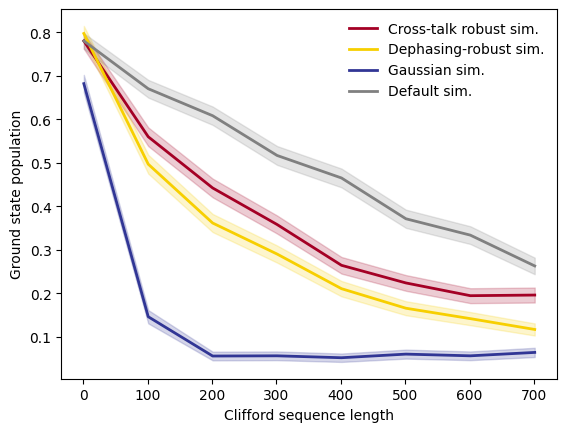

In [173]:
plt.plot(rb_lengths, rb_robust_total_counts, label="Cross-talk robust sim.", c="#a40025", linewidth=2)
plt.fill_between(rb_lengths, np.array(rb_robust_total_counts) - np.array(rb_robust_normal_errors), np.array(rb_robust_total_counts) + np.array(rb_robust_normal_errors), color="#a40025", alpha=0.2)

plt.plot(rb_lengths, rb_dephasing_total_counts, label="Dephasing-robust sim.", c="#f7cf00", linewidth=2)
plt.fill_between(rb_lengths, np.array(rb_dephasing_total_counts) - np.array(rb_dephasing_normal_errors), np.array(rb_dephasing_total_counts) + np.array(rb_dephasing_normal_errors), color="#f7cf00", alpha=0.2)

plt.plot(rb_lengths, rb_gaussian_total_counts, label="Gaussian sim.", c="#313695", linewidth=2)
plt.fill_between(rb_lengths, np.array(rb_gaussian_total_counts) - np.array(rb_gaussian_normal_errors), np.array(rb_gaussian_total_counts) + np.array(rb_gaussian_normal_errors), color="#313695", alpha=0.2)

plt.plot(rb_lengths, rb_default_total_counts, label="Default sim.", c="#808080", linewidth=2)
plt.fill_between(rb_lengths, np.array(rb_default_total_counts) - np.array(rb_default_normal_errors), np.array(rb_default_total_counts) + np.array(rb_default_normal_errors), color="#808080", alpha=0.2)

plt.ylabel("Ground state population")
plt.xlabel("Clifford sequence length")
plt.legend(frameon=False)

In [177]:
rb_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
)

rb_default_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_default_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
    tag=True
)

rb_gaussian_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_gaussian_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
    tag=True
)

rb_dephasing_data = reconstruct_rb_data(
    experiments=rb_experiments,
    job=rb_dephasing_jobs,
    qubits=rb_qubits,
    shots=2048,
    metadata=rb_metadata,
)

In [183]:
robust_alphas = []
gaussian_alphas = []
default_alphas = []
dephasing_alphas = []

robust_epc = []
gaussian_epc = []
default_epc = []
dephasing_epc = []

for i in range(len(rb_data)):
    print(f"Qubit {rb_qubits[i]} RB data:")
    print("    Robust alpha:", rb_data[i].analysis_results("alpha").value.nominal_value)
    print("    Robust EPC:", rb_data[i].analysis_results("EPC").value.nominal_value)

    robust_alphas.append(rb_data[i].analysis_results("alpha").value.nominal_value)
    robust_epc.append(rb_data[i].analysis_results("EPC").value.nominal_value)

    print()
    print("    Gaussian alpha:", rb_gaussian_data[i].analysis_results("alpha").value.nominal_value)
    print("    Gaussian EPC:", rb_gaussian_data[i].analysis_results("EPC").value.nominal_value)

    gaussian_alphas.append(rb_gaussian_data[i].analysis_results("alpha").value.nominal_value)
    gaussian_epc.append(rb_gaussian_data[i].analysis_results("EPC").value.nominal_value)

    print()
    print("    Dephasing alpha:", rb_dephasing_data[i].analysis_results("alpha").value.nominal_value)
    print("    Dephasing EPC:", rb_dephasing_data[i].analysis_results("EPC").value.nominal_value)

    dephasing_alphas.append(rb_dephasing_data[i].analysis_results("alpha").value.nominal_value)
    dephasing_epc.append(rb_dephasing_data[i].analysis_results("EPC").value.nominal_value)

    print()
    print("    Default alpha:", rb_default_data[i].analysis_results("alpha").value.nominal_value)
    print("    Default EPC:", rb_default_data[i].analysis_results("EPC").value.nominal_value)

    default_alphas.append(rb_default_data[i].analysis_results("alpha").value.nominal_value)
    default_epc.append(rb_default_data[i].analysis_results("EPC").value.nominal_value)

Qubit 18 RB data:
    Robust alpha: 0.9964491461530404
    Robust EPC: 0.001775426923479817

    Gaussian alpha: 0.9858467470530847
    Gaussian EPC: 0.007076626473457637

    Dephasing alpha: 0.999431299115823
    Dephasing EPC: 0.0002843504420885212

    Default alpha: 0.9982924089095111
    Default EPC: 0.0008537955452444512
Qubit 14 RB data:
    Robust alpha: 0.9987662985227244
    Robust EPC: 0.0006168507386378197

    Gaussian alpha: 0.9859536077134619
    Gaussian EPC: 0.007023196143269073

    Dephasing alpha: 0.9984650084582994
    Dephasing EPC: 0.0007674957708502794

    Default alpha: 0.9975430156070605
    Default EPC: 0.0012284921964697548
Qubit 0 RB data:
    Robust alpha: 0.9989650852382423
    Robust EPC: 0.0005174573808788274

    Gaussian alpha: 0.9871185977012029
    Gaussian EPC: 0.006440701149398542

    Dephasing alpha: 0.9981012467574895
    Dephasing EPC: 0.0009493766212552712

    Default alpha: 0.9994109447219248
    Default EPC: 0.0002945276390375895
Qubit 1

In [185]:
np.average(robust_alphas), np.average(gaussian_alphas), np.average(dephasing_alphas), np.average(default_alphas)

(0.9983052474980323,
 0.9866108636680972,
 0.9982329946559286,
 0.9987679549238104)

In [186]:
np.average(robust_epc), np.average(gaussian_epc), np.average(dephasing_epc), np.average(default_epc)

(0.0008473762509838279,
 0.006694568165951431,
 0.0008835026720356576,
 0.0006160225380947709)

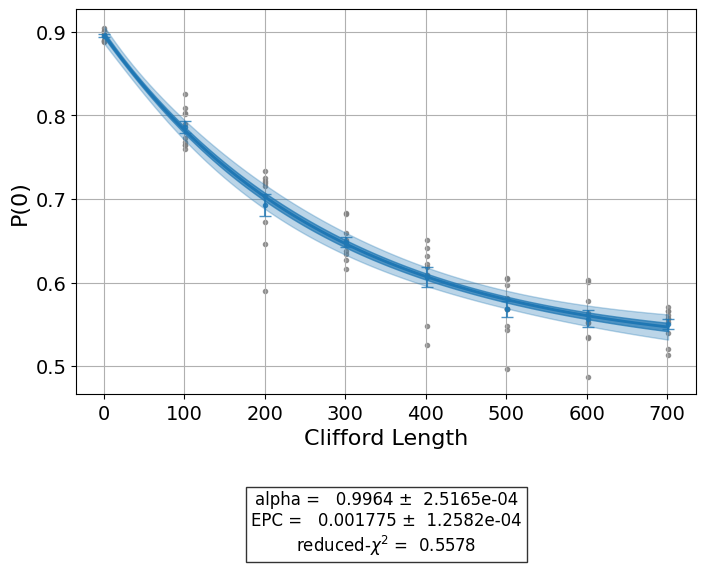

In [187]:
rb_data[0].block_for_results()
rb_data[0].figure(0)

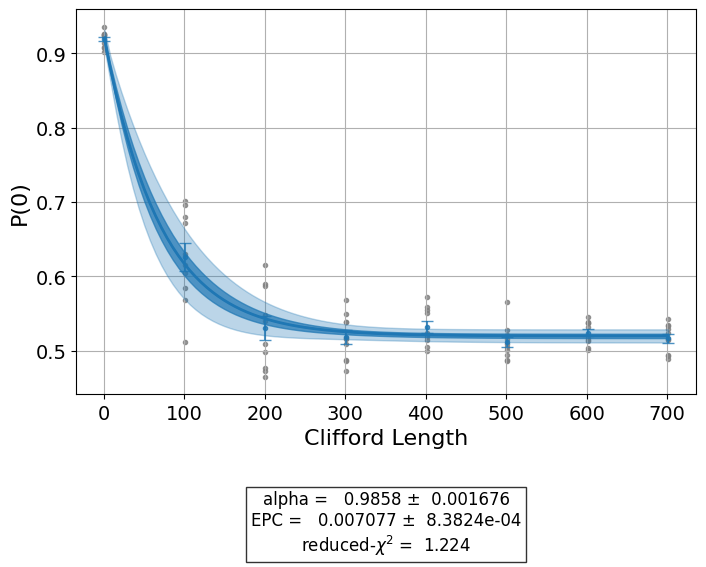

In [188]:
rb_gaussian_data[0].block_for_results()
rb_gaussian_data[0].figure(0)

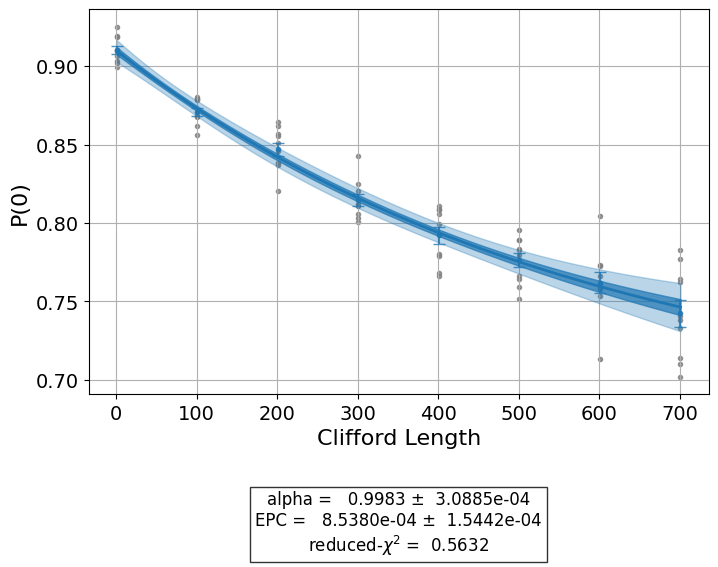

In [189]:
rb_default_data[0].block_for_results()
rb_default_data[0].figure(0)

## Comparison to isolated RB

We compare the decay curve for one of the qubits in the simultanous RB experiment to the decay curve for the same RB experiment in isolation.

In [190]:
qubit_for_rb_data = 2

In [193]:
robust_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, all_schedules[qubit_for_rb_data], random_seed=12345)
dephasing_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, all_schedules[qubit_for_rb_data], random_seed=12345)
gaussian_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, gaussian_schedules[qubit_for_rb_data], random_seed=12345)
default_iso_rb = get_rb_experiment(rb_qubits[qubit_for_rb_data], rb_lengths, num_samples, None, random_seed=12345)

In [ ]:
# robust_iso_job = robust_iso_rb.run(backend=backend, shots=2048)
# gaussian_iso_job = gaussian_iso_rb.run(backend=backend, shots=2048)
default_iso_job = default_iso_rb.run(backend=backend, shots=2048)

In [290]:
default_iso_job.job_status(), default_iso_job.job_ids[0]

(<JobStatus.DONE: 'job has successfully run'>, 'cwy1hz760bqg008pykyg')

In [119]:
# robust_iso_job.job_ids[0], gaussian_iso_job.job_ids[0], default_iso_job.job_ids[0]

In [120]:
# robust_iso_job.jobs()[0].status(), gaussian_iso_job.jobs()[0].status(), default_iso_job.jobs()[0].status()

In [191]:
from qiskit_experiments.framework import ExperimentData

In [194]:
from qiskit_experiments.framework import ExperimentData

robust_iso_data = ExperimentData(experiment=robust_iso_rb)
robust_iso_data.add_jobs([service.job("cwx5cjt2ac5g008jge40")])
robust_iso_rb.analysis.run(robust_iso_data, replace_results=True)

dephasing_iso_data = ExperimentData(experiment=dephasing_iso_rb)
dephasing_iso_data.add_jobs([service.job("cwy1hq6997wg008y5ak0")])
dephasing_iso_rb.analysis.run(robust_iso_data, replace_results=True)

gaussian_iso_data = ExperimentData(experiment=gaussian_iso_rb)
gaussian_iso_data.add_jobs([service.job("cvzn6rv6ezcg008j4j40")])
gaussian_iso_rb.analysis.run(gaussian_iso_data, replace_results=True)

default_iso_data = ExperimentData(experiment=default_iso_rb)
default_iso_data.add_jobs([service.job("cwy1hz760bqg008pykyg")])
default_iso_rb.analysis.run(default_iso_data, replace_results=True)

ExperimentData(StandardRB, 07cd737b-4dd3-480f-ae28-a28d1cf80d9c, job_ids=['cwy1hz760bqg008pykyg'], metadata=<4 items>)

In [195]:
len(rb_data)

# Is summing up the counts for all qubits into a single count dictionary and then using this the 
# same as using the counts for each qubit individually and then adding up the reuslts?

4

In [197]:
qubit_for_rb_data = 1

p0_robust = {}
for i in range(len(rb_data)):
    for d in rb_data[i].data():
        if d["metadata"]["xval"] not in p0_robust:
            p0_robust[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
        else:
            p0_robust[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)
            
p0_robust_iso = {}
for d in robust_iso_data.data():
    if d["metadata"]["xval"] not in p0_robust_iso:
        p0_robust_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_robust_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_dephasing = {}
for i in range(len(rb_dephasing_data)):
    for d in rb_dephasing_data[i].data():
        if d["metadata"]["xval"] not in p0_dephasing:
            p0_dephasing[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
        else:
            p0_dephasing[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_dephasing_iso = {}
for d in dephasing_iso_data.data():
    if d["metadata"]["xval"] not in p0_dephasing_iso:
        p0_dephasing_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_dephasing_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_gaussian = {}
for i in range(len(rb_gaussian_data)):
    for d in rb_gaussian_data[i].data():
        if d["metadata"]["xval"] not in p0_gaussian:
            p0_gaussian[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
        else:
            p0_gaussian[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_gaussian_iso = {}
for d in gaussian_iso_data.data():
    if d["metadata"]["xval"] not in p0_gaussian_iso:
        p0_gaussian_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_gaussian_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_default = {}
for i in range(len(rb_gaussian_data)):
    for d in rb_default_data[i].data():
        if d["metadata"]["xval"] not in p0_default:
            p0_default[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
        else:
            p0_default[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

p0_default_iso = {}
for d in default_iso_data.data():
    if d["metadata"]["xval"] not in p0_default_iso:
        p0_default_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
    else:
        p0_default_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

In [198]:
def get_normal_errors_rb_iso(p0_data):
    total_normal_errors = {}
    for key in p0_data:
        total_normal_errors[key] =[]
        for result in p0_data[key]:
            total_normal_errors[key].append(get_normal_approx_error(2048, result * 2048, (1 - result) * 2048))

    normal_errors = {}
    for key in p0_data:
        num_cases = len(p0_data[key])
        normal_errors[key] = np.sqrt(np.sum([error ** 2 for error in total_normal_errors[key]]) / num_cases)
    
    return normal_errors

In [199]:
p0_robust_iso_normal_approx = get_normal_errors_rb_iso(p0_robust_iso)
p0_dephasing_iso_normal_approx = get_normal_errors_rb_iso(p0_dephasing_iso)
p0_gaussian_iso_normal_approx = get_normal_errors_rb_iso(p0_gaussian_iso)
p0_default_iso_normal_approx = get_normal_errors_rb_iso(p0_default_iso)

p0_robust_normal_approx = get_normal_errors_rb_iso(p0_robust)
p0_dephasing_normal_approx = get_normal_errors_rb_iso(p0_dephasing)
p0_gaussian_normal_approx = get_normal_errors_rb_iso(p0_gaussian)
p0_default_normal_approx = get_normal_errors_rb_iso(p0_default)

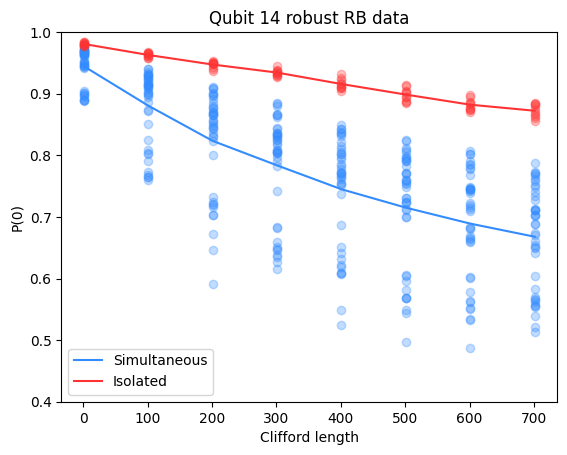

In [200]:
plt.plot(p0_robust.keys(), [np.average(v) for v in p0_robust.values()], label="Simultaneous", c="#338cff")
for key in p0_robust.keys():
    plt.scatter([key] * len(p0_robust[key]), p0_robust[key], alpha=0.3, c="#338cff")

plt.plot(p0_robust_iso.keys(), [np.average(v) for v in p0_robust_iso.values()], label="Isolated", c="#ff3333")
for key in p0_robust_iso.keys():
    plt.scatter([key] * len(p0_robust_iso[key]), p0_robust_iso[key], alpha=0.3, c="#ff3333")

plt.ylim(0.4, 1.0)
plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} robust RB data")
plt.ylabel("P(0)")
plt.xlabel("Clifford length")
plt.legend();

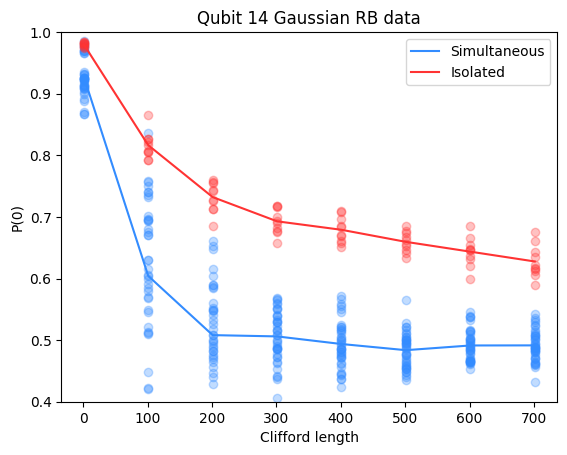

In [201]:
plt.plot(p0_gaussian.keys(), [np.average(v) for v in p0_gaussian.values()], label="Simultaneous", c="#338cff")
for key in p0_gaussian.keys():
    plt.scatter([key] * len(p0_gaussian[key]), p0_gaussian[key], alpha=0.3, c="#338cff")

plt.plot(p0_gaussian_iso.keys(), [np.average(v) for v in p0_gaussian_iso.values()], label="Isolated", c="#ff3333")
for key in p0_gaussian_iso.keys():
    plt.scatter([key] * len(p0_gaussian_iso[key]), p0_gaussian_iso[key], alpha=0.3, c="#ff3333")

plt.ylim(0.4, 1.0)
plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} Gaussian RB data")
plt.ylabel("P(0)")
plt.xlabel("Clifford length")
plt.legend();

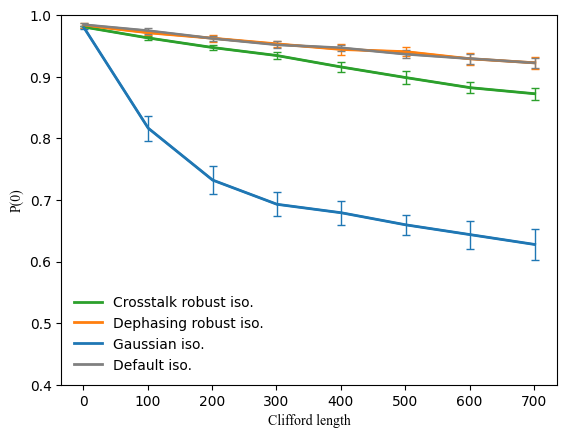

In [202]:
plt.plot(p0_robust_iso.keys(), [np.average(v) for v in p0_robust_iso.values()], label="Crosstalk robust iso.", c="#2ca02c", linewidth=2)
robust_iso_avg = [np.average(v) for v in p0_robust_iso.values()]
robust_iso_err = [np.std(v) for v in p0_robust_iso.values()]
plt.errorbar(
    p0_robust_iso.keys(),
    robust_iso_avg,
    yerr=robust_iso_err,
    c="#2ca02c",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_dephasing_iso.keys(), [np.average(v) for v in p0_dephasing_iso.values()], label="Dephasing robust iso.", c="#ff7f0e", linewidth=2)
dephasing_iso_avg = [np.average(v) for v in p0_dephasing_iso.values()]
dephasing_iso_err = [np.std(v) for v in p0_dephasing_iso.values()]
plt.errorbar(
    p0_dephasing_iso.keys(),
    dephasing_iso_avg,
    yerr=dephasing_iso_err,
    c="#ff7f0e",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_gaussian_iso.keys(), [np.average(v) for v in p0_gaussian_iso.values()], label="Gaussian iso.", c="#1f77b4", linewidth=2)
gaussian_iso_avg = [np.average(v) for v in p0_gaussian_iso.values()]
gaussian_iso_err = [np.std(v) for v in p0_gaussian_iso.values()]
plt.errorbar(
    p0_gaussian_iso.keys(),
    gaussian_iso_avg,
    yerr=gaussian_iso_err,
    c="#1f77b4",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_default_iso.keys(), [np.average(v) for v in p0_default_iso.values()], label="Default iso.", c="#808080", linewidth=2)
default_iso_avg = [np.average(v) for v in p0_default_iso.values()]
default_iso_err = [np.std(v) for v in p0_default_iso.values()]
plt.errorbar(
    p0_default_iso.keys(),
    default_iso_avg,
    yerr=default_iso_err,
    c="#808080",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

font = {"fontname": "Times New Roman"}

plt.ylim(0.4, 1.0)
# plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} robust RB data")
plt.ylabel("P(0)", **font)
plt.xlabel("Clifford length", **font)

plt.legend(frameon=False)

plt.savefig("rb_iso_experiments.pdf", format="pdf", dpi=300, bbox_inches="tight")

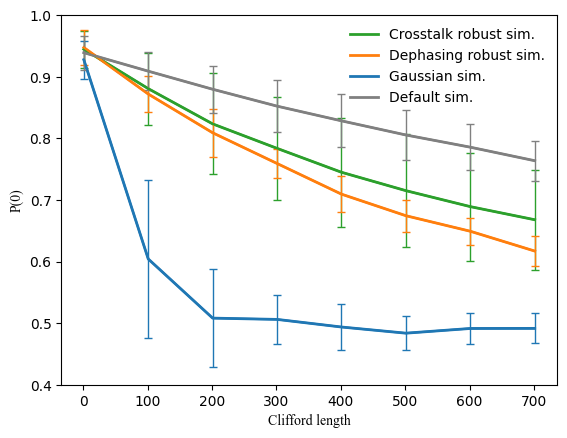

In [203]:
plt.plot(p0_robust.keys(), [np.average(v) for v in p0_robust.values()], label="Crosstalk robust sim.", c="#2ca02c", linewidth=2)
robust_sim_avg = [np.average(v) for v in p0_robust.values()]
robust_sim_err = [np.std(v) for v in p0_robust.values()]
plt.errorbar(
    p0_robust.keys(),
    robust_sim_avg,
    yerr=robust_sim_err,
    c="#2ca02c",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_dephasing.keys(), [np.average(v) for v in p0_dephasing.values()], label="Dephasing robust sim.", c="#ff7f0e", linewidth=2)
dephasing_sim_avg = [np.average(v) for v in p0_dephasing.values()]
dephasing_sim_err = [np.std(v) for v in p0_dephasing.values()]
plt.errorbar(
    p0_dephasing.keys(),
    dephasing_sim_avg,
    yerr=dephasing_sim_err,
    c="#ff7f0e",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_gaussian.keys(), [np.average(v) for v in p0_gaussian.values()], label="Gaussian sim.", c="#1f77b4", linewidth=2)
gaussian_sim_avg = [np.average(v) for v in p0_gaussian.values()]
gaussian_sim_err = [np.std(v) for v in p0_gaussian.values()]
plt.errorbar(
    p0_gaussian.keys(),
    gaussian_sim_avg,
    yerr=gaussian_sim_err,
    c="#1f77b4",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

plt.plot(p0_default.keys(), [np.average(v) for v in p0_default.values()], label="Default sim.", c="#808080", linewidth=2)
default_sim_avg = [np.average(v) for v in p0_default.values()]
default_sim_err = [np.std(v) for v in p0_default.values()]
plt.errorbar(
    p0_default.keys(),
    default_sim_avg,
    yerr=default_sim_err,
    c="#808080",
    fmt="-",
    capsize=3,
    elinewidth=1,
)

font = {"fontname": "Times New Roman"}

plt.ylim(0.4, 1.0)
# plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} robust RB data")
plt.ylabel("P(0)", **font)
plt.xlabel("Clifford length", **font)

plt.legend(frameon=False)

plt.savefig("rb_sim_experiments.pdf", format="pdf", dpi=300, bbox_inches="tight")

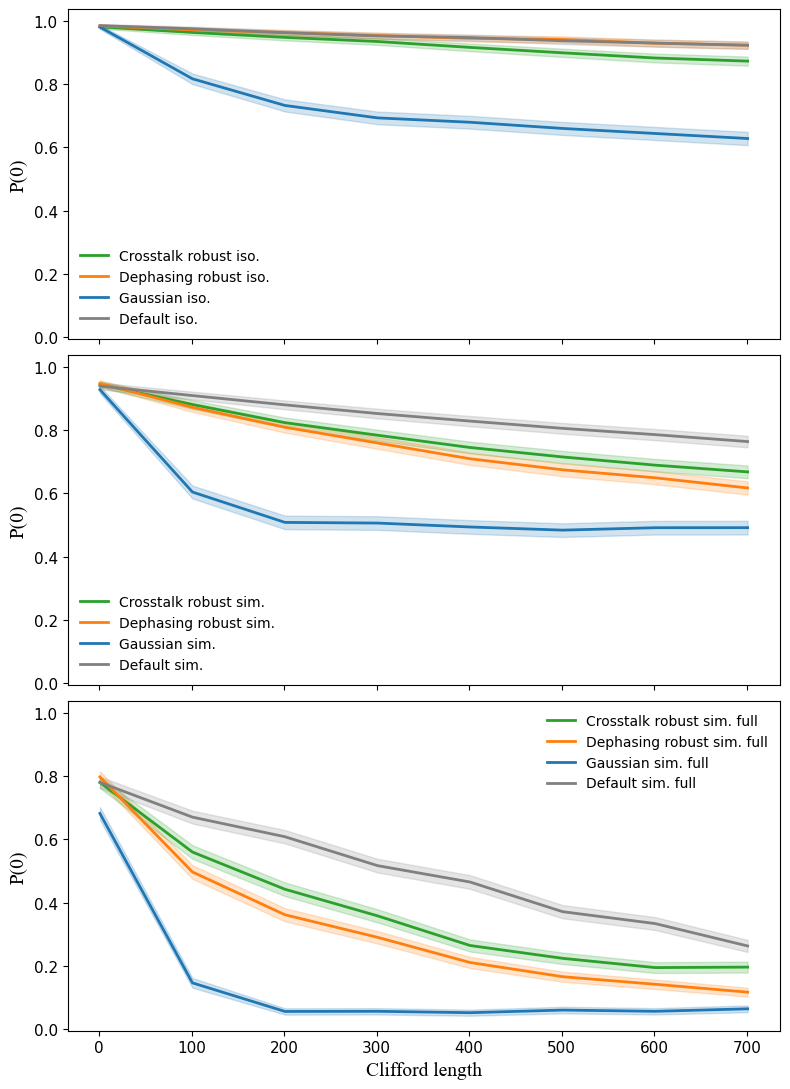

In [204]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 11), sharex=True, sharey=True)
font = {"fontname": "Times New Roman", "size": 14}

normal_approx_erorr = True

# Plot iso data
robust_iso_avg = [np.average(v) for v in p0_robust_iso.values()]
ax1.plot(p0_robust_iso.keys(), [np.average(v) for v in p0_robust_iso.values()], label="Crosstalk robust iso.", c="#2ca02c", linewidth=2)
if not normal_approx_erorr:
    robust_iso_err = [np.std(v) for v in p0_robust_iso.values()]
    ax1.fill_between(p0_robust_iso.keys(), np.array(robust_iso_avg) - np.array(robust_iso_err), np.array(robust_iso_avg) + np.array(robust_iso_err), color="#2ca02c", alpha=0.2)
else:
    normal_errors = [p0_robust_iso_normal_approx[key] for key in p0_robust_iso.keys()]
    ax1.fill_between(p0_robust_iso.keys(), np.array(robust_iso_avg) - np.array(normal_errors), np.array(robust_iso_avg) + np.array(normal_errors), color="#2ca02c", alpha=0.2)

dephasing_iso_avg = [np.average(v) for v in p0_dephasing_iso.values()]
ax1.plot(p0_dephasing_iso.keys(), [np.average(v) for v in p0_dephasing_iso.values()], label="Dephasing robust iso.", c="#ff7f0e", linewidth=2)
if not normal_approx_erorr:
    dephasing_iso_err = [np.std(v) for v in p0_dephasing_iso.values()]
    ax1.fill_between(p0_dephasing_iso.keys(), np.array(dephasing_iso_avg) - np.array(dephasing_iso_err), np.array(dephasing_iso_avg) + np.array(dephasing_iso_err), color="#ff7f0e", alpha=0.2)
else:
    normal_errors = [p0_dephasing_iso_normal_approx[key] for key in p0_dephasing_iso.keys()]
    ax1.fill_between(p0_dephasing_iso.keys(), np.array(dephasing_iso_avg) - np.array(normal_errors), np.array(dephasing_iso_avg) + np.array(normal_errors), color="#ff7f0e", alpha=0.2)

gaussian_iso_avg = [np.average(v) for v in p0_gaussian_iso.values()]
ax1.plot(p0_gaussian_iso.keys(), [np.average(v) for v in p0_gaussian_iso.values()], label="Gaussian iso.", c="#1f77b4", linewidth=2)
if not normal_approx_erorr:
    gaussian_iso_err = [np.std(v) for v in p0_gaussian_iso.values()]
    ax1.fill_between(p0_gaussian_iso.keys(), np.array(gaussian_iso_avg) - np.array(gaussian_iso_err), np.array(gaussian_iso_avg) + np.array(gaussian_iso_err), color="#1f77b4", alpha=0.2)
else:
    normal_errors = [p0_gaussian_iso_normal_approx[key] for key in p0_gaussian_iso.keys()]
    ax1.fill_between(p0_gaussian_iso.keys(), np.array(gaussian_iso_avg) - np.array(normal_errors), np.array(gaussian_iso_avg) + np.array(normal_errors), color="#1f77b4", alpha=0.2)

ax1.plot(p0_default_iso.keys(), [np.average(v) for v in p0_default_iso.values()], label="Default iso.", c="#808080", linewidth=2)
if not normal_approx_erorr:
    default_iso_avg = [np.average(v) for v in p0_default_iso.values()]
    default_iso_err = [np.std(v) for v in p0_default_iso.values()]
    ax1.fill_between(p0_default_iso.keys(), np.array(default_iso_avg) - np.array(default_iso_err), np.array(default_iso_avg) + np.array(default_iso_err), color="#808080", alpha=0.2)
else:
    normal_errors = [p0_default_iso_normal_approx[key] for key in p0_default_iso.keys()]
    ax1.fill_between(p0_default_iso.keys(), np.array(default_iso_avg) - np.array(normal_errors), np.array(default_iso_avg) + np.array(normal_errors), color="#808080", alpha=0.2)

ax1.set_ylabel("P(0)", **font)
# ax1.set_xlabel("Clifford length", **font)
ax1.legend(frameon=False)

# Plot sim data
robust_sim_avg = [np.average(v) for v in p0_robust.values()]
ax2.plot(p0_robust.keys(), [np.average(v) for v in p0_robust.values()], label="Crosstalk robust sim.", c="#2ca02c", linewidth=2)
if not normal_approx_erorr:
    robust_sim_err = [np.std(v) for v in p0_robust.values()]
    ax2.fill_between(p0_robust.keys(), np.array(robust_sim_avg) - np.array(robust_sim_err), np.array(robust_sim_avg) + np.array(robust_sim_err), color="#2ca02c", alpha=0.2)
else:
    normal_errors = [p0_robust_normal_approx[key] for key in p0_robust_normal_approx.keys()]
    ax2.fill_between(p0_robust.keys(), np.array(robust_sim_avg) - np.array(normal_errors), np.array(robust_sim_avg) + np.array(normal_errors), color="#2ca02c", alpha=0.2)

dephasing_sim_avg = [np.average(v) for v in p0_dephasing.values()]
ax2.plot(p0_dephasing.keys(), [np.average(v) for v in p0_dephasing.values()], label="Dephasing robust sim.", c="#ff7f0e", linewidth=2)
if not normal_approx_erorr:
    dephasing_sim_err = [np.std(v) for v in p0_dephasing.values()]
    ax2.fill_between(p0_dephasing.keys(), np.array(dephasing_sim_avg) - np.array(dephasing_sim_err), np.array(dephasing_sim_avg) + np.array(dephasing_sim_err), color="#ff7f0e", alpha=0.2)
else:
    normal_errors = [p0_dephasing_normal_approx[key] for key in p0_dephasing_normal_approx.keys()]
    ax2.fill_between(p0_dephasing.keys(), np.array(dephasing_sim_avg) - np.array(normal_errors), np.array(dephasing_sim_avg) + np.array(normal_errors), color="#ff7f0e", alpha=0.2)

gaussian_sim_avg = [np.average(v) for v in p0_gaussian.values()]
ax2.plot(p0_gaussian.keys(), [np.average(v) for v in p0_gaussian.values()], label="Gaussian sim.", c="#1f77b4", linewidth=2)
if not normal_approx_erorr:
    gaussian_sim_err = [np.std(v) for v in p0_gaussian.values()]
    ax2.fill_between(p0_gaussian.keys(), np.array(gaussian_sim_avg) - np.array(gaussian_sim_err), np.array(gaussian_sim_avg) + np.array(gaussian_sim_err), color="#1f77b4", alpha=0.2)
else:
    normal_errors = [p0_gaussian_normal_approx[key] for key in p0_gaussian_normal_approx.keys()]
    ax2.fill_between(p0_gaussian.keys(), np.array(gaussian_sim_avg) - np.array(normal_errors), np.array(gaussian_sim_avg) + np.array(normal_errors), color="#1f77b4", alpha=0.2)

default_sim_avg = [np.average(v) for v in p0_default.values()]
ax2.plot(p0_default.keys(), [np.average(v) for v in p0_default.values()], label="Default sim.", c="#808080", linewidth=2)
if not normal_approx_erorr:
    default_sim_err = [np.std(v) for v in p0_default.values()]
    ax2.fill_between(p0_default.keys(), np.array(default_sim_avg) - np.array(default_sim_err), np.array(default_sim_avg) + np.array(default_sim_err), color="#808080", alpha=0.2)
else:
    normal_errors = [p0_default_normal_approx[key] for key in p0_default_normal_approx.keys()]
    ax2.fill_between(p0_default.keys(), np.array(default_sim_avg) - np.array(normal_errors), np.array(default_sim_avg) + np.array(normal_errors), color="#808080", alpha=0.2)

ax2.set_ylabel("P(0)", **font)
# ax2.set_xlabel("Clifford length", **font)
ax2.legend(frameon=False)

# Plot four-qubit data
ax3.plot(rb_lengths, rb_robust_total_counts, label="Crosstalk robust sim. full", c="#2ca02c", linewidth=2)
if normal_approx_erorr:
    ax3.fill_between(rb_lengths, np.array(rb_robust_total_counts) - np.array(rb_robust_normal_errors), np.array(rb_robust_total_counts) + np.array(rb_robust_normal_errors), color="#2ca02c", alpha=0.2)

ax3.plot(rb_lengths, rb_dephasing_total_counts, label="Dephasing robust sim. full", c="#ff7f0e", linewidth=2)
if normal_approx_erorr:
    ax3.fill_between(rb_lengths, np.array(rb_dephasing_total_counts) - np.array(rb_dephasing_normal_errors), np.array(rb_dephasing_total_counts) + np.array(rb_dephasing_normal_errors), color="#ff7f0e", alpha=0.2)

ax3.plot(rb_lengths, rb_gaussian_total_counts, label="Gaussian sim. full", c="#1f77b4", linewidth=2)
if normal_approx_erorr:
    ax3.fill_between(rb_lengths, np.array(rb_gaussian_total_counts) - np.array(rb_gaussian_normal_errors), np.array(rb_gaussian_total_counts) + np.array(rb_gaussian_normal_errors), color="#1f77b4", alpha=0.2)

ax3.plot(rb_lengths, rb_default_total_counts, label="Default sim. full", c="#808080", linewidth=2)
if normal_approx_erorr:
    ax3.fill_between(rb_lengths, np.array(rb_default_total_counts) - np.array(rb_default_normal_errors), np.array(rb_default_total_counts) + np.array(rb_default_normal_errors), color="#808080", alpha=0.2)

ax3.set_ylabel("P(0)", **font)
ax3.set_xlabel("Clifford length", **font)
ax3.legend(frameon=False)

ax1.xaxis.set_tick_params(labelsize=11)
ax1.yaxis.set_tick_params(labelsize=11)

ax2.xaxis.set_tick_params(labelsize=11)
ax2.yaxis.set_tick_params(labelsize=11)

ax3.xaxis.set_tick_params(labelsize=11)
ax3.yaxis.set_tick_params(labelsize=11)

plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0.05)
plt.savefig("rb_stacked_normal_approx.pdf", format="pdf", dpi=300, bbox_inches="tight")

In [339]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def fit_depolarizing(rb_lengths, rb_default_total_counts, plot=False):
    """
    Fit data to the function: f(m) = a * alpha^m + b.
    
    Parameters:
    - rb_lengths: array-like, the x-axis data (m values)
    - rb_default_total_counts: array-like, the y-axis data
    
    Returns:
    - alpha_opt: float, the fitted depolarizing parameter
    - alpha_err: float, the uncertainty (standard error) on alpha
    """
    
    # Define the model function.
    def fit_function(m, a, alpha, b):
        return a * (alpha ** m) + b

    # Provide initial guesses for a, alpha, and b.
    # Adjust these if you have more insight about the approximate values.
    initial_guess = [1.0, 0.99, 0.0]

    try:
        # Perform the curve fit.
        popt, pcov = curve_fit(fit_function, rb_lengths, rb_default_total_counts, p0=initial_guess)
    except Exception as e:
        print(f"Error during curve fitting: {e}")
        return None, None

    # Extract parameters: popt returns [a, alpha, b]
    a_opt, alpha_opt, b_opt = popt

    # Calculate the uncertainties as the square root of the diagonal of the covariance matrix.
    a_err, alpha_err, b_err = np.sqrt(np.diag(pcov))

    if plot:
        # Generate a smooth set of t values for plotting the fitted curve.
        t_fit = np.linspace(min(rb_lengths), max(rb_lengths), 1000)
        y_fit = fit_function(t_fit, *popt)
        
        plt.figure(figsize=(8, 5))
        plt.scatter(rb_lengths, rb_default_total_counts, color='red', label='Data')
        plt.plot(t_fit, y_fit, label='Fit', linewidth=2)
        plt.xlabel('Time')
        plt.ylabel('f(t)')
        plt.legend()
        plt.show()
    
    return alpha_opt, alpha_err

alpha, alpha_error = fit_depolarizing(rb_lengths, rb_default_total_counts)
alpha, alpha_error

(0.9992323468657089, 0.0002744962611999377)

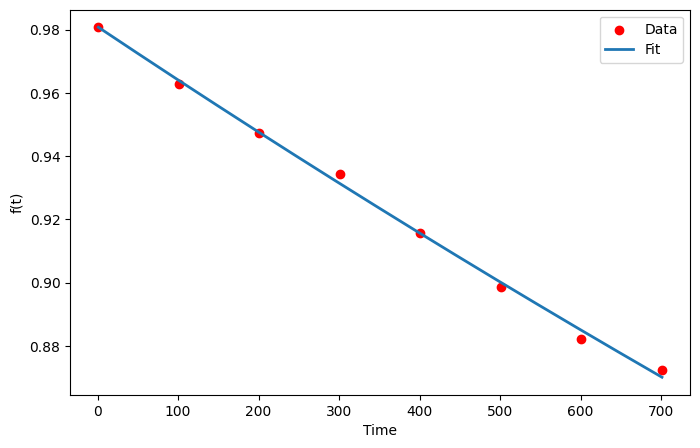

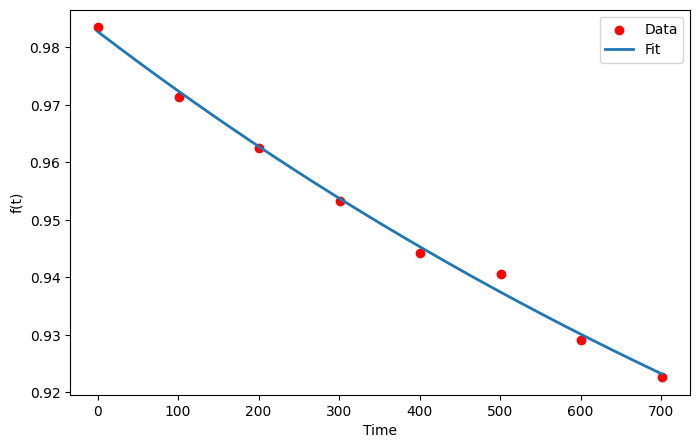

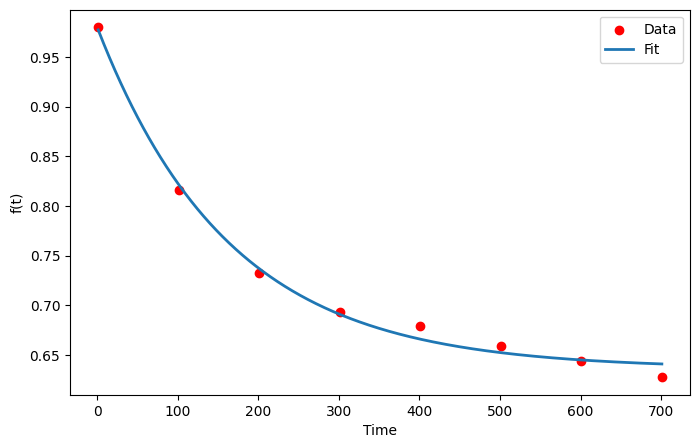

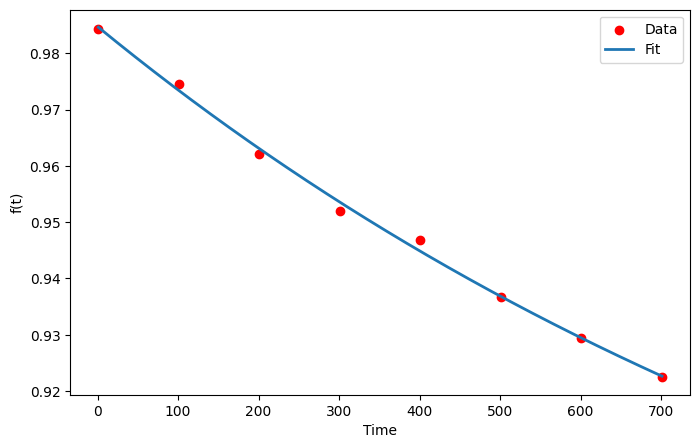

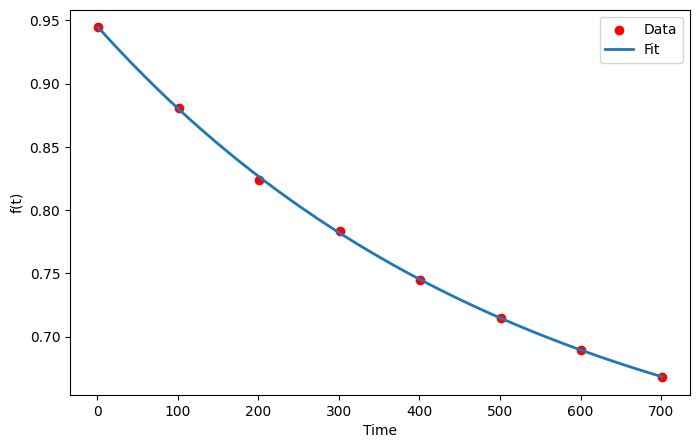

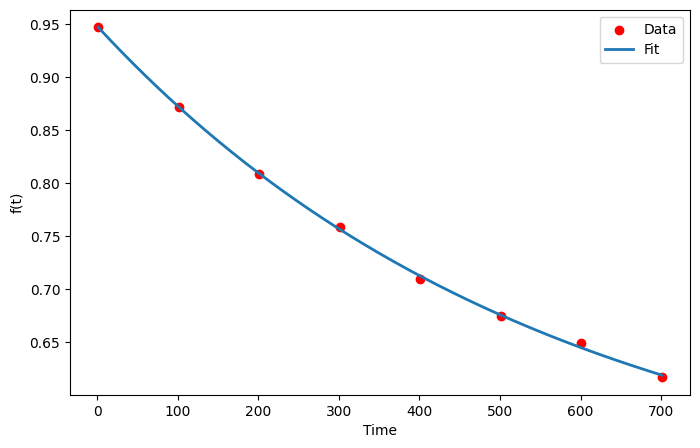

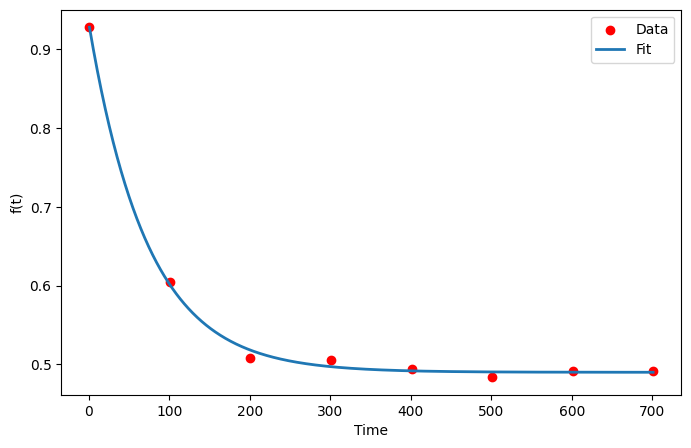

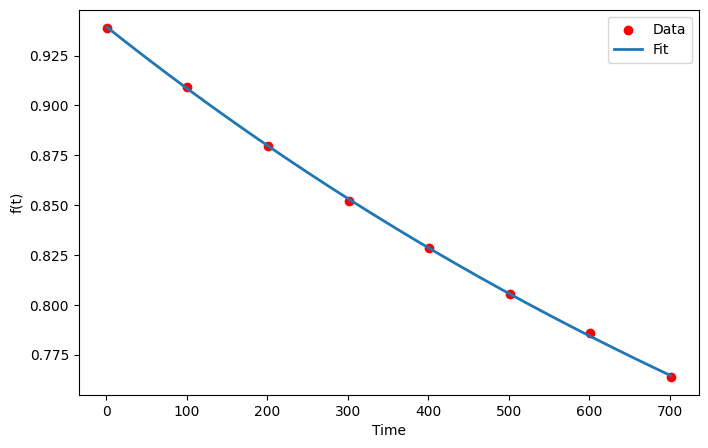

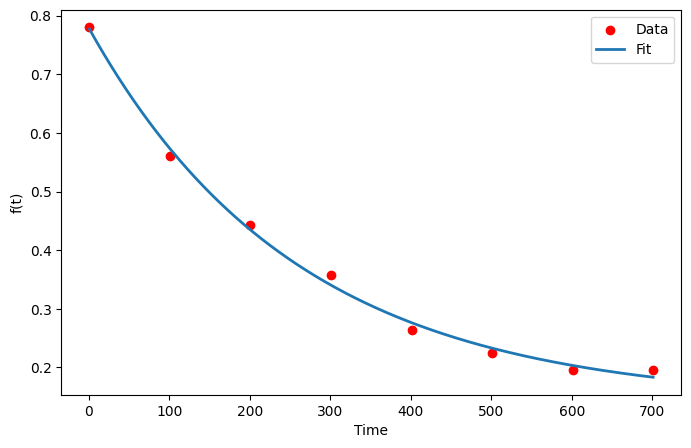

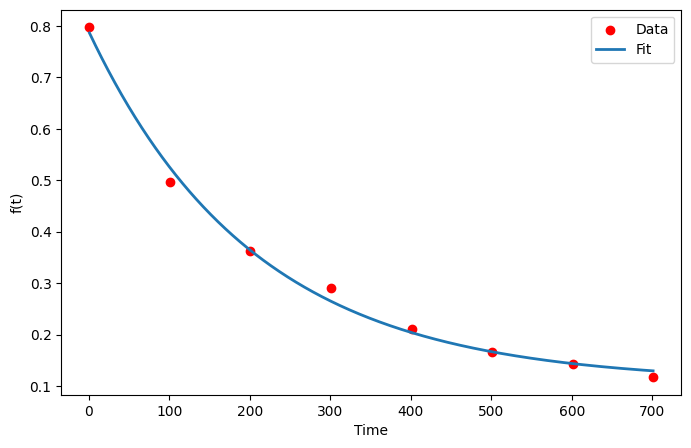

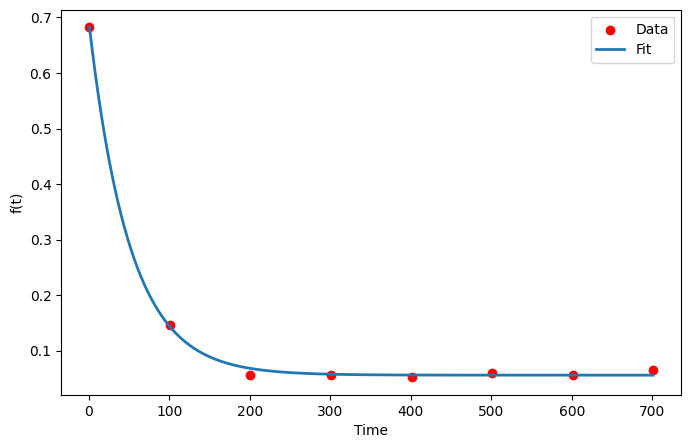

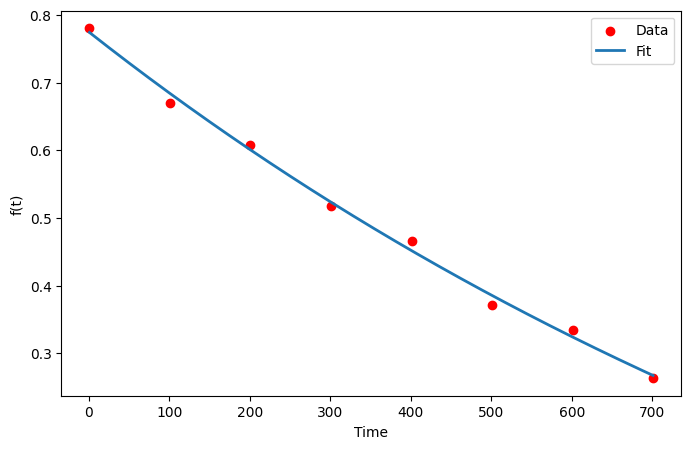

In [340]:
data_dict = {
    "robust_iso_avg":         robust_iso_avg,
    "dephasing_iso_avg":       dephasing_iso_avg,
    "gaussian_iso_avg":        gaussian_iso_avg,
    "default_iso_avg":         default_iso_avg,
    "robust_sim_avg":          robust_sim_avg,
    "dephasing_sim_avg":       dephasing_sim_avg,
    "gaussian_sim_avg":        gaussian_sim_avg,
    "default_sim_avg":         default_sim_avg,
    "rb_robust_total_counts":  rb_robust_total_counts,
    "rb_dephasing_total_counts": rb_dephasing_total_counts,
    "rb_gaussian_total_counts":  rb_gaussian_total_counts,
    "rb_default_total_counts":   rb_default_total_counts,
}

# ----- Apply the Fitting Routine and Store the Results -----
fit_results = {}

for key, y_data in data_dict.items():
    alpha, alpha_err = fit_depolarizing(rb_lengths, y_data, plot=True)
    # Store the result in the dictionary.
    fit_results[key] = {"alpha": alpha, "alpha_err": alpha_err}

In [341]:
for key, result in fit_results.items():
    print(f"{key}: alpha = {result['alpha']:.4f}, error = {result['alpha_err']:.4f}")

robust_iso_avg: alpha = 0.9998, error = 0.0002
dephasing_iso_avg: alpha = 0.9993, error = 0.0003
gaussian_iso_avg: alpha = 0.9939, error = 0.0005
default_iso_avg: alpha = 0.9992, error = 0.0002
robust_sim_avg: alpha = 0.9981, error = 0.0001
dephasing_sim_avg: alpha = 0.9982, error = 0.0001
gaussian_sim_avg: alpha = 0.9864, error = 0.0007
default_sim_avg: alpha = 0.9993, error = 0.0001
rb_robust_total_counts: alpha = 0.9961, error = 0.0003
rb_dephasing_total_counts: alpha = 0.9951, error = 0.0004
rb_gaussian_total_counts: alpha = 0.9805, error = 0.0009
rb_default_total_counts: alpha = 0.9992, error = 0.0003


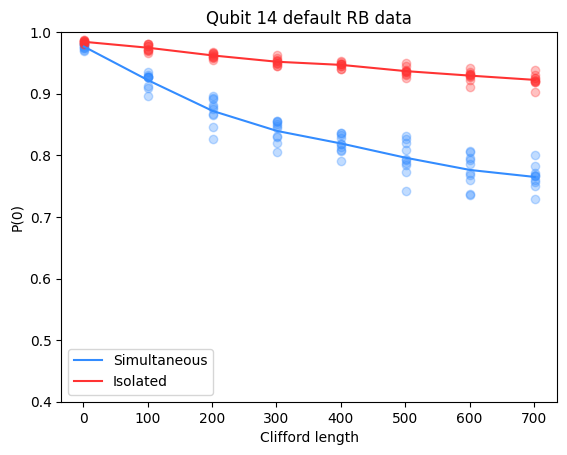

In [645]:
# p0_default = {}
# for d in rb_default_data[qubit_for_rb_data].data():
#     if d["metadata"]["xval"] not in p0_default:
#         p0_default[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
#     else:
#         p0_default[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

# p0_default_iso = {}
# for d in default_iso_data.data():
#     if d["metadata"]["xval"] not in p0_default_iso:
#         p0_default_iso[d["metadata"]["xval"]] = [d["counts"]["0"] / 2048]
#     else:
#         p0_default_iso[d["metadata"]["xval"]].append(d["counts"]["0"] / 2048)

# plt.plot(p0_default.keys(), [np.average(v) for v in p0_default.values()], label="Simultaneous", c="#338cff")
# for key in p0_default.keys():
#     plt.scatter([key] * len(p0_default[key]), p0_default[key], alpha=0.3, c="#338cff")

# plt.plot(p0_default_iso.keys(), [np.average(v) for v in p0_default_iso.values()], label="Isolated", c="#ff3333")
# for key in p0_default_iso.keys():
#     plt.scatter([key] * len(p0_default_iso[key]), p0_default_iso[key], alpha=0.3, c="#ff3333")

# plt.ylim(0.4, 1.0)
# plt.title(f"Qubit {rb_qubits[qubit_for_rb_data]} default RB data")
# plt.ylabel("P(0)")
# plt.xlabel("Clifford length")
# plt.legend();

## Custom ECR

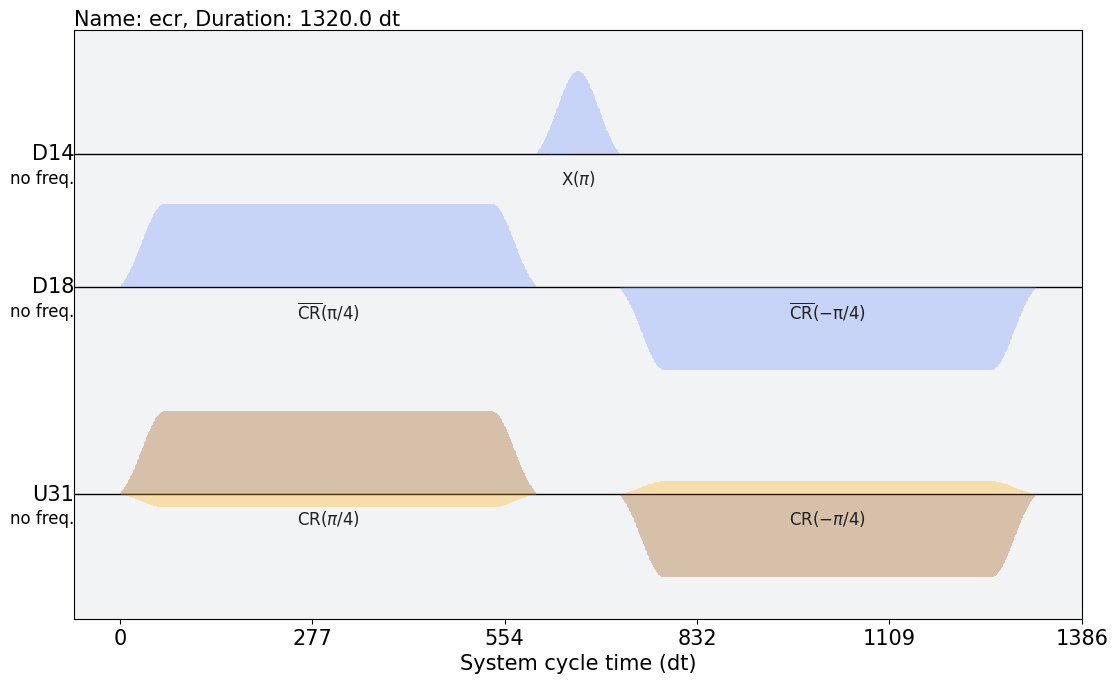

In [144]:
ecr_sched = backend.instruction_schedule_map.get("ecr", (qubit1, qubit0))
ecr_sched.draw()

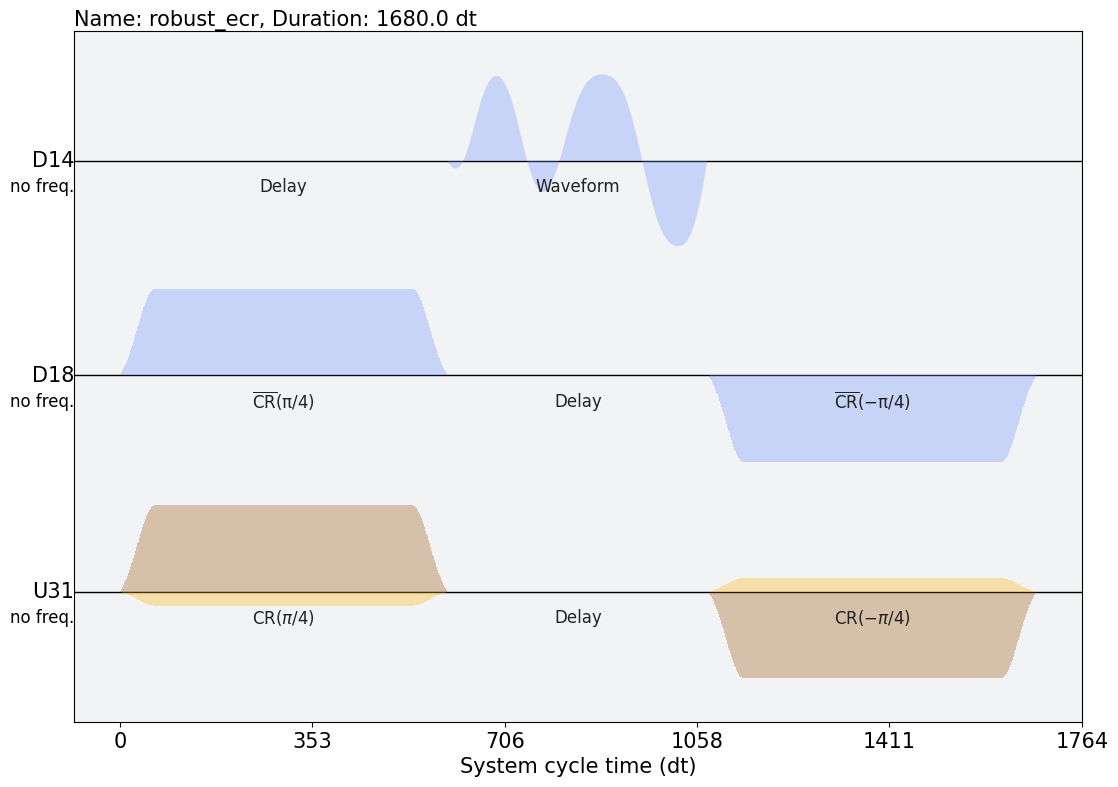

In [145]:
def get_robust_ecr(x_sched, q0, original_ecr):
    with qk.pulse.build(name=f"robust_ecr", backend=backend) as sched:
        sched.append(original_ecr.instructions[0][1])
        sched.append(original_ecr.instructions[1][1])
        
        qk.pulse.delay(original_ecr.instructions[0][1].duration, qk.pulse.DriveChannel(q0))
        sched.append(x_sched)
        qk.pulse.delay(duration, original_ecr.instructions[3][1].channel)
        qk.pulse.delay(duration, original_ecr.instructions[4][1].channel)
        

        sched.append(original_ecr.instructions[3][1])
        sched.append(original_ecr.instructions[4][1])

    return sched

robust_ecr = get_robust_ecr(fine_q1_x2, qubit1, ecr_sched)
robust_ecr.draw()

In [146]:
default_ecr_q1_q0 = backend.instruction_schedule_map.get("ecr", (qubit1, qubit0))
default_ecr_q1_q2 = backend.instruction_schedule_map.get("ecr", (qubit1, qubit2))
default_ecr_q3_q2 = backend.instruction_schedule_map.get("ecr", (qubit3, qubit2))

robust_ecr_q1_q0 = get_robust_ecr(fine_q1_x2, qubit1, default_ecr_q1_q0)
robust_ecr_q1_q2 = get_robust_ecr(fine_q1_x2, qubit1, default_ecr_q1_q2)
robust_ecr_q3_q2 = get_robust_ecr(fine_q3_x2, qubit3, default_ecr_q3_q2)

# gaussian_ecr_q1_q0 = get_robust_ecr(fine_q1_x2_gaussian, qubit1, default_ecr_q1_q0)
# gaussian_ecr_q1_q2 = get_robust_ecr(fine_q1_x2_gaussian, qubit1, default_ecr_q1_q2)
# gaussian_ecr_q3_q2 = get_robust_ecr(fine_q3_x2_gaussian, qubit3, default_ecr_q3_q2)

## Transverse Ising model

In [252]:
from typing import Union

class TransverseIsingModel:
    def __init__(
        self,
        num_qubits: int,
        quantum_registers: list[int] = [],
        classical_registers: list[int] = [],
        hz: float = 2 * np.pi,
        Jx: float = 2 * np.pi,
        Δt: float = 0.05,
    ):
        """
        Initialize the transverse Ising model.

        Args:
            num_qubit_registers (int): number of qubits in the register
            num_classical_registers (int): number of classical registers
            hz (float): magnetic field along z
            Jx (float): Coupling along x
            Δt (float): time step for integration
        """
        self._N = num_qubits
        self._quantum_registers = quantum_registers
        self._C = len(classical_registers)
        self._hz = hz
        self._Jx = Jx
        self._Δt = Δt

    def create_initial_state(self, num_qubits: int, qr: list[int], cr: int):
        """
        Creates the initial state for the experiment.
        Here we would like to prepare the |+>|+>|+>|+> state.
        """
        circ = qk.QuantumCircuit(num_qubits, cr)
        [circ.h(i) for i in qr]
        return circ

    def rxx(self, circ: qk.QuantumCircuit, θx, q1: int, q2: int):
        """
        Implements the exp(-i theta/2 sx_1 sx_2) gate.
        """
        circ.cx(q1, q2)
        circ.rx(θx, q1)
        circ.cx(q1, q2)
        return circ

    def first_order_Trotter_unitary(
        self, circ: Union[qk.QuantumCircuit, None] = None, barrier=False
    ):
        """
        Applies a Unitary for a single time step U(Δt) using first-order trotter
            expansion to the input quantum circuit.

        input : circ is a quantum circuit
        output : circ-U(Δt)-
        """
        # Initial circuit
        if circ is None:
            circ = self.create_initial_state(self._N, self._quantum_registers, self._C)

        # Layer A: coupling XX between n and n+1
        # Induce parallel CR gates
        if barrier:
            circ.barrier()
        for p in range(0, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
            )
        if barrier:
            circ.barrier()
        for p in range(1, len(self._quantum_registers) - 1, 2):
            circ = self.rxx(
                circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
            )

        # Layer B: on-site Z
        for p in range(len(self._quantum_registers)):
            circ.rz(self._hz * self._Δt, self._quantum_registers[p])

        return circ

    def second_order_Trotter_unitary(
        self, circ: Union[qk.QuantumCircuit, None] = None, repetitions=1, barrier=False, measure=True
    ):
        """
        Applies a Unitary for a single time step U(Δt) using the second-order trotter
            expansion to the input quantum circuit.

        input : circ is a quantum circuit
        output : circ-U(Δt)-
        """
        # Initial circuit
        if circ is None:
            circ = self.create_initial_state(self._N, self._quantum_registers, self._C)

        # Layer 2: on-site Z (half)
        for _ in range(repetitions):
            for p in range(len(self._quantum_registers)):
                circ.rz(self._hz * self._Δt / 2, self._quantum_registers[p])

            # Layer 1: coupling XX between n and n+1
            # Induce parallel structure (and symmetry)
            for p in range(1, len(self._quantum_registers) - 1, 2):
                circ = self.rxx(
                    circ, self._Jx * self._Δt / 2, self._quantum_registers[p], self._quantum_registers[p + 1]
                )
            # Add barriers to separate the parallel section
            if barrier:
                circ.barrier()
            for p in range(0, len(self._quantum_registers) - 1, 2):
                circ = self.rxx(
                    circ, self._Jx * self._Δt, self._quantum_registers[p], self._quantum_registers[p + 1]
                )
            if barrier:
                circ.barrier()
            for p in range(1, len(self._quantum_registers) - 1, 2):
                circ = self.rxx(
                    circ, self._Jx * self._Δt / 2, self._quantum_registers[p], self._quantum_registers[p + 1]
                )

            # Layer 2: on-site Z (half)
            for p in range(len(self._quantum_registers)):
                circ.rz(self._hz * self._Δt / 2, self._quantum_registers[p])

        # Measurement
        if measure:
            circ.barrier()
            for p in range(len(self._quantum_registers)):
                circ.measure(self._quantum_registers[p], p)

        return circ

In [253]:
ising = TransverseIsingModel(num_qubits, [qubit0, qubit1, qubit2, qubit3], [0, 1, 2, 3])
ising_circuit = ising.second_order_Trotter_unitary()
ising_circuit = qk.transpile(ising_circuit, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)
ising_circuit.draw(idle_wires=False)

global phase: π/4
           ┌──────────┐┌────┐ ┌────────────┐┌────┐  ┌──────┐  ┌────────┐┌────┐»
  q_0 -> 0 ┤ Rz(-π/2) ├┤ √X ├─┤ Rz(1.4137) ├┤ √X ├──┤1     ├──┤ Rz(-π) ├┤ √X ├»
           ├──────────┤├────┤ ├───────────┬┘├────┤  │      │  └────────┘└────┘»
  q_1 -> 1 ┤ Rz(-π/2) ├┤ √X ├─┤ Rz(-π/20) ├─┤ √X ├──┤  Ecr ├──────────────────»
           ├─────────┬┘├────┤ └┬──────────┤ └────┘  │      │ ┌─────────┐┌────┐»
q_14 -> 14 ┤ Rz(π/2) ├─┤ √X ├──┤ Rz(π/20) ├─────────┤0     ├─┤ Rz(π/2) ├┤ √X ├»
           ├─────────┴┐├────┤┌─┴──────────┴┐┌────┐┌─┴──────┴┐└─────────┘└────┘»
q_18 -> 18 ┤ Rz(-π/2) ├┤ √X ├┤ Rz(-1.7279) ├┤ √X ├┤ Rz(π/2) ├─────────────────»
           └──────────┘└────┘└─────────────┘└────┘└─────────┘                 »
      c: 4/═══════════════════════════════════════════════════════════════════»
                                                                              »
«            ┌────────┐       ┌──────┐   ┌────┐   ┌──────────┐┌──────┐»
«  q_0 -> 0 ─┤ Rz(-π) ├───────┤1     ├───┤ √X ├───┤ Rz(-π/2) ├┤1     ├»
«            └────────┘       │      │   └────┘   └──────────┘│  Ecr │»
«  q_1 -> 1 ──────────────────┤  Ecr ├────────────────────────┤0     ├»
«           ┌──────────┐┌────┐│      │┌──────────┐   ┌────┐   ├──────┤»
«q_14 -> 14 ┤ Rz(π/20) ├┤ √X ├┤0     ├┤ Rz(-π/2) ├───┤ √X ├───┤0     ├»
«           └──────────┘└────┘└──────┘└──────────┘   └────┘   │  Ecr │»
«q_18 -> 18 ──────────────────────────────────────────────────┤1     ├»
«                                                             └──────┘»
«      c: 4/══════════════════════════════════════════════════════════»
«                                                                     »
«           ┌──────────┐   ┌────┐  ┌──────┐ ┌────────┐ ┌────┐ ┌─────────┐  »
«  q_0 -> 0 ┤ Rz(π/10) ├───┤ √X ├──┤1     ├─┤ Rz(-π) ├─┤ √X ├─┤ Rz(π/2) ├──»
«           └──┬───┬───┘┌──┴────┴─┐│  Ecr │┌┴────────┤ ├────┤┌┴─────────┴─┐»
«  q_1 -> 1 ───┤ X ├────┤ Rz(π/2) ├┤0     ├┤ Rz(π/2) ├─┤ √X ├┤ Rz(1.7279) ├»
«              ├───┤    ├─────────┤├──────┤├─────────┤ ├────┤└────────────┘»
«q_14 -> 14 ───┤ X ├────┤ Rz(π/2) ├┤0     ├┤ Rz(π/2) ├─┤ √X ├──────────────»
«           ┌──┴───┴───┐└──┬────┬─┘│  Ecr │├─────────┴┐├────┤┌────────────┐»
«q_18 -> 18 ┤ Rz(π/10) ├───┤ √X ├──┤1     ├┤ Rz(-π/2) ├┤ √X ├┤ Rz(1.7279) ├»
«           └──────────┘   └────┘  └──────┘└──────────┘└────┘└────────────┘»
«      c: 4/═══════════════════════════════════════════════════════════════»
«                                                                          »
«           ┌──────┐ ┌────────┐┌────┐ ┌────────┐       ┌──────┐┌──────────┐»
«  q_0 -> 0 ┤1     ├─┤ Rz(-π) ├┤ √X ├─┤ Rz(-π) ├───────┤1     ├┤ Rz(π/20) ├»
«           │      │ └────────┘└────┘ └────────┘       │      │└──────────┘»
«  q_1 -> 1 ┤  Ecr ├───────────────────────────────────┤  Ecr ├────────────»
«           │      │┌─────────┐┌────┐┌──────────┐┌────┐│      │   ┌───┐    »
«q_14 -> 14 ┤0     ├┤ Rz(π/2) ├┤ √X ├┤ Rz(π/20) ├┤ √X ├┤0     ├───┤ X ├────»
«           └──────┘└─────────┘└────┘└──────────┘└────┘└──────┘   └───┘    »
«q_18 -> 18 ───────────────────────────────────────────────────────────────»
«                                                                          »
«      c: 4/═══════════════════════════════════════════════════════════════»
«                                                                          »
«                        ░       ┌─┐   
«  q_0 -> 0 ─────────────░───────┤M├───
«                        ░       └╥┘┌─┐
«  q_1 -> 1 ─────────────░────────╫─┤M├
«           ┌──────────┐ ░    ┌─┐ ║ └╥┘
«q_14 -> 14 ┤ Rz(π/20) ├─░────┤M├─╫──╫─
«           └──────────┘ ░ ┌─┐└╥┘ ║  ║ 
«q_18 -> 18 ─────────────░─┤M├─╫──╫──╫─
«                        ░ └╥┘ ║  ║  ║ 
«      c: 4/════════════════╩══╩══╩══╩═
«                           0  1  2  3

In [148]:
all_schedules = [
    [fine_q0_x1, fine_q0_sx1, q0_i1],
    [fine_q1_x2, fine_q1_sx2, q1_i1],
    [fine_q2_x1, fine_q2_sx1, q2_i1],
    [fine_q3_x2, fine_q3_sx2, q3_i1],
    # [fine_q4_x1, fine_q4_sx1, q4_i1],
    # [fine_q5_x2, fine_q5_sx2, fine_q5_i2],
    # [fine_q6_x1, fine_q6_sx1, q6_i1],
    # [fine_q7_x2, fine_q7_sx2, fine_q7_i2]
]

# gaussian_schedules = [
#     [fine_q0_x1_gaussian, fine_q0_sx1_gaussian, q0_i1],
#     [fine_q1_x2_gaussian, fine_q1_sx2_gaussian, q1_i1],
#     [fine_q2_x1_gaussian, fine_q2_sx1_gaussian, q2_i1],
#     [fine_q3_x2_gaussian, fine_q3_sx2_gaussian, q3_i1],
# ]

ising_qubits = [qubit0, qubit1, qubit2, qubit3]#, qubit4, qubit5, qubit6, qubit7]

In [149]:
ising_circuit_2x_depth = ising.second_order_Trotter_unitary(repetitions=2)
ising_circuit_2x_depth = qk.transpile(ising_circuit_2x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_3x_depth = ising.second_order_Trotter_unitary(repetitions=3)
ising_circuit_3x_depth = qk.transpile(ising_circuit_3x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_4x_depth = ising.second_order_Trotter_unitary(repetitions=4)
ising_circuit_4x_depth = qk.transpile(ising_circuit_4x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_5x_depth = ising.second_order_Trotter_unitary(repetitions=5)
ising_circuit_5x_depth = qk.transpile(ising_circuit_5x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_6x_depth = ising.second_order_Trotter_unitary(repetitions=6)
ising_circuit_6x_depth = qk.transpile(ising_circuit_6x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_7x_depth = ising.second_order_Trotter_unitary(repetitions=7)
ising_circuit_7x_depth = qk.transpile(ising_circuit_7x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

ising_circuit_8x_depth = ising.second_order_Trotter_unitary(repetitions=8)
ising_circuit_8x_depth = qk.transpile(ising_circuit_8x_depth, basis_gates=["x", "sx", "rz", "id", "ecr"], coupling_map=backend.coupling_map)

In [150]:
ising_circuits = [ising_circuit, ising_circuit_2x_depth, ising_circuit_3x_depth, ising_circuit_4x_depth, ising_circuit_5x_depth, ising_circuit_6x_depth, ising_circuit_7x_depth, ising_circuit_8x_depth]

In [151]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

sim_counts = []

for circuit in ising_circuits:
    simulator = AerSimulator()
    sim_result = simulator.run(circuit, shots=2048).result()
    sim_counts.append(sim_result.get_counts(circuit))

In [155]:
ising_robust_circuits = []
ising_robust_2q_circuits = []
ising_gaussian_circuits = []
ising_gaussian_2q_circuits = []
ising_default_circuits = []

for circuit in ising_circuits:
    ising_circuit_robust = circuit.copy()
    ising_circuit_robust_2q = circuit.copy()
    ising_circuit_gaussian = circuit.copy()
    ising_circuit_gaussian_2q = circuit.copy()
    ising_circuit_default = circuit.copy()

    for i, qubit in enumerate(ising_qubits):
        qubit_schedules = all_schedules[i]
        # gaussian_qubit_schedules = gaussian_schedules[i]

        ising_circuit_robust.add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
        ising_circuit_robust.add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
        ising_circuit_robust.add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

        # ising_circuit_robust_2q.add_calibration(qk.circuit.library.XGate(), (qubit,), qubit_schedules[0])
        # ising_circuit_robust_2q.add_calibration(qk.circuit.library.SXGate(), (qubit,), qubit_schedules[1])
        # ising_circuit_robust_2q.add_calibration(qk.circuit.library.IGate(), (qubit,), qubit_schedules[2])

        # ising_circuit_gaussian.add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
        # ising_circuit_gaussian.add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
        # ising_circuit_gaussian.add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

        # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.XGate(), (qubit,), gaussian_qubit_schedules[0])
        # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.SXGate(), (qubit,), gaussian_qubit_schedules[1])
        # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.IGate(), (qubit,), gaussian_qubit_schedules[2])

    # ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit2), robust_ecr_q1_q2)
    # ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit0), robust_ecr_q1_q0)
    # ising_circuit_robust_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit3, qubit2), robust_ecr_q3_q2)

    # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit2), gaussian_ecr_q1_q2)
    # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit1, qubit0), gaussian_ecr_q1_q0)
    # ising_circuit_gaussian_2q.add_calibration(qk.circuit.library.ECRGate(), (qubit3, qubit2), gaussian_ecr_q3_q2)

    ising_robust_circuits.append(ising_circuit_robust)
    ising_default_circuits.append(ising_circuit_default)
    # ising_robust_2q_circuits.append(ising_circuit_robust_2q)
    # ising_gaussian_circuits.append(ising_circuit_gaussian)

In [274]:
ising_default = sampler.run(ising_default_circuits, shots=2048)
# ising_robust = sampler.run(ising_robust_circuits, shots=2048)
# ising_robust_2q = sampler.run(ising_robust_2q_circuits, shots=2048)
# ising_gaussian = sampler.run(ising_gaussian_circuits, shots=2048)
# ising_gaussian_2q = sampler.run([ising_circuit_gaussian_2q], shots=2048)

In [335]:
ising_default.job_id(), ising_default.status()

('cy04ajtcw2k0008jckjg', 'DONE')

In [107]:
ising_gaussian.job_id(), ising_gaussian.status()

('cws6dxq5v39g008ha46g', 'DONE')

In [182]:
ising_robust.job_id(), ising_robust_2q.job_id()

('cwcvz9djyrs0008ef2x0', 'cwcvzbd2802g008kknd0')

In [183]:
ising_robust.status(), ising_robust_2q.status()

('DONE', 'DONE')

In [ ]:
ising_default.job_id(), ising_robust.job_id(), ising_robust_2q.job_id(), ising_gaussian.job_id(), ising_gaussian_2q.job_id()

In [ ]:
ising_default.status(), ising_robust.status(), ising_robust_2q.status(), ising_gaussian.status(), ising_gaussian_2q.status()

In [336]:
ising_default = service.job("cy04ajtcw2k0008jckjg")
ising_robust = service.job("cws71axtdtng0086zswg")
ising_dephasing_robust = service.job("cwy1yrb2ac5g008jmb20")
# ising_robust_2q = service.job("cwcvzbd2802g008kknd0")
ising_gaussian = service.job("cws6dxq5v39g008ha46g")
# ising_gaussian_2q = service.job("cw5z5ppxa9wg0082cnh0")

In [257]:
ising_dephasing_robust.job_id(), ising_dephasing_robust.status()

('cwy1yrb2ac5g008jmb20', <JobStatus.DONE: 'job has successfully run'>)

In [ ]:
for idx in range(len(ising_robust.result())):
    plot_histogram(
        [
            sim_counts[idx], 
            # ising_robust.result()[idx]["__value__"]["data"].c.get_counts(),
            # ising_robust_2q.result()[idx]["__value__"]["data"].c.get_counts(),
            ising_gaussian.result()[idx]["__value__"]["data"].c.get_counts(), 
            # ising_gaussian_2q.result()[idx]["__value__"]["data"].c.get_counts(), 
            # ising_default.result()[idx]["__value__"]["data"].c.get_counts()
        ], 
        legend = [
            "sim",
            "robust", 
            "robust2q", 
            "gaussian", 
            # "gaussian2q", 
            # "default"
        ]
    )
    plt.show()

In [ ]:
ising_robust.result()[0]["__value__"]["data"].c.expectation_values("ZZZZ"), ising_robust_2q.result()[0]["__value__"]["data"].c.expectation_values("ZZZZ"), ising_gaussian.result()[0]["__value__"]["data"].c.expectation_values("ZZZZ"), #ising_gaussian_2q.result()[0].data.c.expectation_values("ZZZZ"), ising_default.result()[0].data.c.expectation_values("ZZZZ"),

In [259]:
observable = qk.quantum_info.Pauli('ZZZZ') 
ising_for_op = TransverseIsingModel(4, [0, 1, 2, 3], [])
ising_op = qk.quantum_info.Statevector(ising_for_op.second_order_Trotter_unitary(measure=False))
ising_op.expectation_value(observable)

-4.85722573273506e-17

In [260]:
observable = qk.quantum_info.Pauli('ZZZZ') 
ising_for_op = TransverseIsingModel(4, [0, 1, 2, 3], [])
ising_ops = [qk.quantum_info.Statevector(ising_for_op.second_order_Trotter_unitary(measure=False, repetitions=i)) for i in [1, 2, 4, 8]]
ising_ops_gaussian = [qk.quantum_info.Statevector(ising_for_op.second_order_Trotter_unitary(measure=False, repetitions=i)) for i in [1, 2, 3, 4, 5, 6, 7, 8]]

In [ ]:
for i in range(len(ising_ops)):
    print(f"Expectation value for {2**i} repetitions:", ising_ops[i].expectation_value(observable))
    # print("    Default expectation value:", ising_default.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ"))
    print()
    print("    Robust (2x length) expectation value:", ising_robust.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ"))
    print("    Gaussian (2x length) expectation value:", ising_gaussian.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ"))
    print()
    # print("    Robust 2q (2x length) expectation value:", ising_robust_2q.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ"))
    # print("    Gaussian 2q (2x length) expectation value:", ising_gaussian_2q.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ"))

Expectation value for 1 repetitions: -4.85722573273506e-17

    Robust (2x length) expectation value: -0.00390625
    Gaussian (2x length) expectation value: 0.0673828125

Expectation value for 2 repetitions: -6.938893903907228e-17

    Robust (2x length) expectation value: -0.0146484375
    Gaussian (2x length) expectation value: -0.0166015625

Expectation value for 4 repetitions: -3.5995512126518747e-16

    Robust (2x length) expectation value: 0.001953125
    Gaussian (2x length) expectation value: -0.01171875

Expectation value for 8 repetitions: -9.71445146547012e-16

    Robust (2x length) expectation value: 0.033203125
    Gaussian (2x length) expectation value: 0.05859375



In [338]:
ideal_expected_values = [ising_ops_gaussian.expectation_value(observable) for ising_ops_gaussian in ising_ops_gaussian]
robust_expected_values = [ising_robust.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ") for i in range(len(ising_ops_gaussian))]
# robust_2q_expected_values = [ising_robust_2q.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ") for i in range(len(ising_ops))]
gaussian_expected_values = [ising_gaussian.result()[i]["__value__"]["data"].c.expectation_values("ZZZZ") for i in range(len(ising_ops_gaussian))]

In [339]:
robust_expected_values

[array(-0.00390625),
 array(-0.01464844),
 array(0.00195312),
 array(0.03320312),
 array(0.03417969),
 array(0.05957031),
 array(0.09375),
 array(0.11328125)]

In [340]:
def get_parity(s):
    parity = 1
    for i in range(len(s)):
        parity *= (-1) ** int(s[i])
    return parity

In [341]:
robust_std = []
for i in range(len(ising_ops_gaussian)):
    values = []
    counts = ising_robust.result()[i]["__value__"]["data"].c.get_counts()
    for b in counts:
        values += [get_parity(b)] * counts[b]
    robust_std.append(np.std(values))

# robust_2q_std = []
# for i in range(len(ising_ops)):
#     values = []
#     counts = ising_robust_2q.result()[i]["__value__"]["data"].c.get_counts()
#     for b in counts:
#         values += [get_parity(b)] * counts[b]
#     robust_2q_std.append(np.std(values))

gaussian_std = []
for i in range(len(ising_ops_gaussian)):
    values = []
    counts = ising_gaussian.result()[i]["__value__"]["data"].c.get_counts()
    for b in counts:
        values += [get_parity(b)] * counts[b]
    gaussian_std.append(np.std(values))

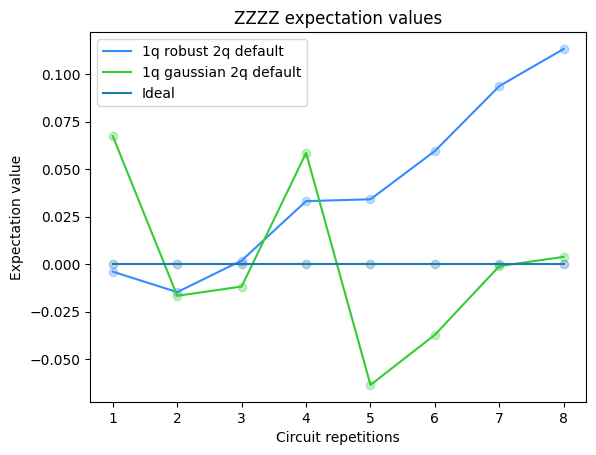

In [444]:
plt.plot([1, 2, 3, 4, 5, 6, 7, 8], robust_expected_values, label="1q robust 2q default", c="#338cff")
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], robust_expected_values, alpha=0.3, c="#338cff")

# plt.plot([1, 2, 4, 8], robust_2q_expected_values, label="1q robust 2q robust", c="#ff3333")
# plt.scatter([1, 2, 4, 8], robust_2q_expected_values, alpha=0.3, c="#ff3333")

plt.plot([1, 2, 3, 4, 5, 6, 7, 8], gaussian_expected_values, label="1q gaussian 2q default", c= "#33cc33")
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], gaussian_expected_values, alpha=0.3, c= "#33cc33")

plt.plot([1, 2, 3, 4, 5, 6, 7, 8], ideal_expected_values, label="Ideal")
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], ideal_expected_values, alpha=0.3)

plt.title(f"ZZZZ expectation values")
plt.ylabel("Expectation value")
plt.xlabel("Circuit repetitions")
plt.legend();

In [342]:
def kl_divergence(p, q):
    dist = 0
    for k in p.keys():
        dist += p.get(k, 0) * np.log(p.get(k, 0) / q.get(k, 0))
    return dist

In [343]:
num_states = 2 ** 4
probability = 1 / num_states
totally_mixed_distribution = {f"{i:04b}": probability for i in range(num_states)}

In [344]:
ideal_probs = ising_ops_gaussian[0].probabilities_dict()
robust_probs = {k: v / 2048 for k, v in ising_robust.result()[0]["__value__"]["data"].c.get_counts().items()}
dephasing_robust_probs = {k: v / 2048 for k, v in ising_dephasing_robust.result()[0]["__value__"]["data"].c.get_counts().items()}
# robust_2q_probs = {k: v / 2048 for k, v in ising_robust_2q.result()[0]["__value__"]["data"].c.get_counts().items()}
gaussian_probs = {k: v / 2048 for k, v in ising_gaussian.result()[0]["__value__"]["data"].c.get_counts().items()}
# gaussian_2q_probs = {k: v / 2048 for k, v in ising_gaussian_2q.result()[0].data.c.get_counts().items()}
default_probs = {k: v / 2048 for k, v in ising_default.result()[0]["__value__"]["data"].c.get_counts().items()}

In [1086]:
all_robust_probs = []
for result in ising_robust.result():
    counts = {k : v / 2048 for k, v in result["__value__"]["data"].c.get_counts().items()}
    all_robust_probs.append(counts)

all_gaussian_probs = []
for result in ising_gaussian.result():
    counts = {k : v / 2048 for k, v in result["__value__"]["data"].c.get_counts().items()}
    all_gaussian_probs.append(counts)

all_dephasing_robust_probs = []
for result in ising_dephasing_robust.result():
    counts = {k : v / 2048 for k, v in result["__value__"]["data"].c.get_counts().items()}
    all_dephasing_robust_probs.append(counts)

all_default_probs = []
for result in ising_default.result():
    counts = {k : v / 2048 for k, v in result["__value__"]["data"].c.get_counts().items()}
    all_default_probs.append(counts)

In [1045]:
import random
chosen_element = random.choices(list(counts.keys()), weights=list(counts.values()))[0]
chosen_element

'0110'

In [345]:
kl_divergence(dephasing_robust_probs, robust_probs), kl_divergence(dephasing_robust_probs, ideal_probs), kl_divergence(robust_probs, ideal_probs)

(0.013752019052707842, 0.008559138286620055, 0.008295808045263864)

In [346]:
# print("Default KL divergence: ", kl_divergence(default_probs, ideal_probs))
print()
print("Robust KL divergence: ", kl_divergence(robust_probs, ideal_probs))
print("Gaussian KL divergence: ", kl_divergence(gaussian_probs, ideal_probs))
print()
# print("Robust 2-qubit KL divergence: ", kl_divergence(robust_2q_probs, ideal_probs))
# print("Gaussian 2-qubit KL divergence: ", kl_divergence(gaussian_2q_probs, ideal_probs))


Robust KL divergence:  0.008295808045263864
Gaussian KL divergence:  0.4523231610583227



In [350]:
robust_kl_divergences = []
robust_2q_kl_divergences = []
gaussian_kl_divergences = []
totally_mixed_divergence = []
default_divergence = []

dephasing_robust_kl_divergences = []

for i in range(len(ising_ops_gaussian)):
    ideal_probs = ising_ops_gaussian[i].probabilities_dict()
    print(ideal_probs)

    robust_probs = {k: v / 2048 for k, v in ising_robust.result()[i]["__value__"]["data"].c.get_counts().items()}
    # robust_2q_probs = {k: v / 2048 for k, v in ising_robust_2q.result()[i]["__value__"]["data"].c.get_counts().items()}
    gaussian_probs = {k: v / 2048 for k, v in ising_gaussian.result()[i]["__value__"]["data"].c.get_counts().items()}

    robust_kl_divergences.append(kl_divergence(robust_probs, ideal_probs))
    # robust_2q_kl_divergences.append(kl_divergence(robust_2q_probs, ideal_probs))
    gaussian_kl_divergences.append(kl_divergence(gaussian_probs, ideal_probs))

    dephasing_robust_probs = {k: v / 2048 for k, v in ising_dephasing_robust.result()[i]["__value__"]["data"].c.get_counts().items()}
    dephasing_robust_kl_divergences.append(kl_divergence(dephasing_robust_probs, ideal_probs))

    totally_mixed_divergence.append(kl_divergence(totally_mixed_distribution, ideal_probs))

    default_probs = {k: v / 2048 for k, v in ising_default.result()[i]["__value__"]["data"].c.get_counts().items()}
    default_divergence.append(kl_divergence(default_probs, ideal_probs))

# for i in range(len(ising_ops_gaussian)):
#     gaussian_probs = {k: v / 2048 for k, v in ising_gaussian.result()[i]["__value__"]["data"].c.get_counts().items()}
#     gaussian_kl_divergences.append(kl_divergence(gaussian_probs, ideal_probs))

{'0000': 0.0806542220957581, '0001': 0.0738522270000837, '0010': 0.06846821892578288, '0011': 0.061666223830108474, '0100': 0.06846821892578288, '0101': 0.06276386197555428, '0110': 0.0568521299501448, '0111': 0.0511477729999162, '1000': 0.07385222700008373, '1001': 0.0676201460987465, '1010': 0.06276386197555425, '1011': 0.05653178107421706, '1100': 0.06166622383010849, '1101': 0.05653178107421705, '1110': 0.05114777299991621, '1111': 0.046013330244024785}
{'0000': 0.13228862947734918, '0001': 0.10002372694168357, '0010': 0.08329782697979496, '0011': 0.052281466392701176, '0100': 0.08329782697979508, '0101': 0.0648287246818392, '0110': 0.04291986447832287, '0111': 0.025699304128938897, '1000': 0.10002372694168357, '1001': 0.07534512999745861, '1010': 0.06482872468183917, '1011': 0.040979141949582375, '1100': 0.052281466392701176, '1101': 0.04097914194958236, '1110': 0.025699304128938904, '1111': 0.015225993897788214}
{'0000': 0.2012324246644855, '0001': 0.12246290111111431, '0010': 0.

In [351]:
print("Total mixed divergences: ", totally_mixed_divergence)
print("Robust divergences:", robust_kl_divergences)
print("Gaussian divergences:", gaussian_kl_divergences)

Total mixed divergences:  [0.010690986601547462, 0.14011032348928218, 0.6937235421324301, 1.0036173475600134, 1.0819409283823629, 0.5372742579902937, 0.5558126328929522, 0.7940148154243685]
Robust divergences: [0.008295808045263864, 0.04824710039890751, 0.12730045693991995, 0.28971416327966265, 0.3898174728046436, 0.22115956142173612, 0.34040597452440796, 0.6384713163539459]
Gaussian divergences: [0.4523231610583227, 0.464815532045137, 0.5856644104465832, 1.2306985726169437, 1.49413602088383, 0.5028549849689042, 0.7494676043514028, 0.798532053043739]


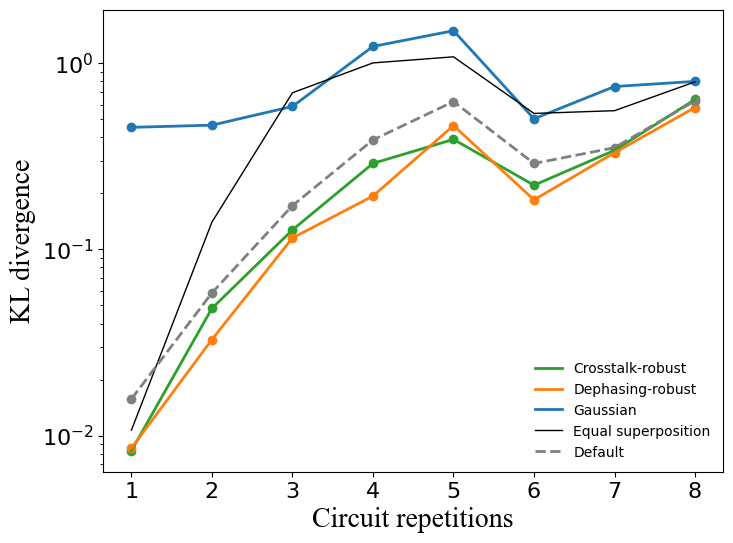

In [1069]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
font = {"fontname": "Times New Roman", "size": 20}

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], robust_kl_divergences, label="Crosstalk-robust", c="#2ca02c", linewidth=2)
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], robust_kl_divergences, c="#2ca02c")

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], dephasing_robust_kl_divergences, label="Dephasing-robust", c="#ff7f0e", linewidth=2)
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], dephasing_robust_kl_divergences, c="#ff7f0e")

# plt.plot([1, 2, 4, 8], robust_2q_kl_divergences, label="1q robust 2q robust", c="#ff3333")
# plt.scatter([1, 2, 4, 8], robust_2q_kl_divergences, alpha=0.3, c="#ff3333")

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], gaussian_kl_divergences, label="Gaussian", c="#1f77b4", linewidth=2)
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], gaussian_kl_divergences, c="#1f77b4")

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], totally_mixed_divergence, label="Equal superposition", c="#000000", linewidth=1)
# plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], totally_mixed_divergence, c="#000000")

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], default_divergence, label="Default", c="#808080", linestyle='dashed', linewidth=2)
plt.scatter([1, 2, 3, 4, 5, 6, 7, 8], default_divergence, c="#808080")

ax.set_yscale('log')
ax.set_ylabel("KL divergence", **font)
ax.set_xlabel("Circuit repetitions", **font)
ax.legend(frameon=False)

ax.xaxis.set_tick_params(labelsize=16)
ax.yaxis.set_tick_params(labelsize=16)

plt.savefig("tfim_divergence.pdf", format="pdf", dpi=300, bbox_inches="tight")

In [1276]:
def kl_bootsrapping(all_counts, ideal_probs, n = 2048, k = 1000):
    avg = []
    err = []

    for i in range(len(all_counts)):
        prob_dict = all_counts[i]
        kl_divs = []

        # Get k bootstrapped samples
        for _ in range(k):
            bootstrap_sample = random.choices(list(prob_dict.keys()), weights=list(prob_dict.values()), k=n)
            bootstrap_sample_dict = {k: 0 for k in prob_dict.keys()}
            for s in bootstrap_sample:
                bootstrap_sample_dict[s] += 1 / n
            print(bootstrap_sample_dict)
            kl_divs.append(kl_divergence(ideal_probs[i], bootstrap_sample_dict))

        avg.append(np.average(kl_divs))
        err.append(np.std(kl_divs))

    return avg, err

In [1277]:
kl_bootsrapping(all_robust_probs, ideal_probs_list, k=1000)

{'1111': 0.0478515625, '0001': 0.06396484375, '0000': 0.07861328125, '0010': 0.0859375, '0100': 0.06689453125, '1000': 0.06396484375, '0110': 0.06396484375, '1011': 0.05126953125, '1110': 0.0498046875, '0011': 0.07177734375, '0101': 0.06494140625, '1101': 0.07275390625, '1001': 0.0654296875, '0111': 0.04931640625, '1100': 0.0478515625, '1010': 0.0556640625}
{'1111': 0.0537109375, '0001': 0.06396484375, '0000': 0.07275390625, '0010': 0.0869140625, '0100': 0.06201171875, '1000': 0.05712890625, '0110': 0.05712890625, '1011': 0.0498046875, '1110': 0.04638671875, '0011': 0.0859375, '0101': 0.076171875, '1101': 0.0673828125, '1001': 0.060546875, '0111': 0.05224609375, '1100': 0.04736328125, '1010': 0.060546875}
{'1111': 0.04296875, '0001': 0.0537109375, '0000': 0.06884765625, '0010': 0.0869140625, '0100': 0.07861328125, '1000': 0.05810546875, '0110': 0.05078125, '1011': 0.0546875, '1110': 0.04833984375, '0011': 0.080078125, '0101': 0.06689453125, '1101': 0.0634765625, '1001': 0.0703125, '011

([0.012122733069779986,
  0.050186313732724815,
  0.09017202791419357,
  0.15769843070507164,
  0.15196979379586684,
  0.17724104915121142,
  0.26413618633773506,
  0.4135482468601639],
 [0.0032077577374383295,
  0.0067666002311262815,
  0.008333068150496021,
  0.011353381503959247,
  0.011049552820588306,
  0.013190827822072176,
  0.015545896408176087,
  0.01962389992015804])

In [1251]:
ideal_probs_list = [ising_ops_gaussian[i].probabilities_dict() for i in range(len(ising_ops_gaussian))]

robust_kl_avg, robust_kl_error = kl_bootsrapping(all_robust_probs, ideal_probs_list, k=1000)
gaussian_kl_avg, gaussian_kl_error = kl_bootsrapping(all_gaussian_probs, ideal_probs_list, k=1000)
dephasing_robust_kl_avg, dephasing_robust_kl_error = kl_bootsrapping(all_dephasing_robust_probs, ideal_probs_list, k=1000)
default_kl_avg, default_kl_error = kl_bootsrapping(all_default_probs, ideal_probs_list, k=1000)

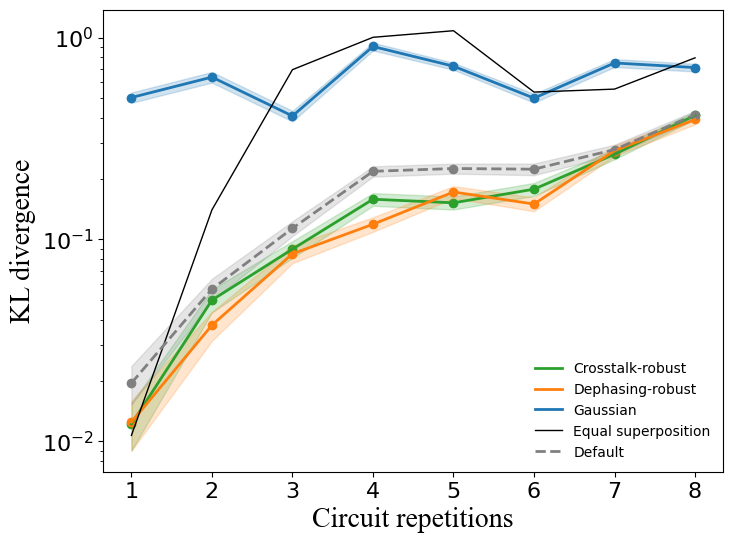

In [1174]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
font = {"fontname": "Times New Roman", "size": 20}

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], robust_kl_avg, label="Crosstalk-robust", c="#2ca02c", linewidth=2)
ax.scatter([1, 2, 3, 4, 5, 6, 7, 8], robust_kl_avg, c="#2ca02c")
ax.fill_between(
    [1, 2, 3, 4, 5, 6, 7, 8],
    np.array(robust_kl_avg) - np.array(robust_kl_error),
    np.array(robust_kl_avg) + np.array(robust_kl_error),
    color="#2ca02c", alpha=0.2
)

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], dephasing_robust_kl_avg, label="Dephasing-robust", c="#ff7f0e", linewidth=2)
ax.scatter([1, 2, 3, 4, 5, 6, 7, 8], dephasing_robust_kl_avg, c="#ff7f0e")
ax.fill_between(
    [1, 2, 3, 4, 5, 6, 7, 8],
    np.array(dephasing_robust_kl_avg) - np.array(dephasing_robust_kl_error),
    np.array(dephasing_robust_kl_avg) + np.array(dephasing_robust_kl_error),
    color="#ff7f0e", alpha=0.2
)

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], gaussian_kl_avg, label="Gaussian", c="#1f77b4", linewidth=2)
ax.scatter([1, 2, 3, 4, 5, 6, 7, 8], gaussian_kl_avg, c="#1f77b4")
ax.fill_between(
    [1, 2, 3, 4, 5, 6, 7, 8],
    np.array(gaussian_kl_avg) - np.array(gaussian_kl_error),
    np.array(gaussian_kl_avg) + np.array(gaussian_kl_error),
    color="#1f77b4", alpha=0.2
)

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], totally_mixed_divergence, label="Equal superposition", c="#000000", linewidth=1)

ax.plot([1, 2, 3, 4, 5, 6, 7, 8], default_kl_avg, label="Default", c="#808080", linestyle='dashed', linewidth=2)
ax.scatter([1, 2, 3, 4, 5, 6, 7, 8], default_kl_avg, c="#808080")
ax.fill_between(
    [1, 2, 3, 4, 5, 6, 7, 8],
    np.array(default_kl_avg) - np.array(default_kl_error),
    np.array(default_kl_avg) + np.array(default_kl_error),
    color="#808080", alpha=0.2
)

ax.set_yscale('log')
ax.set_ylabel("KL divergence", **font)
ax.set_xlabel("Circuit repetitions", **font)
ax.legend(frameon=False)

ax.xaxis.set_tick_params(labelsize=16)
ax.yaxis.set_tick_params(labelsize=16)

plt.savefig("tfim_divergence.pdf", format="pdf", dpi=300, bbox_inches="tight")

# Calibration figure

In [206]:
with open("good_calibration.txt", "r") as file:
    good_calibration_data = [list(map(float, line.strip().split(","))) for line in file]
good_cal_y, good_cal_x = good_calibration_data[0], good_calibration_data[1]

with open("bad_calibration.txt", "r") as file:
    bad_calibration_data = [list(map(float, line.strip().split(","))) for line in file]
bad_cal_y, bad_cal_x = bad_calibration_data[0], bad_calibration_data[1]

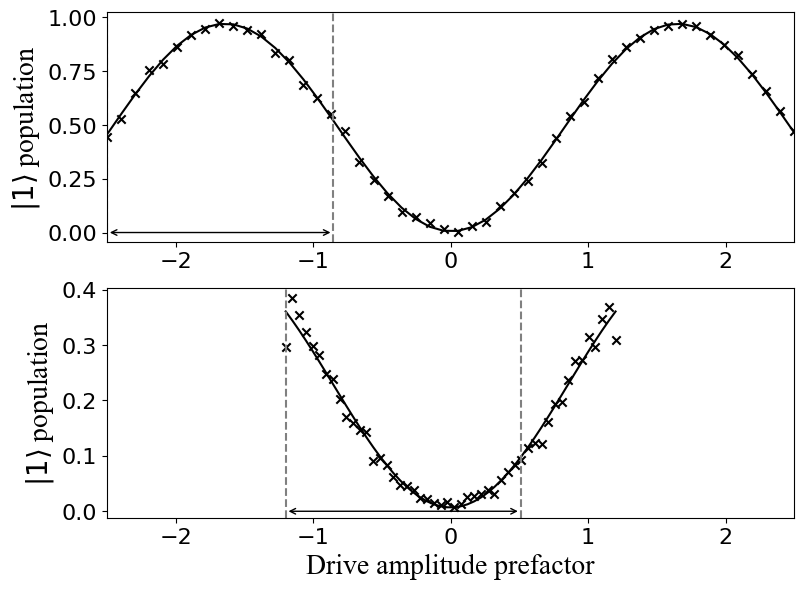

In [211]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False, sharey=False, figsize=(8, 6))
font = {"fontname": "Times New Roman", "size": 20}

# Good calibration
ax1.scatter(good_cal_x, good_cal_y, marker="x", color="black")
good_fit_params, good_y_fit, conv = fit_function(
    np.array(good_cal_x),
    np.array(good_cal_y),
    lambda x, A, B, drive_period, phi: (
        A * np.cos(2 * np.pi * x / drive_period - phi) + B
    ),
    [1, 1, 4, 0.5],
)
ax1.plot(good_cal_x, good_y_fit, color="black")
good_drive_period = good_fit_params[2]  # get period of rabi oscillation
ax1.axvline(good_cal_x[0] + good_drive_period / 2, linestyle="--", color="gray")
ax1.axvline(good_cal_x[0], linestyle="--", color="gray")
ax1.annotate(
    "",
    xy=(good_cal_x[0], 0),
    xytext=(good_cal_x[0] + good_drive_period / 2, 0),
    arrowprops=dict(arrowstyle="<->"),
    color="gray"
)

# Bad calibration
ax2.scatter(bad_cal_x, bad_cal_y, marker="x", color="black")
bad_fit_params, bad_y_fit, conv = fit_function(
    np.array(bad_cal_x),
    np.array(bad_cal_y),
    lambda x, A, B, drive_period, phi: (
        A * np.cos(2 * np.pi * x / drive_period - phi) + B
    ),
    [1, 1, 4, 0.5],
)
ax2.plot(bad_cal_x, bad_y_fit, color="black")
bad_drive_period = bad_fit_params[2]  # get period of rabi oscillation
ax2.axvline(bad_cal_x[0] + bad_drive_period / 2, linestyle="--", color="gray")
ax2.axvline(bad_cal_x[0], linestyle="--", color="gray")
ax2.annotate(
    "",
    xy=(bad_cal_x[0], 0),
    xytext=(bad_cal_x[0] + bad_drive_period / 2, 0),
    arrowprops=dict(arrowstyle="<->"),
    color="gray"
)

ax2.set_xlabel("Drive amplitude prefactor", **font)

ax1.set_ylabel(r"$|1\rangle$ population", **font)
ax2.set_ylabel(r"$|1\rangle$ population", **font)

ax1.xaxis.set_tick_params(labelsize=16)
ax1.yaxis.set_tick_params(labelsize=16)

ax2.xaxis.set_tick_params(labelsize=16)
ax2.yaxis.set_tick_params(labelsize=16)

ax1.set_xlim(good_cal_x[0], good_cal_x[-1])
ax2.set_xlim(good_cal_x[0], good_cal_x[-1])

plt.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0.2)

plt.savefig("calibration_figure.pdf", format="pdf", dpi=300, bbox_inches="tight")